# Corporate Loan Pricing with Machine Learning

**Author:** Thanh Vy Vo

This notebook predicts the all-in drawn spread of syndicated corporate loan facilities from loan terms and lagged borrower, market and macro information assumed to be available at origination, compares four model families on validation data, evaluates the validation-selected specification once on later loans, and interprets what it learned.

### Contents

1. Inspect the Data
2. Split and Prepare the Data
3. Estimate and Select Models
4. Evaluate Later Loans
5. Interpret the Results (ends with an assessment)

An appendix at the end lists the reproducibility checks and exports the results.

### Conventions

> - **Units.** The target `spread_bps` is the DealScan all-in drawn spread in basis points (bps). 100 bps = 1 percentage point, so 150 bps = 1.50 percentage points. The spread includes annual fees; it is not the loan's total interest rate. Every error measure (RMSE, MAE, differences, partial-dependence values) is in bps.
> - **Predictors.** Exactly 20 predictors in four blocks: loan and industry (6), borrower financials (9), market history (2) and macroeconomy (3). Identifiers, dates, the split label and the target are never used as predictors.
> - **Splits.** The supplied chronological split is used as given: training 1996-2014, validation 2015-2017, test 2018-2019. Packages do not cross splits; borrowers can.
> - **Timing.** Accounting values are assumed available six months after the fiscal period end and statements are at most 18 months old, so they are 6 to 18 months old at origination, market history ends the month before the loan, and macro values end two months before the loan.
> - **Data use.** Target-based exploration uses training loans only. Validation targets are used for model selection, test targets only after the specification is frozen.
> - **Framing.** This is a retrospective pricing exercise on a selected linked sample, not a verified live underwriting backtest, and not an automated lending decision. Results are predictive associations, not causal effects: contract terms are negotiated jointly with the spread.

**Sources.** DealScan loan extract linked to Compustat annual accounting data and CRSP monthly market data, plus the FRED series CPIAUCSL, UNRATE and FEDFUNDS (frozen 2 Oct 2026). Place `Corporate_Loan_Pricing_1996_2019.csv` in the `data/` folder and run the cells from top to bottom.

In [1]:
import json
import hashlib
import os
import platform
import sys
import warnings

import numpy as np
import pandas as pd
import scipy
import scipy.stats
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import cycler
from IPython.display import HTML, display

from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# unseen categories are detected and reported explicitly in Section 2
warnings.filterwarnings("ignore", message="Found unknown categories in columns", category=UserWarning)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)

VERSIONS = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "sklearn": sklearn.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}
print("Library versions: " + ", ".join(f"{k} {v}" for k, v in VERSIONS.items()))


Library versions: python 3.14.8, pandas 3.0.6, numpy 2.5.3, sklearn 1.9.1, scipy 1.18.1, matplotlib 3.11.2


In [2]:
SEED = 42
DATA_FILE = "data/Corporate_Loan_Pricing_1996_2019.csv"
BLOCKS = {
    "loan": ["log_loan_amount", "maturity_months", "secured", "loan_type", "loan_purpose", "industry"],
    "borrower": ["log_assets", "debt_assets", "cash_assets", "sales_assets", "operating_income_assets",
                 "net_income_assets", "tangible_assets", "current_ratio", "interest_coverage"],
    "market": ["return_12m", "volatility_12m"],
    "macro": ["inflation_yoy_pct", "unemployment_pct", "fedfunds_pct"],
}
BLOCK_LABELS = {"loan": "Loan and industry", "borrower": "Borrower financials",
                "market": "Market history", "macro": "Macroeconomy"}
FEATURES = BLOCKS["loan"] + BLOCKS["borrower"] + BLOCKS["market"] + BLOCKS["macro"]   # 20 predictors
CAT_FEATURES = ["secured", "loan_type", "loan_purpose", "industry"]
NUM_FEATURES = [f for f in FEATURES if f not in CAT_FEATURES]                      # 16
AUDIT_COLS = ["facility_id", "package_id", "gvkey", "loan_date", "split", "accounting_date",
              "accounting_available_date", "market_month", "macro_month"]
CAP_COLS = ["debt_assets", "sales_assets", "operating_income_assets", "net_income_assets",
            "current_ratio", "interest_coverage", "return_12m", "volatility_12m"]
CAP_Q = (0.01, 0.99)
MIN_CATEGORY_COUNT = 20
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0, 100000.0]
GBM_FIXED = {"n_estimators": 300, "learning_rate": 0.05, "subsample": 1.0,
             "loss": "squared_error", "max_features": None, "random_state": SEED}
GBM_GRID = [(2, 100), (2, 20), (3, 100), (3, 20), (5, 100), (5, 20)]   # (max_depth, min_samples_leaf)
PERM_REPEATS = 20
PD_QUANTILES = [round(0.05 * k, 2) for k in range(1, 20)]             # 0.05 .. 0.95, 19 points
N_TOP_NUMERIC = 4
FAMILIES = ["constant", "ols", "ridge", "gbm"]
THRESH = {
    "tie_tol": 1e-9,          # bps; exact-tie tolerance in selection
    "similar_rel": 0.02,      # |RMSE_A - RMSE_B| / RMSE_B below this -> "similar"
    "large_rel": 0.10,        # "substantially" needs a clear verdict and |rel| >= this
    "boot_n": 2000, "boot_level": 0.95,
    "subgroup_rel": 0.05,     # seen vs new borrowers; 2019 vs 2018
    "joint_rel": 0.10,        # block joint importance vs sum of individual importances
    "pd_flat_bps": 2.0,       # |PD(q90) - PD(q10)| at or below -> flat
    "ridge_flat_bps": 1.0,    # |Ridge coefficient per training SD| at or below -> near zero
    "raw_flat_bps": 5.0,      # |top-quintile median - bottom-quintile median| at or below -> flat
    "monotone_rho": 0.90,     # |Spearman(grid, PD)| at or above -> monotone
    "large_error_mult": 2.0,
    "under_share_hi": 0.60, "under_share_lo": 0.40,
    "corr_report": 0.50,      # report training Spearman pairs with |rho| >= this
    "material_count": 3,      # subgroup profile: |observed - expected| count at or above this ...
    "material_rel": 0.50,     # ... and observed >= (1 + this) x expected (or <= (1 - this) x expected)
    "tie_share": 0.01,        # quintile ties flagged when this share of values occurs in more than one quintile
}
SOURCE_FACTS = {"raw_rows": 160041, "raw_facilities": 8896, "outside_years": 991, "non_usd_usa": 275,
                "boundary_omitted": 25, "market_ambiguous_source": 862, "n_facilities": 7605,
                "n_train": 4157, "n_validation": 2169, "n_test": 1279, "market_missing": 2370,
                "market_missing_pct": 31.16, "current_ratio_missing": 1479,
                "current_ratio_missing_pct": 19.45, "maturity_missing": 12}
SOURCE_FACTS["rows_per_facility"] = SOURCE_FACTS["raw_rows"] / SOURCE_FACTS["raw_facilities"]
# plain names and units for figures and tables: (name, unit)
FEATURE_LABELS = {
    "log_loan_amount": ("Log facility amount", "ln USD"), "maturity_months": ("Maturity", "months"),
    "secured": ("Secured status", "category"), "loan_type": ("Loan type", "category"),
    "loan_purpose": ("Loan purpose", "category"), "industry": ("Industry", "SIC sector"),
    "log_assets": ("Log total assets", "ln USD millions"), "debt_assets": ("Debt / assets", "ratio"),
    "cash_assets": ("Cash / assets", "ratio"), "sales_assets": ("Sales / assets", "ratio"),
    "operating_income_assets": ("Operating income / assets", "ratio"),
    "net_income_assets": ("Net income / assets", "ratio"), "tangible_assets": ("Net PP&E / assets", "ratio"),
    "current_ratio": ("Current ratio", "current assets / current liabilities"),
    "interest_coverage": ("Interest coverage", "operating income / interest expense"),
    "return_12m": ("Stock return, prior 12 months", "decimal"),
    "volatility_12m": ("Stock volatility, prior 12 months", "annualized, decimal"),
    "inflation_yoy_pct": ("CPI inflation, year on year", "percent"),
    "unemployment_pct": ("Unemployment rate", "percent"), "fedfunds_pct": ("Federal funds rate", "percent"),
}
assert list(FEATURE_LABELS) == FEATURES


def feature_label(f, unit=True):   # "Log total assets (ln USD millions)" or "Log total assets"
    name, u = FEATURE_LABELS[f]
    return f"{name} ({u})" if unit else name


SYMLOG_FEATURES = {"interest_coverage", "current_ratio"}   # long-tailed ratios: symlog x axis in the direction figure

np.random.seed(SEED)


def plain_number(v):
    """Format a setting without scientific notation."""
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, (int, np.integer)):
        return f"{v:,d}"
    if isinstance(v, (float, np.floating)):
        return np.format_float_positional(float(v), trim="-")
    return str(v)


def plain_list(values):
    return ", ".join(plain_number(v) for v in values)


_gbm_fixed_text = ", ".join(f"{k} = {plain_number(v) if v is not None else 'None'}" for k, v in GBM_FIXED.items())
_thresh_meaning = {
    "tie_tol": "Largest RMSE difference (bps) treated as an exact tie when selecting",
    "similar_rel": "Relative RMSE difference below which two models are called about equal",
    "large_rel": "Relative RMSE difference needed to call a clear difference substantial",
    "boot_n": "Bootstrap resamples of borrowers",
    "boot_level": "Bootstrap interval level",
    "subgroup_rel": "Relative RMSE difference separating subgroups or years (seen vs new borrowers, 2019 vs 2018)",
    "joint_rel": "Relative gap between joint block importance and the sum of single-feature importances",
    "pd_flat_bps": "Partial-dependence change (10th to 90th percentile, bps) at or below which a feature is called flat",
    "ridge_flat_bps": "Ridge coefficient per training SD (bps) at or below which it is called near zero",
    "raw_flat_bps": "Top minus bottom quintile median spread (bps) at or below which a feature is called flat",
    "monotone_rho": "Absolute Spearman correlation of grid and partial dependence for a monotone curve",
    "large_error_mult": "Large error: absolute test error above this multiple of the preferred validation RMSE",
    "under_share_hi": "Share of underpredicted large errors at or above which they are mostly underpredictions",
    "under_share_lo": "Share of underpredicted large errors at or below which they are mostly overpredictions",
    "corr_report": "Smallest absolute training Spearman correlation reported between numeric features",
    "material_count": "Large-error profile: smallest gap between observed and expected facility counts to call a difference material",
    "material_rel": "Large-error profile: observed count must also exceed expected by this fraction (or fall short by it)",
    "tie_share": "Share of training values occurring in more than one quintile at or above which quintile ties are disclosed",
}
SETTINGS = [
    ("SEED", plain_number(SEED), "Random seed used everywhere"),
    ("DATA_FILE", DATA_FILE, "Data file, read once (relative to the notebook folder)"),
    ("FEATURES", f"{len(FEATURES)} predictors", "Loan 6, borrower 9, market 2, macro 3"),
    ("NUM_FEATURES / CAT_FEATURES", f"{len(NUM_FEATURES)} numeric / {len(CAT_FEATURES)} categorical", "Predictor types"),
    ("CAP_COLS", plain_list(CAP_COLS), "Predictors capped at fitting-sample percentiles"),
    ("CAP_Q", plain_list(CAP_Q), "Lower and upper cap percentiles (fractions)"),
    ("MIN_CATEGORY_COUNT", plain_number(MIN_CATEGORY_COUNT), "Categories with fewer fitting-sample facilities are pooled"),
    ("RIDGE_ALPHAS", plain_list(RIDGE_ALPHAS), "Ridge penalty grid"),
    ("GBM_FIXED", _gbm_fixed_text, "Fixed boosting settings"),
    ("GBM_GRID", "; ".join(f"depth {d}, min leaf {l}" for d, l in GBM_GRID), "Boosting grid (max_depth, min_samples_leaf)"),
    ("PERM_REPEATS", plain_number(PERM_REPEATS), "Permutation-importance repeats"),
    ("PD_QUANTILES", f"{plain_number(PD_QUANTILES[0])} to {plain_number(PD_QUANTILES[-1])} in steps of 0.05 ({len(PD_QUANTILES)} points)",
     "Partial-dependence grid quantiles"),
    ("N_TOP_NUMERIC", plain_number(N_TOP_NUMERIC), "Numeric features examined for direction"),
    ("FEATURE_LABELS", f"{len(FEATURE_LABELS)} labels (table below)", "Plain names and units used in figures and tables"),
    ("SYMLOG_FEATURES", ", ".join(sorted(SYMLOG_FEATURES)), "Long-tailed ratios drawn on a symmetric log axis in the direction figure"),
] + [(f"THRESH['{k}']", plain_number(v), _thresh_meaning[k]) for k, v in THRESH.items()]
print(f"Settings ({len(SETTINGS)} rows)")
sys.stdout.flush()
display(HTML(pd.DataFrame(SETTINGS, columns=["name", "value", "meaning"]).to_html(index=False)))
print("Plain feature labels (name and unit)")
sys.stdout.flush()
display(HTML(pd.DataFrame([(f, *FEATURE_LABELS[f]) for f in FEATURES], columns=["column", "plain name", "unit"]).to_html(index=False)))


Settings (33 rows)


name,value,meaning
SEED,42,Random seed used everywhere
DATA_FILE,data/Corporate_Loan_Pricing_1996_2019.csv,"Data file, read once (relative to the notebook folder)"
FEATURES,20 predictors,"Loan 6, borrower 9, market 2, macro 3"
NUM_FEATURES / CAT_FEATURES,16 numeric / 4 categorical,Predictor types
CAP_COLS,"debt_assets, sales_assets, operating_income_assets, net_income_assets, current_ratio, interest_coverage, return_12m, volatility_12m",Predictors capped at fitting-sample percentiles
CAP_Q,"0.01, 0.99",Lower and upper cap percentiles (fractions)
MIN_CATEGORY_COUNT,20,Categories with fewer fitting-sample facilities are pooled
RIDGE_ALPHAS,"0.01, 0.1, 1, 10, 100, 1000, 10000, 100000",Ridge penalty grid
GBM_FIXED,"n_estimators = 300, learning_rate = 0.05, subsample = 1, loss = squared_error, max_features = None, random_state = 42",Fixed boosting settings
GBM_GRID,"depth 2, min leaf 100; depth 2, min leaf 20; depth 3, min leaf 100; depth 3, min leaf 20; depth 5, min leaf 100; depth 5, min leaf 20","Boosting grid (max_depth, min_samples_leaf)"


Plain feature labels (name and unit)


column,plain name,unit
log_loan_amount,Log facility amount,ln USD
maturity_months,Maturity,months
secured,Secured status,category
loan_type,Loan type,category
loan_purpose,Loan purpose,category
industry,Industry,SIC sector
log_assets,Log total assets,ln USD millions
debt_assets,Debt / assets,ratio
cash_assets,Cash / assets,ratio
sales_assets,Sales / assets,ratio


In [3]:
# ---- style -------------------------------------------------------------------------------
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "legend.fontsize": 8, "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": MUTED,
    "xtick.color": INK2, "ytick.color": INK2, "axes.prop_cycle": cycler(color=CATEGORICAL),
})
FAMILY_COLORS = {"constant": "#898781", "ols": "#1baf7a", "ridge": "#2a78d6", "gbm": "#eb6834", "ridge_log": "#eda100"}
SPLIT_COLORS = {"train": "#2a78d6", "validation": "#eda100", "test": "#eb6834"}
BLOCK_COLORS = {"loan": "#2a78d6", "borrower": "#eb6834", "market": "#1baf7a", "macro": "#eda100"}
YEAR_COLORS = {2018: "#2a78d6", 2019: "#eb6834"}

DISPLAY = {"constant": "Constant (fitting-sample mean)", "ols": "OLS", "ridge": "Ridge",
           "gbm": "Gradient boosting", "ridge_log": "Ridge, log target (supplementary)"}


def spec_label(family, params=None):
    """Readable name of a specification, e.g. Ridge (alpha = 100) or Gradient boosting (depth 3, min leaf 100)."""
    params = params or {}
    if family in ("ridge", "ridge_log") and "alpha" in params:
        name = DISPLAY[family] if family == "ridge" else "Ridge, log target"
        return f"{name} (alpha = {float(params['alpha']):g})"
    if family == "gbm" and "max_depth" in params:
        return f"{DISPLAY[family]} (depth {int(params['max_depth'])}, min leaf {int(params['min_samples_leaf'])})"
    return DISPLAY[family]


# ---- metrics -------------------------------------------------------------------------------
def rmse(y, pred):
    y, pred = np.asarray(y, dtype=float), np.asarray(pred, dtype=float)
    return float(np.sqrt(np.mean((y - pred) ** 2)))


def mae(y, pred):
    y, pred = np.asarray(y, dtype=float), np.asarray(pred, dtype=float)
    return float(np.mean(np.abs(y - pred)))


def r2_oos(y, pred, y_benchmark_mean):
    """1 - squared error of the model / squared error of the fitting-sample mean benchmark."""
    y, pred = np.asarray(y, dtype=float), np.asarray(pred, dtype=float)
    return float(1.0 - np.sum((y - pred) ** 2) / np.sum((y - y_benchmark_mean) ** 2))


def quintile_summary(x, y):
    """Rank-based quintiles of x (non-missing values, file order) with the median of y in each.

    Returns a DataFrame with columns quintile (1..5), n, x_min, x_max, median; the top-minus-bottom
    median difference is out.loc[4, "median"] - out.loc[0, "median"].
    """
    d = pd.DataFrame({"x": np.asarray(x, dtype=float), "y": np.asarray(y, dtype=float)}).dropna(subset=["x"])
    q = pd.qcut(d["x"].rank(method="first"), 5, labels=False)
    d = d.assign(quintile=q.to_numpy() + 1)
    out = d.groupby("quintile").agg(n=("y", "size"), x_min=("x", "min"), x_max=("x", "max"), median=("y", "median"))
    return out.reset_index()


# ---- borrower-clustered bootstrap ------------------------------------------------------------
def cluster_bootstrap_rmse_diff(y, pred_a, pred_b, groups, n_boot=THRESH["boot_n"], level=THRESH["boot_level"], seed=SEED):
    y, pa, pb = (np.asarray(v, dtype=float) for v in (y, pred_a, pred_b))
    codes, uniq = pd.factorize(np.asarray(groups), sort=True)
    G = len(uniq)
    sse_a = np.bincount(codes, weights=(y - pa) ** 2, minlength=G)
    sse_b = np.bincount(codes, weights=(y - pb) ** 2, minlength=G)
    n_g = np.bincount(codes, minlength=G).astype(float)
    rng = np.random.default_rng(seed)
    W = np.vstack([np.bincount(r, minlength=G) for r in rng.integers(0, G, size=(n_boot, G))]).astype(float)
    diffs = np.sqrt(W @ sse_a / (W @ n_g)) - np.sqrt(W @ sse_b / (W @ n_g))
    ra, rb = rmse(y, pa), rmse(y, pb)
    d = ra - rb
    lo, hi = np.quantile(diffs, [(1 - level) / 2, 1 - (1 - level) / 2])
    return {"rmse_a": ra, "rmse_b": rb, "d": d, "rel_b": d / rb, "rel_a": d / ra, "lo": float(lo), "hi": float(hi),
            "share_a_lower": float(np.mean(diffs < 0)), "share_b_lower": float(np.mean(diffs > 0)),
            "n_clusters": int(G), "n_obs": int(len(y)), "n_boot": int(n_boot)}


def pair_verdict(res):
    if abs(res["rel_b"]) < THRESH["similar_rel"]:
        return "similar"
    if res["d"] < 0:
        return "lower_clear" if res["hi"] < 0 else "lower_uncertain"
    return "higher_clear" if res["lo"] > 0 else "higher_uncertain"


PAIR_LABELS = {"similar": "about equal (within 2%)", "lower_clear": "A clearly lower RMSE",
               "lower_uncertain": "A lower, not robust", "higher_clear": "A clearly higher RMSE",
               "higher_uncertain": "A higher, not robust"}


# ---- output helpers ----------------------------------------------------------------------------
def show(obj, digits=1, index=True, caption=None):
    """Flush printed text, then display a table with fixed-point numbers (no scientific notation)."""
    sys.stdout.flush()
    if caption:
        print(caption)
        sys.stdout.flush()
    if isinstance(obj, pd.Series):
        obj = obj.to_frame()
    if isinstance(obj, pd.DataFrame):
        display(HTML(obj.to_html(index=index, float_format=lambda v: f"{(round(v, digits) + 0.0):,.{digits}f}", na_rep="")))
    else:
        display(obj)


def save_fig(fig, name):
    """Save figures/<name>.png, flush text output, display the figure once and close it."""
    os.makedirs("figures", exist_ok=True)
    fig.savefig(os.path.join("figures", name + ".png"), bbox_inches="tight", facecolor="white")
    sys.stdout.flush()
    display(fig)
    plt.close(fig)


def to_py(obj):
    """Convert numpy, pandas and tuple objects to plain JSON-ready Python objects."""
    if isinstance(obj, dict):
        return {str(k): to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_py(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return [to_py(v) for v in obj.tolist()]
    if isinstance(obj, pd.Series):
        return {str(k): to_py(v) for k, v in obj.items()}
    if isinstance(obj, (pd.Timestamp,)):
        return obj.strftime("%Y-%m-%d")
    if isinstance(obj, (np.bool_, bool)):
        return bool(obj)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    return obj


# ---- results dictionary ----------------------------------------------------------------------------
R = {key: {} for key in ["meta", "s1", "s2", "s3", "freeze", "s4", "s5", "boot", "checks", "verdicts"]}
R["meta"].update({
    "author": "Thanh Vy Vo",
    "seed": SEED,
    "versions": dict(VERSIONS),
    "units": {"target": "spread_bps",
              "note": "All-in drawn spread in basis points (100 bps = 1 percentage point); it includes annual fees and is not the total interest rate."},
    "features": {k: list(v) for k, v in BLOCKS.items()},
    "constants": {
        "cap_q": list(CAP_Q), "cap_cols": list(CAP_COLS), "min_category_count": MIN_CATEGORY_COUNT,
        "ridge_alphas": list(RIDGE_ALPHAS),
        "gbm_fixed": {k: GBM_FIXED[k] for k in ("n_estimators", "learning_rate", "subsample")},
        "gbm_grid": [{"max_depth": d, "min_samples_leaf": l} for d, l in GBM_GRID],
        "perm_repeats": PERM_REPEATS, "pd_quantiles": list(PD_QUANTILES), "n_top_numeric": N_TOP_NUMERIC,
    },
    "thresholds": dict(THRESH),
    "source_facts": dict(SOURCE_FACTS),
})
print(f"Helpers and palettes defined; results dictionary started with {len(R)} groups: " + ", ".join(R))


Helpers and palettes defined; results dictionary started with 10 groups: meta, s1, s2, s3, freeze, s4, s5, boot, checks, verdicts


## 1. Inspect the Data

This section describes the sample: how many facilities, packages and borrowers it holds, how the facilities are spread over time, where predictor values are missing, and how the spread behaves in the training period.

**Data-use rule.** Counts, dates, identifiers and missingness are computed on all rows, because they involve no spread values. Every output that uses spread values (the spread distribution, annual median spreads, group comparisons and quintile summaries) uses the **training rows only** (loans originated 1996-2014). Annual median spreads for 2015-2019 are not shown here; they appear in Section 4, after the test evaluation. The only spread values read in this section are training spreads.

In [4]:
# Read the data once. The target is moved into a private store; test-period targets stay locked.
raw = pd.read_csv(DATA_FILE, parse_dates=["loan_date"])
assert raw.shape == (SOURCE_FACTS["n_facilities"], 30), raw.shape
assert set(raw.columns) == set(AUDIT_COLS + ["spread_bps"] + FEATURES)
MISSING_FULL = raw.isna().sum()
_Y = raw.pop("spread_bps")
df = raw
del raw
df["year"] = df["loan_date"].dt.year          # helper column, never a predictor

IS_TRAIN = df["split"].eq("train")
IS_VALID = df["split"].eq("validation")
IS_TEST = df["split"].eq("test")
IS_DEV = IS_TRAIN | IS_VALID

_MASKS = {"train": IS_TRAIN, "validation": IS_VALID, "dev": IS_DEV, "test": IS_TEST,
          "all": pd.Series(True, index=df.index)}
_LOCK = {"unlocked": False, "digest": None, "test_reads": 0}


def get_target(sample):
    """Return a copy of the target for a sample; test-period targets stay locked until the freeze."""
    if sample not in _MASKS:
        raise ValueError(f"unknown sample: {sample!r}")
    if sample in ("test", "all"):
        if not _LOCK["unlocked"]:
            raise RuntimeError("Test-period targets are locked until the frozen evaluation.")
        _LOCK["test_reads"] += 1
    return _Y.loc[_MASKS[sample]].copy()


def unlock_test(digest):
    """Open the test-period targets once, after the specification has been frozen."""
    assert not _LOCK["unlocked"], "test targets are already unlocked"
    _LOCK.update(unlocked=True, digest=digest)


n_by_split = [int(IS_TRAIN.sum()), int(IS_VALID.sum()), int(IS_TEST.sum())]
facility_unique = bool(df["facility_id"].is_unique)
counts_ok = (len(df) == SOURCE_FACTS["n_facilities"]
             and n_by_split == [SOURCE_FACTS["n_train"], SOURCE_FACTS["n_validation"], SOURCE_FACTS["n_test"]]
             and int(MISSING_FULL["spread_bps"]) == 0)
R["checks"]["facility_id_unique"] = facility_unique
R["checks"]["documented_counts_match"] = bool(counts_ok)
assert facility_unique, "facility_id is not unique"
assert counts_ok, "row or split counts differ from the documented sample"

R["s1"].update({
    "n_rows": int(len(df)),
    "n_facilities": int(df["facility_id"].nunique()),
    "n_packages": int(df["package_id"].nunique()),
    "n_borrowers": int(df["gvkey"].nunique()),
    "facility_id_unique": facility_unique,
    "date_min": df["loan_date"].min().strftime("%Y-%m-%d"),
    "date_max": df["loan_date"].max().strftime("%Y-%m-%d"),
    "n_missing_target_full": int(MISSING_FULL["spread_bps"]),
})
print(f"Loaded {len(df):,} facilities with {df.shape[1] - 1} columns (target held back); "
      f"{R['s1']['n_packages']:,} packages and {R['s1']['n_borrowers']:,} borrowers; "
      f"{R['s1']['date_min']} to {R['s1']['date_max']}.")
print(f"Split sizes (train / validation / test): {n_by_split[0]:,} / {n_by_split[1]:,} / {n_by_split[2]:,}. "
      "Facility identifiers are unique and no target is missing.")
print("Test-period targets are locked: reading them before the freeze raises an error.")


Loaded 7,605 facilities with 29 columns (target held back); 6,972 packages and 3,864 borrowers; 1996-01-02 to 2019-12-30.
Split sizes (train / validation / test): 4,157 / 2,169 / 1,279. Facility identifiers are unique and no target is missing.
Test-period targets are locked: reading them before the freeze raises an error.


### Sample overview

In [5]:
# Sample overview: counts and identifiers on all rows (no spread values involved).
s1_split_counts = df["split"].value_counts()
s1_pkg_sizes = df.groupby("package_id").size()
s1_bor_sizes = df.groupby("gvkey").size()

R["s1"]["counts_by_split"] = {s: int(s1_split_counts[s]) for s in ["train", "validation", "test"]}
R["s1"]["packages"] = {"n_multi_facility": int((s1_pkg_sizes > 1).sum()), "max_facilities": int(s1_pkg_sizes.max())}
R["s1"]["borrowers_multi"] = {"n_multi": int((s1_bor_sizes > 1).sum()),
                              "median_facilities": float(s1_bor_sizes.median()),
                              "max_facilities": int(s1_bor_sizes.max())}

s1_overview_rows = [
    ("Facilities (rows)", f"{R['s1']['n_facilities']:,}"),
    ("Packages", f"{R['s1']['n_packages']:,}"),
    ("Borrowers (gvkey)", f"{R['s1']['n_borrowers']:,}"),
    ("First loan date", R["s1"]["date_min"]),
    ("Last loan date", R["s1"]["date_max"]),
    ("Facilities in training / validation / test",
     " / ".join(f"{R['s1']['counts_by_split'][s]:,}" for s in ["train", "validation", "test"])),
    ("Packages with more than one facility", f"{R['s1']['packages']['n_multi_facility']:,}"),
    ("Most facilities in one package", f"{R['s1']['packages']['max_facilities']:,}"),
    ("Borrowers with more than one facility", f"{R['s1']['borrowers_multi']['n_multi']:,}"),
    ("Median facilities per borrower", f"{R['s1']['borrowers_multi']['median_facilities']:.1f}"),
    ("Most facilities for one borrower", f"{R['s1']['borrowers_multi']['max_facilities']:,}"),
]
show(pd.DataFrame(s1_overview_rows, columns=["measure", "value"]), index=False, caption="Sample overview (all rows)")
print(f"Facility identifiers are unique: {R['s1']['facility_id_unique']} "
      f"({df['facility_id'].nunique():,} distinct identifiers for {len(df):,} rows).")


Sample overview (all rows)


measure,value
Facilities (rows),"7,605"
Packages,"6,972"
Borrowers (gvkey),"3,864"
First loan date,1996-01-02
Last loan date,2019-12-30
Facilities in training / validation / test,"4,157 / 2,169 / 1,279"
Packages with more than one facility,485
Most facilities in one package,9
Borrowers with more than one facility,"1,548"
Median facilities per borrower,1.0


Facility identifiers are unique: True (7,605 distinct identifiers for 7,605 rows).


### Observations by year

In [6]:
# Observations by year and split (all rows; counts only).
s1_year_split = (df.groupby(["year", "split"]).size().rename("facilities").reset_index()
                   .sort_values(["year", "split"]).reset_index(drop=True))
s1_counts_year = df.groupby("year").size()
R["s1"]["counts_by_year"] = {str(int(y)): int(n) for y, n in s1_counts_year.items()}
R["s1"]["coverage"] = {"n_2012": int(s1_counts_year[2012]), "n_2013": int(s1_counts_year[2013]),
                       "ratio_2013_2012": float(s1_counts_year[2013] / s1_counts_year[2012])}
# Training-period coverage (training rows are years 1996-2014; counts only, no spread values).
s1_train_year = df.loc[IS_TRAIN].groupby("year").size()
s1_early = s1_train_year.loc[1996:2012]
s1_n_late = int(s1_train_year.loc[2013:2014].sum())
R["s1"]["coverage"].update({
    "n_train_1996_2012": int(s1_early.sum()),
    "n_train_2013_2014": s1_n_late,
    "share_train_2013_2014": float(s1_n_late / int(IS_TRAIN.sum())),
    "min_count_1996_2012": int(s1_early.min()), "min_year_1996_2012": int(s1_early.idxmin()),
    "max_count_1996_2012": int(s1_early.max()), "max_year_1996_2012": int(s1_early.idxmax()),
})
assert R["s1"]["coverage"]["n_train_1996_2012"] + s1_n_late == int(IS_TRAIN.sum())
assert s1_counts_year.index.min() == 1996 and s1_counts_year.index.max() == 2019 and len(s1_counts_year) == 24

show(s1_year_split, index=False, caption="Facilities by origination year and split (all rows)")
print(f"Facilities per year range from {s1_counts_year.min():,} to {s1_counts_year.max():,}; "
      f"2012 has {R['s1']['coverage']['n_2012']:,} and 2013 has {R['s1']['coverage']['n_2013']:,} facilities "
      f"(ratio {R['s1']['coverage']['ratio_2013_2012']:.2f}).")
_cv = R["s1"]["coverage"]
print(f"Training period: {_cv['n_train_1996_2012']:,} facilities originated 1996-2012 "
      f"({_cv['min_count_1996_2012']:,} in {_cv['min_year_1996_2012']} to {_cv['max_count_1996_2012']:,} in {_cv['max_year_1996_2012']} per year) "
      f"and {_cv['n_train_2013_2014']:,} in 2013-2014 ({100 * _cv['share_train_2013_2014']:.1f}% of the training rows).")


Facilities by origination year and split (all rows)


year,split,facilities
1996,train,188
1997,train,290
1998,train,218
1999,train,167
2000,train,215
2001,train,160
2002,train,142
2003,train,116
2004,train,118
2005,train,128


Facilities per year range from 74 to 878; 2012 has 118 and 2013 has 828 facilities (ratio 7.02).
Training period: 2,457 facilities originated 1996-2012 (74 in 2009 to 290 in 1997 per year) and 1,700 in 2013-2014 (40.9% of the training rows).


### Missing values

Blank cells are genuine unavailable values, not zeros. They are counted here on all rows and handled in Section 2.

In [7]:
# Missingness on all rows (no spread values involved).
s1_miss = pd.DataFrame({"column": MISSING_FULL.index, "n_missing": MISSING_FULL.to_numpy().astype(int),
                        "pct_missing": 100.0 * MISSING_FULL.to_numpy() / len(df)})
R["s1"]["missing_full"] = {r.column: {"n": int(r.n_missing), "pct": float(r.pct_missing)} for r in s1_miss.itertuples()}
show(s1_miss, digits=2, index=False, caption="Missing values by column (all rows)")

s1_miss_split = df[NUM_FEATURES].isna().groupby(df["split"]).sum().T[["train", "validation", "test"]].astype(int)
R["s1"]["missing_by_split"] = {c: {s: int(s1_miss_split.loc[c, s]) for s in ["train", "validation", "test"]}
                               for c in NUM_FEATURES}
show(s1_miss_split, caption="Missing values in the 16 numeric predictors, by split")

# Documented missingness: every other column listed here has no missing values.
s1_expected = {c: 0 for c in ["spread_bps", "loan_date", "facility_id", "package_id", "gvkey", "split",
                              "macro_month", "inflation_yoy_pct", "unemployment_pct", "fedfunds_pct"]}
s1_expected.update({"return_12m": SOURCE_FACTS["market_missing"], "volatility_12m": SOURCE_FACTS["market_missing"],
                    "current_ratio": SOURCE_FACTS["current_ratio_missing"],
                    "maturity_months": SOURCE_FACTS["maturity_missing"]})
s1_miss_ok = all(int(MISSING_FULL[c]) == v for c, v in s1_expected.items())
s1_miss_ok = bool(s1_miss_ok
                  and round(R["s1"]["missing_full"]["return_12m"]["pct"], 2) == SOURCE_FACTS["market_missing_pct"]
                  and round(R["s1"]["missing_full"]["current_ratio"]["pct"], 2) == SOURCE_FACTS["current_ratio_missing_pct"])
R["checks"]["documented_missing_match"] = s1_miss_ok
assert s1_miss_ok, "missing counts differ from the documented values"
print(f"Documented missing counts confirmed: {SOURCE_FACTS['market_missing']:,} for each market variable "
      f"({SOURCE_FACTS['market_missing_pct']:.2f}%), {SOURCE_FACTS['current_ratio_missing']:,} for `current_ratio` "
      f"({SOURCE_FACTS['current_ratio_missing_pct']:.2f}%), {SOURCE_FACTS['maturity_missing']} for `maturity_months`; "
      "none for the target, loan dates, identifiers, split label or macro variables.")
print(f"Documented preparation facts: the loan file behind this extract held {SOURCE_FACTS['raw_rows']:,} rows for "
      f"{SOURCE_FACTS['raw_facilities']:,} distinct facility identifiers ({SOURCE_FACTS['rows_per_facility']:.1f} rows per facility); "
      f"{SOURCE_FACTS['outside_years']:,} facilities outside 1996-2019, {SOURCE_FACTS['non_usd_usa']:,} not both USD-denominated and "
      f"syndicated in the USA and {SOURCE_FACTS['boundary_omitted']:,} later-split facilities of packages that crossed a split "
      f"boundary were dropped, leaving {SOURCE_FACTS['n_facilities']:,}.")


Missing values by column (all rows)


column,n_missing,pct_missing
facility_id,0,0.00
package_id,0,0.00
gvkey,0,0.00
loan_date,0,0.00
split,0,0.00
accounting_date,116,1.53
accounting_available_date,116,1.53
market_month,2370,31.16
macro_month,0,0.00
spread_bps,0,0.00


Missing values in the 16 numeric predictors, by split


split,train,validation,test
log_loan_amount,0,0,0
maturity_months,11,1,0
log_assets,134,46,20
debt_assets,152,48,22
cash_assets,135,46,20
sales_assets,144,50,21
operating_income_assets,340,183,97
net_income_assets,144,50,21
tangible_assets,350,172,87
current_ratio,821,424,234


Documented missing counts confirmed: 2,370 for each market variable (31.16%), 1,479 for `current_ratio` (19.45%), 12 for `maturity_months`; none for the target, loan dates, identifiers, split label or macro variables.
Documented preparation facts: the loan file behind this extract held 160,041 rows for 8,896 distinct facility identifiers (18.0 rows per facility); 991 facilities outside 1996-2019, 275 not both USD-denominated and syndicated in the USA and 25 later-split facilities of packages that crossed a split boundary were dropped, leaving 7,605.


### Why repeated facilities would distort the analysis

The data documentation states that the loan file behind this extract held 160,041 rows for only 8,896 distinct facility identifiers (about 18.0 rows per facility), because rows were repeated through the link to accounting records. Used as they come, such repeated rows would distort the analysis in four ways:

- **Overweighting.** A facility with many accounting rows would count many times in every average and every fit, so borrowers with long accounting histories would dominate and the fitted relationships would describe them rather than the typical facility.
- **Duplicated targets.** Each repeat carries the same spread again, so the row count overstates the number of independent pricing decisions. Sample size and the apparent precision of error measures would be inflated, and the rows would be strongly dependent on each other.
- **Leakage across splits.** Under a random split or cross-validation, copies of one facility could fall in both the fitting and the evaluation sample, so a model would be scored on spreads it had already seen and its out-of-sample accuracy would look stronger than it is.
- **Mis-timed accounting.** Each facility should be matched to one set of statements, the latest one available under the timing rule; the extra rows would pair the loan with other fiscal periods, some older than allowed or not yet available at origination, which breaks the timing rules.

In the data used here each facility appears once: all 7,605 facility identifiers are unique. The data preparation collapsed the repeated rows only after package, borrower, origination date and facility terms agreed, and it dropped 991 facilities outside 1996-2019, 275 that are not both USD-denominated and syndicated in the USA, and 25 later-split facilities of packages that crossed a split boundary, leaving 7,605.

Some dependence remains even with one row per facility: 485 of 6,972 packages contain more than one facility (up to 9), and 1,548 of 3,864 borrowers have several facilities (up to 41). Rows are therefore not independent evidence, which is why the comparisons in Sections 3 and 4 resample whole borrowers rather than single rows.

### Spread distribution (training loans)

Summary statistics and histograms of `spread_bps` for the training rows only.

Spread distribution, training loans 1996-2014


statistic,training loans
n (training facilities),"4,157"
mean (bps),196.5
standard deviation (bps),117.7
minimum (bps),4.2
1st percentile (bps),22.5
5th percentile (bps),40.0
25th percentile (bps),125.0
median (bps),175.0
75th percentile (bps),250.0
95th percentile (bps),405.0


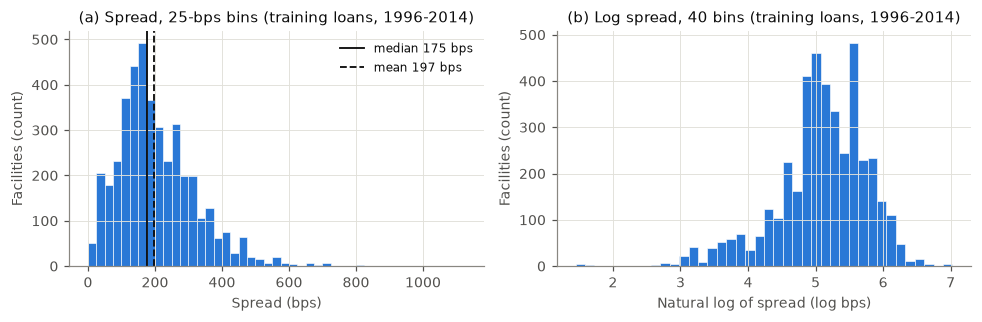

In [8]:
# Training-period spread distribution (training rows only).
s1_ytr = get_target("train")
s1_q = s1_ytr.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
R["s1"]["train_target"] = {
    "n": int(len(s1_ytr)), "mean": float(s1_ytr.mean()), "sd": float(s1_ytr.std()), "min": float(s1_ytr.min()),
    "p01": float(s1_q[0.01]), "p05": float(s1_q[0.05]), "p25": float(s1_q[0.25]), "median": float(s1_q[0.5]),
    "p75": float(s1_q[0.75]), "p95": float(s1_q[0.95]), "p99": float(s1_q[0.99]), "max": float(s1_ytr.max()),
    "skew": float(s1_ytr.skew()), "log_skew": float(np.log(s1_ytr).skew()),
}
s1_tt = R["s1"]["train_target"]
s1_stats = [("n (training facilities)", f"{s1_tt['n']:,}"), ("mean (bps)", f"{s1_tt['mean']:.1f}"),
            ("standard deviation (bps)", f"{s1_tt['sd']:.1f}"), ("minimum (bps)", f"{s1_tt['min']:.1f}"),
            ("1st percentile (bps)", f"{s1_tt['p01']:.1f}"), ("5th percentile (bps)", f"{s1_tt['p05']:.1f}"),
            ("25th percentile (bps)", f"{s1_tt['p25']:.1f}"), ("median (bps)", f"{s1_tt['median']:.1f}"),
            ("75th percentile (bps)", f"{s1_tt['p75']:.1f}"), ("95th percentile (bps)", f"{s1_tt['p95']:.1f}"),
            ("99th percentile (bps)", f"{s1_tt['p99']:.1f}"), ("maximum (bps)", f"{s1_tt['max']:.1f}"),
            ("skewness of the spread", f"{s1_tt['skew']:.2f}"), ("skewness of the log spread", f"{s1_tt['log_skew']:.2f}")]
show(pd.DataFrame(s1_stats, columns=["statistic", "training loans"]), index=False,
     caption="Spread distribution, training loans 1996-2014")

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.0))
axes[0].hist(s1_ytr, bins=np.arange(0, s1_ytr.max() + 25, 25), color=CATEGORICAL[0], edgecolor="white", linewidth=0.4)
axes[0].axvline(s1_tt["median"], color=INK, linewidth=1.2, label=f"median {s1_tt['median']:.0f} bps")
axes[0].axvline(s1_tt["mean"], color=INK, linewidth=1.2, linestyle="--", label=f"mean {s1_tt['mean']:.0f} bps")
axes[0].set_xlabel("Spread (bps)")
axes[0].set_ylabel("Facilities (count)")
axes[0].set_title("(a) Spread, 25-bps bins (training loans, 1996-2014)")
axes[0].legend(frameon=False)
axes[1].hist(np.log(s1_ytr), bins=40, color=CATEGORICAL[0], edgecolor="white", linewidth=0.4)
axes[1].set_xlabel("Natural log of spread (log bps)")
axes[1].set_ylabel("Facilities (count)")
axes[1].set_title("(b) Log spread, 40 bins (training loans, 1996-2014)")
fig.tight_layout()
save_fig(fig, "spread_distribution_train")


### Annual medians and counts

Median spreads use training loans (1996-2014); facility counts use all years and are coloured by split.

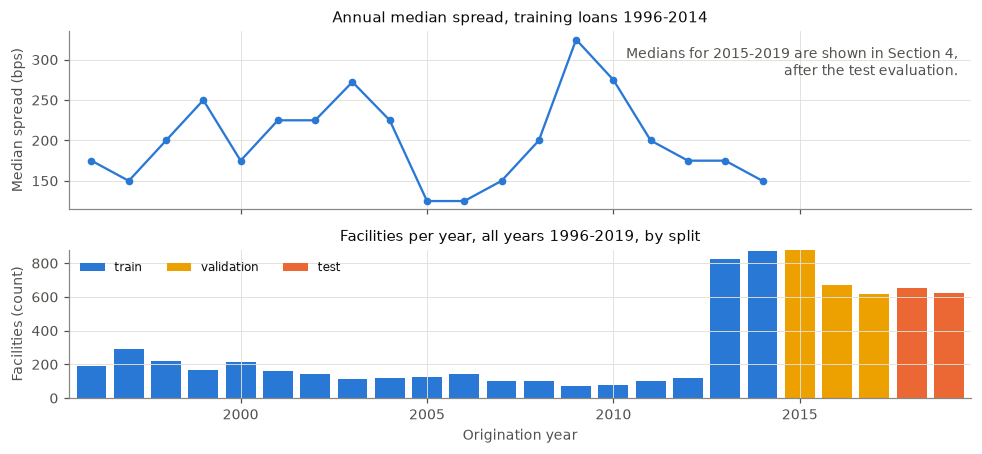

Medians are plotted for 19 training years (1996-2014); counts cover 24 years (1996-2019).
Annual training medians run from 125.0 to 325.0 bps (highest in 2009).


In [9]:
# Annual median spread (training rows only) and annual facility counts (all rows).
s1_train_year = df.loc[IS_TRAIN, "year"]
s1_med_year = s1_ytr.groupby(s1_train_year).median()
R["s1"]["train_median_by_year"] = {str(int(y)): float(v) for y, v in s1_med_year.items()}
assert int(s1_med_year.index.max()) == 2014 and int(s1_med_year.index.min()) == 1996

s1_cnt = df.groupby(["year", "split"]).size().unstack(fill_value=0).reindex(columns=["train", "validation", "test"], fill_value=0)

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(9.0, 4.2), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
ax_top.plot(s1_med_year.index, s1_med_year.to_numpy(), color=SPLIT_COLORS["train"], marker="o", markersize=4)
ax_top.set_ylabel("Median spread (bps)")
ax_top.set_title("Annual median spread, training loans 1996-2014")
ax_top.text(0.985, 0.92, "Medians for 2015-2019 are shown in Section 4,\nafter the test evaluation.",
            transform=ax_top.transAxes, ha="right", va="top", color=INK2)
bottom = np.zeros(len(s1_cnt))
for split in ["train", "validation", "test"]:
    ax_bot.bar(s1_cnt.index, s1_cnt[split].to_numpy(), bottom=bottom, color=SPLIT_COLORS[split], label=split, width=0.8)
    bottom = bottom + s1_cnt[split].to_numpy()
ax_bot.set_ylabel("Facilities (count)")
ax_bot.set_xlabel("Origination year")
ax_bot.set_title("Facilities per year, all years 1996-2019, by split")
ax_bot.legend(frameon=False, ncol=3, loc="upper left")
ax_bot.set_xlim(1995.4, 2019.6)
fig.tight_layout()
save_fig(fig, "annual_counts_median_train")
print(f"Medians are plotted for {len(s1_med_year)} training years (1996-2014); counts cover {len(s1_cnt)} years (1996-2019).")
_s1_hi = int(s1_med_year.idxmax())
print(f"Annual training medians run from {s1_med_year.min():.1f} to {s1_med_year.max():.1f} bps (highest in {_s1_hi}).")


### Spread by secured status and by broad loan type (training loans)

Broad loan type is a display grouping of `loan_type` used only here: "Revolver (1 yr or longer)" is `Revolver/Line >= 1 Yr.`; "Short-term revolver / 364-day" is `Revolver/Line < 1 Yr.` and `364-Day Facility`; "Term loan" is `Term Loan`, `Term Loan A`, `Term Loan B`, `Term Loan C` and `Delay Draw Term Loan`; "Other" is every remaining level. It is never a model input.

Training spreads (bps) by group, 1996-2014


grouping,group,n,median,mean
Secured status,Yes,2199,225.0,249.4
Secured status,No,941,125.0,123.1
Secured status,Unknown,1017,137.0,150.0
Broad loan type,Revolver (1 yr or longer),3528,175.0,198.5
Broad loan type,Short-term revolver / 364-day,438,112.5,155.6
Broad loan type,Term loan,116,225.0,261.8
Broad loan type,Other,75,230.0,239.6


Median spread of secured (Yes) minus unsecured (No) training loans: +100.0 bps.


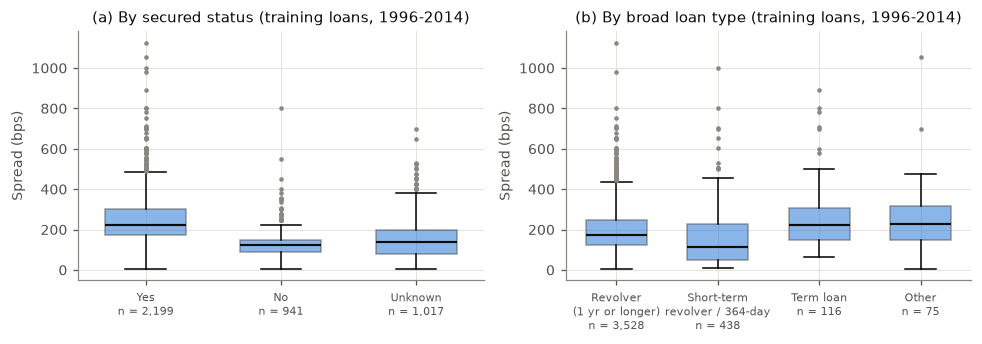

In [10]:
# Group comparisons on training rows only.
S1_BROAD_ORDER = ["Revolver (1 yr or longer)", "Short-term revolver / 364-day", "Term loan", "Other"]
S1_BROAD_MAP = {"Revolver/Line >= 1 Yr.": S1_BROAD_ORDER[0],
                "Revolver/Line < 1 Yr.": S1_BROAD_ORDER[1], "364-Day Facility": S1_BROAD_ORDER[1],
                "Term Loan": S1_BROAD_ORDER[2], "Term Loan A": S1_BROAD_ORDER[2], "Term Loan B": S1_BROAD_ORDER[2],
                "Term Loan C": S1_BROAD_ORDER[2], "Delay Draw Term Loan": S1_BROAD_ORDER[2]}

s1_tr = df.loc[IS_TRAIN, ["secured", "loan_type"]].assign(spread_bps=s1_ytr)
s1_tr["broad_type"] = s1_tr["loan_type"].map(S1_BROAD_MAP).fillna(S1_BROAD_ORDER[3])


def s1_group_stats(frame, col, order):
    out = {}
    for level in order:
        v = frame.loc[frame[col] == level, "spread_bps"]
        out[level] = {"n": int(len(v)), "median": float(v.median()), "mean": float(v.mean())}
    return out


R["s1"]["train_by_secured"] = s1_group_stats(s1_tr, "secured", ["Yes", "No", "Unknown"])
R["s1"]["train_by_broad_type"] = s1_group_stats(s1_tr, "broad_type", S1_BROAD_ORDER)
s1_gap = R["s1"]["train_by_secured"]["Yes"]["median"] - R["s1"]["train_by_secured"]["No"]["median"]
R["s1"]["secured_median_gap_yes_minus_no"] = float(s1_gap)
if s1_gap > THRESH["raw_flat_bps"]:
    R["verdicts"]["s1_secured"] = "secured_higher"
elif s1_gap < -THRESH["raw_flat_bps"]:
    R["verdicts"]["s1_secured"] = "secured_lower"
else:
    R["verdicts"]["s1_secured"] = "similar"
assert sum(v["n"] for v in R["s1"]["train_by_secured"].values()) == len(s1_tr)
assert sum(v["n"] for v in R["s1"]["train_by_broad_type"].values()) == len(s1_tr)

s1_group_table = pd.DataFrame(
    [{"grouping": "Secured status", "group": k, **v} for k, v in R["s1"]["train_by_secured"].items()]
    + [{"grouping": "Broad loan type", "group": k, **v} for k, v in R["s1"]["train_by_broad_type"].items()])
show(s1_group_table, index=False, caption="Training spreads (bps) by group, 1996-2014")
print(f"Median spread of secured (Yes) minus unsecured (No) training loans: {s1_gap:+.1f} bps.")

S1_TICK = {S1_BROAD_ORDER[0]: "Revolver\n(1 yr or longer)", S1_BROAD_ORDER[1]: "Short-term\nrevolver / 364-day"}
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.2))
for ax, col, order, stats, title in [
        (axes[0], "secured", ["Yes", "No", "Unknown"], R["s1"]["train_by_secured"], "(a) By secured status"),
        (axes[1], "broad_type", S1_BROAD_ORDER, R["s1"]["train_by_broad_type"], "(b) By broad loan type")]:
    data = [s1_tr.loc[s1_tr[col] == g, "spread_bps"].to_numpy() for g in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, flierprops={"markersize": 2, "markerfacecolor": MUTED, "markeredgecolor": MUTED},
                    medianprops={"color": INK, "linewidth": 1.4})
    for patch in bp["boxes"]:
        patch.set(facecolor=CATEGORICAL[0], alpha=0.55, edgecolor=INK2)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels([S1_TICK.get(g, g) + f"\nn = {stats[g]['n']:,}" for g in order], fontsize=7.5)
    ax.set_ylabel("Spread (bps)")
    ax.set_title(title + " (training loans, 1996-2014)")
fig.tight_layout()
save_fig(fig, "spread_by_group_train")


### Quintile summaries (training loans)

Training facilities are ranked on each feature (non-missing values only) and cut into five equal-sized groups. Tied values are assigned to groups in file order, which follows the origination date. The table shows the median spread per group and the difference between the top and bottom groups.

In [11]:
# Quintile medians of the training spread for four pre-specified features (training rows only).
S1_QUINT_FEATURES = ["log_assets", "debt_assets", "volatility_12m", "maturity_months"]
R["s1"]["quintiles"] = {}
R["verdicts"]["s1_relationships"] = {}
s1_qt_rows = []
for f in S1_QUINT_FEATURES:
    qs = quintile_summary(df.loc[IS_TRAIN, f].to_numpy(), s1_ytr.to_numpy())
    assert len(qs) == 5
    delta = float(qs.loc[4, "median"] - qs.loc[0, "median"])
    R["s1"]["quintiles"][f] = {"medians": [float(v) for v in qs["median"]], "counts": [int(v) for v in qs["n"]],
                               "x_min": [float(v) for v in qs["x_min"]], "x_max": [float(v) for v in qs["x_max"]],
                               "delta": delta}
    # Share of non-missing training values equal to the most common value, and the share whose value
    # occurs in more than one rank-based quintile (file order breaks ties); the flag uses the latter.
    _xv = df.loc[IS_TRAIN, f].dropna()
    _mode = _xv.value_counts().index[0]
    R["s1"]["quintiles"][f]["top_value_share"] = float((_xv == _mode).mean())
    _qq = pd.qcut(_xv.rank(method="first"), 5, labels=False)
    R["s1"]["quintiles"][f]["straddle_share"] = float((_qq.groupby(_xv).transform("nunique") > 1).mean())
    R["s1"]["quintiles"][f]["ties_split"] = bool(R["s1"]["quintiles"][f]["straddle_share"] >= THRESH["tie_share"])
    if delta > THRESH["raw_flat_bps"]:
        R["verdicts"]["s1_relationships"][f] = "increasing"
    elif delta < -THRESH["raw_flat_bps"]:
        R["verdicts"]["s1_relationships"][f] = "decreasing"
    else:
        R["verdicts"]["s1_relationships"][f] = "flat"
    s1_qt_rows.append(qs.assign(feature=f)[["feature", "quintile", "n", "x_min", "x_max", "median"]])
s1_qt = pd.concat(s1_qt_rows, ignore_index=True).rename(columns={"x_min": "feature min", "x_max": "feature max",
                                                                  "median": "median spread (bps)"})
show(s1_qt, digits=2, index=False, caption="Median training spread by feature quintile (quintile 1 = lowest values)")
for f in S1_QUINT_FEATURES:
    _d = R['s1']['quintiles'][f]['delta']
    _top = "top above bottom" if _d > 0 else "top below bottom" if _d < 0 else "top equal to bottom"
    _med = R['s1']['quintiles'][f]['medians']
    _up = all(a <= b for a, b in zip(_med, _med[1:]))
    _down = all(a >= b for a, b in zip(_med, _med[1:]))
    _mono = "" if (_up or _down) else "; medians not monotone"
    print(f"`{f}`: top-minus-bottom quintile median spread {_d:+.1f} bps "
          f"({_top}{_mono}), {sum(R['s1']['quintiles'][f]['counts']):,} training facilities with a value.")
    if R['s1']['quintiles'][f]['ties_split']:
        print(f"  {R['s1']['quintiles'][f]['straddle_share'] * 100:.1f}% of these training facilities have a `{f}` value shared with "
              "facilities in another quintile; tied facilities are assigned to quintiles in file order, which follows the origination date.")


Median training spread by feature quintile (quintile 1 = lowest values)


feature,quintile,n,feature min,feature max,median spread (bps)
log_assets,1,805,-1.89,4.86,255.00
log_assets,2,804,4.86,6.16,200.00
log_assets,3,805,6.16,7.38,175.00
log_assets,4,804,7.38,8.76,150.00
log_assets,5,805,8.76,14.48,125.00
debt_assets,1,801,0.00,0.07,175.00
debt_assets,2,801,0.07,0.20,150.00
debt_assets,3,801,0.20,0.33,150.00
debt_assets,4,801,0.33,0.47,175.00
debt_assets,5,801,0.47,2.56,200.00


`log_assets`: top-minus-bottom quintile median spread -130.0 bps (top below bottom), 4,023 training facilities with a value.
`debt_assets`: top-minus-bottom quintile median spread +25.0 bps (top above bottom; medians not monotone), 4,005 training facilities with a value.
`volatility_12m`: top-minus-bottom quintile median spread +150.0 bps (top above bottom), 2,758 training facilities with a value.
`maturity_months`: top-minus-bottom quintile median spread -37.5 bps (top below bottom; medians not monotone), 4,146 training facilities with a value.
  61.7% of these training facilities have a `maturity_months` value shared with facilities in another quintile; tied facilities are assigned to quintiles in file order, which follows the origination date.


- **Size and period.** 7,605 facilities in 6,972 packages for 3,864 borrowers, originated from 2 January 1996 to 30 December 2019. The supplied split has 4,157 training (1996-2014), 2,169 validation (2015-2017) and 1,279 test (2018-2019) facilities.
- **Coverage over time.** Facilities per year range from 74 in 2009 to 878 in 2015. The count jumps from 118 in 2012 to 828 in 2013 (a ratio of 7.02). The extract gives no reason, so this is read as a change in sample coverage, not as a change in lending volume.
- **Spread, training loans only (bps).** Mean 196.5, median 175.0, standard deviation 117.7; the 5th to 95th percentile range is 40.0 to 405.0. The distribution is right-skewed (skewness 1.42): a minority of high-spread loans stretches the upper tail. Annual training medians run from 125.0 to 325.0 (highest in 2009). The spread is the all-in drawn spread, which includes annual fees; it is not the total interest rate.
- **Missing values.** Both market-history variables are missing for 2,370 facilities (31.16%) and `current_ratio` for 1,479 (19.45%); the target, dates, identifiers, split label and macro variables are never missing. Market history is missing when the security link is ambiguous or the 12-month return history is incomplete. Accounting ratios are missing when no eligible statement is matched (116 facilities have none) or when a component is missing or the denominator is not positive, which accounts for most of the 1,479 missing `current_ratio` values. 12 maturities are missing (by construction, nonpositive maturities are set to missing). The supplied CRSP extract starts in 1996 and the return window needs the 12 months before origination, so market history is available for 0.0% of the 188 facilities originated in 1996 against 73.8% in 1997. These gaps follow the construction rules of the data documentation, so they are not random; Section 2 keeps the facilities and adds missing-value indicators next to median imputation.

### Two economic relationships and one limitation

**1. Secured status.** *Training data:* median spread 225.0 bps for secured loans (n = 2,199) against 125.0 bps for unsecured loans (n = 941), a gap of +100.0 bps; loans with unknown status (n = 1,017) have a median of 137.0 bps. *Channels:* Two channels pull in opposite directions. Collateral lowers the lender's loss if the borrower defaults, which on its own would lower the spread; but lenders tend to ask riskier borrowers for collateral, so secured loans go to riskier borrowers on average, which goes with higher spreads. The training sample has secured loans priced higher, which is consistent with the second channel (collateral requested from riskier borrowers) outweighing the first; it does not measure the effect of collateral.

**2. Borrower size (`log_assets`).** *Expected channel:* larger borrowers are usually more diversified and have wider access to capital markets, which points to lower credit risk and a lower spread. *Training data:* by quintile of borrower size, the top-quintile median is 130.0 bps below the bottom-quintile median and the five medians move in one direction (255.0, 200.0, 175.0, 150.0 and 125.0 bps). This agrees with the expected sign.

These are unadjusted training medians, so they mix the contributions of correlated features, for example `log_assets` and `log_loan_amount`, whose training Spearman correlation is 0.77 (Section 5 correlation table); they describe associations and are not causal effects. For the other pre-specified features, the training quintiles compare as follows. Leverage (`debt_assets`): *expected channel:* higher leverage is usually priced as higher credit risk. *Training data:* the top-quintile median is 25.0 bps above the bottom-quintile median; the five medians are 175.0, 150.0, 150.0, 175.0 and 200.0 bps. The top-versus-bottom comparison agrees with the expected sign, but the medians are not monotone. Equity volatility (`volatility_12m`): *expected channel:* higher equity volatility signals higher risk. *Training data:* the top-quintile median is 150.0 bps above the bottom-quintile median and the five medians move in one direction (125.0, 150.0, 175.0, 200.0 and 275.0 bps). This agrees with the expected sign. Maturity (`maturity_months`): *expected channel:* longer maturities add risk but are also granted to stronger borrowers, so the expected sign is ambiguous. *Training data:* the top-quintile median is 37.5 bps below the bottom-quintile median, but the five medians (187.5, 225.0, 175.0, 150.0 and 150.0 bps) are not monotone. No sign was expected in advance, so this is reported as found. Of the training loans with a `maturity_months` value, 61.7% have a value shared with loans in another quintile; tied loans are assigned to quintiles in file order, which follows the origination date, so these quintiles partly sort loans by year.

**One limitation of the selected sample.** The facilities are those that could be linked to Compustat accounting data (and, for market history, to CRSP securities), in USD and syndicated in the USA. This is a selected linked sample, not the universe of corporate loans: borrowers without linked public accounting data are absent (many private firms, for example), so conclusions apply to borrowers that can be linked. The sample is also uneven over time: each year from 1996 to 2012 has between 74 (2009) and 290 (1997) facilities, against 828 and 872 in 2013 and 2014, and the count jumps from 118 in 2012 to 828 in 2013 for reasons the extract does not give. That jump is a change in sample coverage, not a change in lending volume. The two years 2013 and 2014 supply 1,700 of the 4,157 training facilities (40.9%), against 2,457 for the 17 years from 1996 to 2012, so the recent years carry a large weight in every fit to the training rows.

## 2. Split and Prepare the Data

This section uses the supplied chronological split without changing it, verifies it, and defines the preprocessing that every model shares. The section first records the preprocessing fitted on the training rows and then checks the split.

**Split table.** The split label in the data assigns each facility to training (loans originated 1996-2014), validation (2015-2017) or test (2018-2019). The tables below check that the three periods do not overlap in time, that each label agrees with the origination year, that no package of facilities appears in more than one split, and how many borrowers in later splits also appear earlier. They also audit the timing rules for the predictors: accounting values become available six months after the fiscal period end, market history ends the month before the loan, and macro values end two months before the loan.

**Preprocessing.** Every statistic used to transform the predictors is estimated on the fitting sample only: the training rows while models are compared, and the training plus validation rows when the selected specifications are refitted before the test evaluation. No rows are dropped. Numeric predictors with very large values (ratios with small denominators, compounded returns and annualized volatility) are capped at the 1st and 99th percentiles of the fitting sample. Missing numeric values are filled with the fitting-sample median, and a missing-value indicator is added for each numeric predictor that has missing values in the fitting sample (predictors with identical missing patterns share one indicator). Categorical predictors are one-hot encoded with the most frequent level as the reference; levels with fewer than 20 fitting-sample facilities are pooled into one "other (rare or unseen)" column, which also receives levels that never appeared in the fitting sample (a predictor with no rare levels has no pooled column and sends an unseen level to its reference level). Numeric predictors are standardized for OLS and Ridge but not for boosting. The target is never capped or removed.

### Preprocessing fitted on the training rows

The next outputs show what the shared preprocessing learns from the training rows: the caps, the number of design columns and the reference level of each categorical feature.

In [12]:
# Frames for the three fitting samples; the test frame carries no target yet.
train = df.loc[IS_TRAIN].assign(spread_bps=get_target("train"))
valid = df.loc[IS_VALID].assign(spread_bps=get_target("validation"))
dev = df.loc[IS_DEV].assign(spread_bps=get_target("dev"))
test_X = df.loc[IS_TEST].copy()
y_train, y_valid, y_dev = train["spread_bps"], valid["spread_bps"], dev["spread_bps"]

assert (len(train), len(valid), len(test_X)) == (SOURCE_FACTS["n_train"], SOURCE_FACTS["n_validation"], SOURCE_FACTS["n_test"])
assert dev.index.equals(df.index[IS_DEV]) and dev.index.equals(train.index.append(valid.index))
assert (y_dev > 0).all()
rows_ok = (len(train) + len(valid) + len(test_X) == SOURCE_FACTS["n_facilities"]
           and len(dev) == SOURCE_FACTS["n_train"] + SOURCE_FACTS["n_validation"])
R["checks"]["no_rows_dropped"] = bool(rows_ok)
assert rows_ok
print(f"Training {len(train):,} rows, validation {len(valid):,}, development (training + validation) {len(dev):,}, "
      f"test {len(test_X):,} rows (no target attached). No rows were dropped and every development spread is positive.")


Training 4,157 rows, validation 2,169, development (training + validation) 6,326, test 1,279 rows (no target attached). No rows were dropped and every development spread is positive.


In [13]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    """Clip chosen columns to percentiles of the fitting sample; NaN is preserved."""

    def __init__(self, cap_cols=(), q=(0.01, 0.99)):
        self.cap_cols = cap_cols
        self.q = q

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.lo_, self.hi_, self.n_below_, self.n_above_ = {}, {}, {}, {}
        for c in self.cap_cols:
            if c in X.columns:
                v = X[c].to_numpy(float)
                lo, hi = np.nanquantile(v, self.q, method="linear")
                self.lo_[c], self.hi_[c] = float(lo), float(hi)
                self.n_below_[c] = int(np.sum(v < lo))
                self.n_above_[c] = int(np.sum(v > hi))
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.lo_:
            X[c] = X[c].clip(self.lo_[c], self.hi_[c])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_in_, dtype=object)


class DedupMissingIndicator(BaseEstimator, TransformerMixin):
    """One missing-value indicator per column with any NaN; identical NaN patterns are collapsed."""

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.keep_, self.groups_, kept_patterns = [], {}, {}
        for c in X.columns:
            pattern = X[c].isna().to_numpy()
            if not pattern.any():
                continue
            match = next((k for k, p in kept_patterns.items() if np.array_equal(p, pattern)), None)
            if match is None:
                self.keep_.append(c)
                self.groups_[c] = [c]
                kept_patterns[c] = pattern
            else:
                self.groups_[match].append(c)
        return self

    def transform(self, X):
        return X[self.keep_].isna().to_numpy(dtype=float)

    def get_feature_names_out(self, input_features=None):
        return np.asarray([f"missing_{c}" for c in self.keep_], dtype=object)


def reference_levels(X_fit, cat_cols):
    """Most frequent level of each categorical column in the fitting sample (ties alphabetical)."""
    ref = {}
    for c in cat_cols:
        counts = X_fit[c].value_counts()
        top = counts[counts == counts.max()].index.tolist()
        ref[c] = sorted(top)[0]
    return ref


def make_preprocessor(X_fit, num_cols, cat_cols, scale):
    """Unfitted column transformer: cap, impute (median), optional scaling, indicators, one-hot."""
    ref = reference_levels(X_fit, cat_cols)
    steps = [("cap", QuantileCapper([c for c in CAP_COLS if c in num_cols], CAP_Q)),
             ("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    parts = [("num", Pipeline(steps), list(num_cols)), ("miss", DedupMissingIndicator(), list(num_cols))]
    if len(cat_cols) > 0:
        parts.append(("cat", OneHotEncoder(drop=[ref[c] for c in cat_cols], min_frequency=MIN_CATEGORY_COUNT,
                                           handle_unknown="infrequent_if_exist", sparse_output=False,
                                           dtype=float), list(cat_cols)))
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=True)


class SmearedLogRidge(BaseEstimator, RegressorMixin):
    """Ridge on the log spread; predictions are back-transformed with the smearing factor."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        num_cols = [c for c in X.columns if c in NUM_FEATURES]
        cat_cols = [c for c in X.columns if c in CAT_FEATURES]
        self.pipe_ = Pipeline([("prep", make_preprocessor(X, num_cols, cat_cols, scale=True)),
                               ("model", Ridge(alpha=self.alpha))])
        log_y = np.log(np.asarray(y, dtype=float))
        self.pipe_.fit(X, log_y)
        self.smearing_ = float(np.mean(np.exp(log_y - self.pipe_.predict(X))))
        return self

    def predict(self, X):
        return self.smearing_ * np.exp(self.pipe_.predict(X))

    def predict_naive(self, X):
        return np.exp(self.pipe_.predict(X))


def fit_spec(family, params, X_fit, y_fit):
    """Fit one specification on a DataFrame whose columns follow the FEATURES order."""
    num_cols = [c for c in X_fit.columns if c in NUM_FEATURES]
    cat_cols = [c for c in X_fit.columns if c in CAT_FEATURES]
    if family == "constant":
        model = Pipeline([("model", DummyRegressor(strategy="mean"))])
    elif family == "ols":
        model = Pipeline([("prep", make_preprocessor(X_fit, num_cols, cat_cols, scale=True)),
                          ("model", LinearRegression())])
    elif family == "ridge":
        model = Pipeline([("prep", make_preprocessor(X_fit, num_cols, cat_cols, scale=True)),
                          ("model", Ridge(alpha=params["alpha"]))])
    elif family == "gbm":
        model = Pipeline([("prep", make_preprocessor(X_fit, num_cols, cat_cols, scale=False)),
                          ("model", GradientBoostingRegressor(max_depth=params["max_depth"],
                                                              min_samples_leaf=params["min_samples_leaf"],
                                                              **GBM_FIXED))])
    elif family == "ridge_log":
        model = SmearedLogRidge(alpha=params["alpha"])
    else:
        raise ValueError(f"unknown family: {family!r}")
    return model.fit(X_fit, y_fit)


def describe_preprocessor(ct):
    """Plain-dict summary of a fitted preprocessor (caps, medians, scaling, indicators, levels)."""
    num = ct.named_transformers_["num"]
    cap, imp = num.named_steps["cap"], num.named_steps["impute"]
    num_names = list(cap.feature_names_in_)
    out = {
        "caps": {c: {"lo": cap.lo_[c], "hi": cap.hi_[c], "n_below": cap.n_below_[c], "n_above": cap.n_above_[c]}
                 for c in cap.lo_},
        "medians": {c: float(m) for c, m in zip(num_names, imp.statistics_)},
        "scaler": {},
        "indicator_groups": {k: list(v) for k, v in ct.named_transformers_["miss"].groups_.items()},
        "reference_levels": {},
        "infrequent_levels": {},
    }
    if "scale" in num.named_steps:
        sc = num.named_steps["scale"]
        out["scaler"] = {c: {"mean": float(m), "scale": float(s)} for c, m, s in zip(num_names, sc.mean_, sc.scale_)}
    if "cat" in ct.named_transformers_:
        ohe = ct.named_transformers_["cat"]
        cats = list(ct.transformers_[2][2])
        out["reference_levels"] = {c: str(d) for c, d in zip(cats, ohe.drop)}
        infreq = ohe.infrequent_categories_
        out["infrequent_levels"] = {c: ([str(v) for v in infreq[i]] if infreq[i] is not None else [])
                                    for i, c in enumerate(cats)}
    names = [str(n) for n in ct.get_feature_names_out()]
    out["n_cols"] = len(names)
    out["feature_names"] = names
    return out


print("Preprocessing and model-fitting tools defined: QuantileCapper, DedupMissingIndicator, "
      "reference_levels, make_preprocessor, SmearedLogRidge, fit_spec, describe_preprocessor.")


Preprocessing and model-fitting tools defined: QuantileCapper, DedupMissingIndicator, reference_levels, make_preprocessor, SmearedLogRidge, fit_spec, describe_preprocessor.


In [14]:
# Preprocessing fitted on the training rows only, as used during model selection.
PREP_TRAIN = make_preprocessor(train[FEATURES], NUM_FEATURES, CAT_FEATURES, scale=True).fit(train[FEATURES])
prep_tree_train = make_preprocessor(train[FEATURES], NUM_FEATURES, CAT_FEATURES, scale=False).fit(train[FEATURES])
desc = describe_preprocessor(PREP_TRAIN)
desc["n_cols_tree"] = int(prep_tree_train.transform(train[FEATURES]).shape[1])
R["s2"]["prep_train"] = desc

imputer_train = PREP_TRAIN.named_transformers_["num"].named_steps["impute"]
medians_ok = bool(np.allclose(imputer_train.statistics_, train[NUM_FEATURES].median().to_numpy(), rtol=0, atol=1e-12))
R["checks"]["medians_unaffected_by_caps"] = medians_ok
assert medians_ok

design_train = np.column_stack([np.ones(len(train)), PREP_TRAIN.transform(train[FEATURES])])
rank_train = int(np.linalg.matrix_rank(design_train))
R["s2"]["ols_rank_train"] = rank_train
R["s2"]["ols_cond_train"] = float(np.linalg.cond(design_train))
R["checks"]["ols_full_rank_train"] = bool(rank_train == design_train.shape[1])
assert R["checks"]["ols_full_rank_train"]

show(pd.DataFrame({"predictor": list(desc["caps"]),
                   "lower cap": [v["lo"] for v in desc["caps"].values()],
                   "upper cap": [v["hi"] for v in desc["caps"].values()],
                   "training values below": [v["n_below"] for v in desc["caps"].values()],
                   "training values above": [v["n_above"] for v in desc["caps"].values()]}),
     digits=3, index=False, caption="Caps from the training rows (1st and 99th percentiles)")
print(f"Training-fit design matrix: {desc['n_cols']} columns ({len(NUM_FEATURES)} numeric, "
      f"{len(desc['indicator_groups'])} missing-value indicators, "
      f"{desc['n_cols'] - len(NUM_FEATURES) - len(desc['indicator_groups'])} category columns); "
      f"rank with intercept {rank_train} of {design_train.shape[1]} columns, condition number {R['s2']['ols_cond_train']:.1f}.")
print("Reference levels: " + "; ".join(f"{c} = {v}" for c, v in desc["reference_levels"].items()))
print("Medians equal the raw non-missing training medians; the linear design matrix has full column rank.")


Caps from the training rows (1st and 99th percentiles)


predictor,lower cap,upper cap,training values below,training values above
debt_assets,0.000,1.015,0,41
sales_assets,0.041,4.492,41,41
operating_income_assets,-0.545,0.417,39,39
net_income_assets,-0.855,0.284,41,41
current_ratio,0.302,8.396,34,34
interest_coverage,-88.249,880.523,35,35
return_12m,-0.831,2.738,28,28
volatility_12m,0.101,1.794,28,28


Training-fit design matrix: 51 columns (16 numeric, 10 missing-value indicators, 25 category columns); rank with intercept 52 of 52 columns, condition number 179.0.
Reference levels: secured = Yes; loan_type = Revolver/Line >= 1 Yr.; loan_purpose = Corp. purposes; industry = Manufacturing
Medians equal the raw non-missing training medians; the linear design matrix has full column rank.


### Split checks

The tables below verify the supplied split: chronology, package and borrower overlap, the timing rules, and the categorical levels seen in each sample.

### Split table and chronology

In [15]:
# Split table and chronology checks (dates and labels only; no spread values).
S2_SPLITS = ["train", "validation", "test"]
s2_grp = df.groupby("split")
s2_split_table = pd.DataFrame({
    "n": s2_grp.size(), "first loan date": s2_grp["loan_date"].min().dt.strftime("%Y-%m-%d"),
    "last loan date": s2_grp["loan_date"].max().dt.strftime("%Y-%m-%d"),
    "min year": s2_grp["year"].min(), "max year": s2_grp["year"].max()}).loc[S2_SPLITS]
R["s2"]["splits"] = {s: {"n": int(r["n"]), "first_date": r["first loan date"], "last_date": r["last loan date"],
                         "min_year": int(r["min year"]), "max_year": int(r["max year"])}
                     for s, r in s2_split_table.iterrows()}
s2_max = {s: df.loc[df["split"] == s, "loan_date"].max() for s in S2_SPLITS}
s2_min = {s: df.loc[df["split"] == s, "loan_date"].min() for s in S2_SPLITS}
R["s2"]["chronological_ok"] = bool(s2_max["train"] < s2_min["validation"] and s2_max["validation"] < s2_min["test"])
s2_year_rule = np.select([df["year"] <= 2014, df["year"] <= 2017], ["train", "validation"], default="test")
R["s2"]["split_label_matches_year"] = bool((df["split"].to_numpy() == s2_year_rule).all())
R["checks"]["chronological_separation"] = R["s2"]["chronological_ok"]
R["checks"]["split_label_matches_year"] = R["s2"]["split_label_matches_year"]
assert R["s2"]["chronological_ok"] and R["s2"]["split_label_matches_year"]

show(s2_split_table, index=True, caption="Supplied split (all rows)")
print(f"Chronological separation holds (last training loan {R['s2']['splits']['train']['last_date']} precedes the first "
      f"validation loan {R['s2']['splits']['validation']['first_date']}; last validation loan "
      f"{R['s2']['splits']['validation']['last_date']} precedes the first test loan {R['s2']['splits']['test']['first_date']}).")
print("Each split label equals the origination-year rule (training through 2014, validation 2015-2017, test 2018-2019).")


Supplied split (all rows)


,n,first loan date,last loan date,min year,max year
split,,,,,
train,4157,1996-01-02,2014-12-31,1996,2014
validation,2169,2015-01-02,2017-12-31,2015,2017
test,1279,2018-01-01,2019-12-30,2018,2019


Chronological separation holds (last training loan 2014-12-31 precedes the first validation loan 2015-01-02; last validation loan 2017-12-31 precedes the first test loan 2018-01-01).
Each split label equals the origination-year rule (training through 2014, validation 2015-2017, test 2018-2019).


### Package and borrower overlap

In [16]:
# Package and borrower overlap across splits (identifiers only).
s2_pkg_splits = df.groupby("package_id")["split"].nunique()
R["s2"]["packages_crossing_splits"] = int((s2_pkg_splits > 1).sum())
R["checks"]["no_package_crosses_splits"] = bool(R["s2"]["packages_crossing_splits"] == 0)
assert R["checks"]["no_package_crosses_splits"]
R["checks"]["packages_nest_in_borrowers"] = bool(df.groupby("package_id")["gvkey"].nunique().max() == 1)
assert R["checks"]["packages_nest_in_borrowers"]

s2_bor = {s: set(df.loc[df["split"] == s, "gvkey"]) for s in S2_SPLITS}
s2_test_seen_train = s2_bor["test"] & s2_bor["train"]
s2_test_seen_valid = s2_bor["test"] & s2_bor["validation"]
s2_test_seen_either = s2_bor["test"] & (s2_bor["train"] | s2_bor["validation"])
s2_valid_seen_train = s2_bor["validation"] & s2_bor["train"]
R["s2"]["borrowers"] = {
    "test": {"n": len(s2_bor["test"]), "seen_train": len(s2_test_seen_train), "seen_validation": len(s2_test_seen_valid),
             "seen_either": len(s2_test_seen_either), "share_seen": len(s2_test_seen_either) / len(s2_bor["test"])},
    "validation": {"n": len(s2_bor["validation"]), "seen_train": len(s2_valid_seen_train),
                   "share_seen": len(s2_valid_seen_train) / len(s2_bor["validation"])}}
s2_test_fac_seen = int(df.loc[df["split"] == "test", "gvkey"].isin(s2_bor["train"] | s2_bor["validation"]).sum())
R["s2"]["test_facilities_seen"] = {"n": s2_test_fac_seen, "share": s2_test_fac_seen / int(IS_TEST.sum())}

s2_ov = R["s2"]["borrowers"]
s2_overlap_rows = [
    ("Packages appearing in more than one split", f"{R['s2']['packages_crossing_splits']:,}"),
    ("Packages with facilities of more than one borrower", f"{int((df.groupby('package_id')['gvkey'].nunique() > 1).sum()):,}"),
    ("Test borrowers", f"{s2_ov['test']['n']:,}"),
    ("  seen in training", f"{s2_ov['test']['seen_train']:,}"),
    ("  seen in validation", f"{s2_ov['test']['seen_validation']:,}"),
    ("  seen in training or validation", f"{s2_ov['test']['seen_either']:,} ({100 * s2_ov['test']['share_seen']:.1f}%)"),
    ("Validation borrowers", f"{s2_ov['validation']['n']:,}"),
    ("  seen in training", f"{s2_ov['validation']['seen_train']:,} ({100 * s2_ov['validation']['share_seen']:.1f}%)"),
    ("Test facilities whose borrower appears in training or validation",
     f"{R['s2']['test_facilities_seen']['n']:,} of {int(IS_TEST.sum()):,} ({100 * R['s2']['test_facilities_seen']['share']:.1f}%)"),
]
show(pd.DataFrame(s2_overlap_rows, columns=["measure", "value"]), index=False, caption="Package and borrower overlap across splits")
print("No package appears in more than one split; borrowers can, so later splits describe loans to a partly observed borrower population.")


Package and borrower overlap across splits


measure,value
Packages appearing in more than one split,0
Packages with facilities of more than one borrower,0
Test borrowers,885
seen in training,566
seen in validation,654
seen in training or validation,792 (89.5%)
Validation borrowers,"1,357"
seen in training,819 (60.4%)
Test facilities whose borrower appears in training or validation,"1,163 of 1,279 (90.9%)"


No package appears in more than one split; borrowers can, so later splits describe loans to a partly observed borrower population.


### Timing audit

In [17]:
# Timing audit of the audit columns (dates only; no spread values).
s2_loan = df["loan_date"]
s2_acc = pd.to_datetime(df["accounting_date"])
s2_avail = pd.to_datetime(df["accounting_available_date"])
s2_mkt = pd.to_datetime(df["market_month"])
s2_mac = pd.to_datetime(df["macro_month"])

s2_has_acc = s2_acc.notna()
s2_rule_ok = bool((s2_avail[s2_has_acc] == s2_acc[s2_has_acc] + pd.DateOffset(months=6)).all()
                  and s2_avail.notna().equals(s2_has_acc))
s2_before = bool((s2_avail[s2_has_acc] <= s2_loan[s2_has_acc]).all())
s2_age = 12 * (s2_loan.dt.year - s2_acc.dt.year) + (s2_loan.dt.month - s2_acc.dt.month)
s2_age = s2_age[s2_has_acc]
s2_has_mkt = s2_mkt.notna()
s2_mkt_ok = bool((s2_mkt[s2_has_mkt].dt.to_period("M") == s2_loan[s2_has_mkt].dt.to_period("M") - 1).all())
s2_mac_ok = bool(s2_mac.notna().all() and (s2_mac.dt.to_period("M") == s2_loan.dt.to_period("M") - 2).all())
s2_aligned = bool(s2_has_mkt.equals(df["return_12m"].notna()) and s2_has_mkt.equals(df["volatility_12m"].notna()))

R["s2"]["timing"] = {"acc_avail_rule_ok": s2_rule_ok, "acc_avail_before_loan": s2_before,
                     "acc_age_min": int(s2_age.min()), "acc_age_max": int(s2_age.max()),
                     "market_lag_ok": s2_mkt_ok, "macro_lag_ok": s2_mac_ok, "market_missing_aligned": s2_aligned}
s2_t = R["s2"]["timing"]
R["checks"]["timing_rules_hold"] = bool(s2_t["acc_avail_rule_ok"] and s2_t["acc_avail_before_loan"] and s2_t["market_lag_ok"]
                                        and s2_t["macro_lag_ok"] and s2_t["market_missing_aligned"]
                                        and 6 <= s2_t["acc_age_min"] and s2_t["acc_age_max"] <= 18)
assert R["checks"]["timing_rules_hold"]

s2_timing_rows = [
    ("Accounting availability date = period end + 6 months (all facilities with accounting data)", s2_t["acc_avail_rule_ok"]),
    ("Accounting availability date on or before the loan date", s2_t["acc_avail_before_loan"]),
    ("Market month = loan month minus 1 (where present)", s2_t["market_lag_ok"]),
    ("Macro month = loan month minus 2 (all facilities)", s2_t["macro_lag_ok"]),
    ("Market month missing exactly when both market variables are missing", s2_t["market_missing_aligned"]),
]
show(pd.DataFrame(s2_timing_rows, columns=["rule", "holds"]), index=False, caption="Timing audit")
print(f"Accounting statements are {s2_t['acc_age_min']} to {s2_t['acc_age_max']} calendar months old at origination "
      f"({int(s2_has_acc.sum()):,} facilities with accounting data; {int((~s2_has_acc).sum()):,} without).")


Timing audit


rule,holds
Accounting availability date = period end + 6 months (all facilities with accounting data),True
Accounting availability date on or before the loan date,True
Market month = loan month minus 1 (where present),True
Macro month = loan month minus 2 (all facilities),True
Market month missing exactly when both market variables are missing,True


Accounting statements are 6 to 18 calendar months old at origination (7,489 facilities with accounting data; 116 without).


### Categorical levels and unseen levels

The encoder's treatment of each level is read from the fitted encoders; the unseen-level tables list levels that never appeared in the fitting sample.

In [18]:
# Categorical levels by split and their treatment in the training fit and the training + validation fit.
_s2_enc_dev = make_preprocessor(dev[FEATURES], NUM_FEATURES, CAT_FEATURES, scale=True).fit(dev[FEATURES])  # encoder statistics only, no spread values


def s2_level_status(fitted_ct, frame_fit):
    """Treatment of every level seen in any split: own column, pooled column, reference level, or not in the fitting sample."""
    ohe = fitted_ct.named_transformers_["cat"]
    ref = {c: str(d) for c, d in zip(CAT_FEATURES, ohe.drop)}
    out = {}
    for i, c in enumerate(CAT_FEATURES):
        pooled = set(str(v) for v in ohe.infrequent_categories_[i]) if ohe.infrequent_categories_[i] is not None else set()
        fit_levels = set(frame_fit[c].astype(str))
        has_pool = len(pooled) > 0
        for lvl in sorted(set(df[c].astype(str))):
            if lvl not in fit_levels:
                out[(c, lvl)] = "not in fit: pooled column" if has_pool else "not in fit: reference level"
            elif lvl == ref[c]:
                out[(c, lvl)] = "reference level"
            elif lvl in pooled:
                out[(c, lvl)] = "pooled column"
            else:
                out[(c, lvl)] = "own column"
    return out


s2_status_train = s2_level_status(PREP_TRAIN, train)
s2_status_dev = s2_level_status(_s2_enc_dev, dev)
s2_cat_rows = []
R["s2"]["category_levels"] = {c: {} for c in CAT_FEATURES}
for c in CAT_FEATURES:
    s2_ct = pd.crosstab(df[c].astype(str), df["split"]).reindex(columns=S2_SPLITS, fill_value=0)
    s2_ct = s2_ct.assign(total=s2_ct.sum(axis=1)).sort_values("total", ascending=False, kind="stable")
    for lvl, r in s2_ct.iterrows():
        entry = {"train": int(r["train"]), "validation": int(r["validation"]), "test": int(r["test"]),
                 "train_fit": s2_status_train[(c, lvl)], "dev_fit": s2_status_dev[(c, lvl)]}
        R["s2"]["category_levels"][c][lvl] = entry
        s2_cat_rows.append({"feature": c, "level": lvl, "train": entry["train"], "validation": entry["validation"],
                            "test": entry["test"], "training fit": entry["train_fit"], "training + validation fit": entry["dev_fit"]})
s2_cat_table = pd.DataFrame(s2_cat_rows)
show(s2_cat_table, index=False, caption="Category levels: facilities per split and treatment by the encoder")

# The training-fit statuses must agree with the fitted encoder's own pooled-level lists.
s2_pool_check = all(sorted(l for (c, l), s in s2_status_train.items() if c == f and s == "pooled column")
                    == sorted(R["s2"]["prep_train"]["infrequent_levels"][f]) for f in CAT_FEATURES)
assert s2_pool_check, "pooled levels differ from the fitted encoder"
print("Reference level per feature (training fit): " + "; ".join(f"{c} = {v}" for c, v in R["s2"]["prep_train"]["reference_levels"].items()))
print("Pooled levels per feature (training fit): "
      + "; ".join(f"{c} {len(v)}" for c, v in R["s2"]["prep_train"]["infrequent_levels"].items()))


Category levels: facilities per split and treatment by the encoder


feature,level,train,validation,test,training fit,training + validation fit
secured,Yes,2199,793,368,reference level,reference level
secured,Unknown,1017,683,554,own column,own column
secured,No,941,693,357,own column,own column
loan_type,Revolver/Line >= 1 Yr.,3528,1930,1135,reference level,reference level
loan_type,364-Day Facility,331,114,97,own column,own column
loan_type,Delay Draw Term Loan,102,111,41,own column,own column
loan_type,Revolver/Line < 1 Yr.,107,8,4,own column,own column
loan_type,Revolver/Term Loan,46,1,0,own column,own column
loan_type,Other Loan,10,5,2,pooled column,pooled column
loan_type,Acquisition Facility,6,0,0,pooled column,pooled column


Reference level per feature (training fit): secured = Yes; loan_type = Revolver/Line >= 1 Yr.; loan_purpose = Corp. purposes; industry = Manufacturing
Pooled levels per feature (training fit): secured 0; loan_type 13; loan_purpose 17; industry 1


In [19]:
# Levels that are absent from the fitting sample, and where the encoder sends them (no spread values).
def s2_unseen(frame_eval, frame_fit):
    rows = []
    for c in CAT_FEATURES:
        vc = frame_eval[c].astype(str)
        for lvl in sorted(set(vc) - set(frame_fit[c].astype(str))):
            rows.append({"feature": c, "level": lvl, "n": int((vc == lvl).sum())})
    return rows


def s2_maps_to_pooled(fitted_ct, frame_eval, unseen_rows):
    """True if every facility with an unseen level lands in the pooled column (or the reference level if the feature has no pooled column)."""
    ohe = fitted_ct.named_transformers_["cat"]
    names = [str(n) for n in ohe.get_feature_names_out()]
    ok = True
    for i, c in enumerate(CAT_FEATURES):
        lv = [r["level"] for r in unseen_rows if r["feature"] == c]
        if not lv:
            continue
        sub = frame_eval.loc[frame_eval[c].astype(str).isin(lv), CAT_FEATURES]
        enc = pd.DataFrame(ohe.transform(sub), columns=names)
        own = [n for n in names if n.startswith(c + "_")]
        pooled_col = f"{c}_infrequent_sklearn"
        if ohe.infrequent_categories_[i] is not None:
            ok = ok and pooled_col in enc.columns and bool((enc[pooled_col] == 1.0).all()) \
                and bool((enc[[n for n in own if n != pooled_col]].sum(axis=1) == 0).all())
        else:
            ok = ok and bool((enc[own].sum(axis=1) == 0).all())
    return bool(ok)


s2_unseen_valid = s2_unseen(valid, train)
s2_unseen_test = s2_unseen(test_X, dev)
R["s2"]["unseen"] = {"validation_vs_train": s2_unseen_valid, "test_vs_dev": s2_unseen_test}
R["s2"]["n_unseen_validation"] = int(sum(r["n"] for r in s2_unseen_valid))
R["s2"]["n_unseen_test"] = int(sum(r["n"] for r in s2_unseen_test))
R["checks"]["unseen_mapped_to_pooled"] = bool(s2_maps_to_pooled(PREP_TRAIN, valid, s2_unseen_valid)
                                              and s2_maps_to_pooled(_s2_enc_dev, test_X, s2_unseen_test))
assert R["checks"]["unseen_mapped_to_pooled"]

if s2_unseen_valid:
    show(pd.DataFrame(s2_unseen_valid), index=False, caption="Validation levels absent from the training rows")
if s2_unseen_test:
    show(pd.DataFrame(s2_unseen_test), index=False, caption="Test levels absent from the training + validation rows")
print(f"Validation facilities with a level absent from training: {R['s2']['n_unseen_validation']:,} "
      f"({len(s2_unseen_valid)} levels). Test facilities with a level absent from training + validation: "
      f"{R['s2']['n_unseen_test']:,} ({len(s2_unseen_test)} levels).")
print("The training-fitted encoder sends every such validation facility to its pooled column.")


Validation levels absent from the training rows


feature,level,n
loan_purpose,Dividend or Distribution to Shareholders,1
loan_purpose,MBO,1


Validation facilities with a level absent from training: 2 (2 levels). Test facilities with a level absent from training + validation: 0 (0 levels).
The training-fitted encoder sends every such validation facility to its pooled column.


### Column roles

In [20]:
# Column roles: predictors by block, audit-only columns and the target.
s2_role_rows = ([{"variable": c, "role": "predictor", "block": BLOCK_LABELS[b]} for b, cols in BLOCKS.items() for c in cols]
                + [{"variable": c, "role": "audit only (never a predictor)", "block": ""} for c in AUDIT_COLS]
                + [{"variable": "spread_bps", "role": "target", "block": ""}])
assert len(s2_role_rows) == 30 and sum(r["role"] == "predictor" for r in s2_role_rows) == len(FEATURES) == 20
show(pd.DataFrame(s2_role_rows), index=False, caption="Column roles")
print(f"{len(FEATURES)} predictors ({len(NUM_FEATURES)} numeric, {len(CAT_FEATURES)} categorical), {len(AUDIT_COLS)} audit-only columns and the target.")


Column roles


variable,role,block
log_loan_amount,predictor,Loan and industry
maturity_months,predictor,Loan and industry
secured,predictor,Loan and industry
loan_type,predictor,Loan and industry
loan_purpose,predictor,Loan and industry
industry,predictor,Loan and industry
log_assets,predictor,Borrower financials
debt_assets,predictor,Borrower financials
cash_assets,predictor,Borrower financials
sales_assets,predictor,Borrower financials


20 predictors (16 numeric, 4 categorical), 9 audit-only columns and the target.


### Numeric predictors: definitions and ranges

Ratio definitions come from the data dictionary; the statistics use training rows only and motivate which predictors are capped.

In [21]:
# Definitions and training-sample ranges of the 16 numeric predictors (training rows only for the statistics).
S2_DEFINITIONS = {
    "log_loan_amount": "Natural log of positive facility amount in USD.",
    "maturity_months": "Contractual maturity, months; nonpositive values become missing.",
    "log_assets": "Natural log of positive total assets in USD millions; retains source monetary scale.",
    "debt_assets": "(Long-term debt + debt in current liabilities) / positive total assets. Missing debt components are not treated as zero.",
    "cash_assets": "Cash and short-term investments / positive total assets.",
    "sales_assets": "Sales / positive total assets.",
    "operating_income_assets": "Operating income before depreciation / positive total assets.",
    "net_income_assets": "Net income / positive total assets.",
    "tangible_assets": "Net property, plant and equipment / positive total assets.",
    "current_ratio": "Current assets / positive current liabilities.",
    "interest_coverage": "Operating income before depreciation / positive interest expense.",
    "return_12m": "Product of (1 + RET) over preceding 12 calendar months minus 1; decimal return, requires all 12 numeric returns >= -1.",
    "volatility_12m": "Sample standard deviation of preceding 12 monthly RET values times sqrt(12); annualized decimal volatility.",
    "inflation_yoy_pct": "100 * (CPI_t / CPI_(t-12) - 1), seasonally adjusted CPI, reference month t = loan month minus 2; percent.",
    "unemployment_pct": "Seasonally adjusted unemployment rate, percent; reference month = loan month minus 2.",
    "fedfunds_pct": "Monthly effective federal funds rate, percent; reference month = loan month minus 2.",
}
S2_CAP_REASON = {
    "debt_assets": "ratio with a positive denominator that can be very large when assets are small",
    "sales_assets": "ratio with a positive denominator that can be very large when assets are small",
    "operating_income_assets": "ratio with a positive denominator that can be very large when assets are small",
    "net_income_assets": "ratio with a positive denominator that can be very large when assets are small",
    "current_ratio": "ratio with a small positive denominator; extreme but valid tails",
    "interest_coverage": "ratio with a small positive denominator; extreme but valid tails, sign kept",
    "return_12m": "compounded return with an extreme but valid upper tail",
    "volatility_12m": "annualized volatility with an extreme but valid upper tail",
}
S2_NOCAP_REASON = {
    "log_loan_amount": "log scale", "log_assets": "log scale",
    "maturity_months": "contract term with a valid maximum",
    "cash_assets": "bounded between 0 and 1 by construction", "tangible_assets": "bounded between 0 and 1 by construction",
    "inflation_yoy_pct": "macro value common to all loans in a month", "unemployment_pct": "macro value common to all loans in a month",
    "fedfunds_pct": "macro value common to all loans in a month",
}
assert set(S2_DEFINITIONS) == set(NUM_FEATURES) and set(S2_CAP_REASON) == set(CAP_COLS)
assert set(S2_CAP_REASON) | set(S2_NOCAP_REASON) == set(NUM_FEATURES)

s2_ratio_rows = []
for f in NUM_FEATURES:
    v = train[f]
    nn = v.dropna()
    s2_ratio_rows.append({"feature": f, "definition": S2_DEFINITIONS[f], "training n": int(len(nn)),
                          "n missing": int(v.isna().sum()), "n negative": int((nn < 0).sum()),
                          "min": float(nn.min()), "p01": float(nn.quantile(0.01)), "median": float(nn.median()),
                          "p99": float(nn.quantile(0.99)), "max": float(nn.max()),
                          "capped": "yes" if f in CAP_COLS else "no",
                          "reason": S2_CAP_REASON.get(f) or S2_NOCAP_REASON[f]})
show(pd.DataFrame(s2_ratio_rows), digits=3, index=False, caption="Numeric predictors: definitions and training-sample ranges")
print(f"{len(CAP_COLS)} of {len(NUM_FEATURES)} numeric predictors are capped at the training 1st and 99th percentiles; "
      "the others are bounded, on a log scale, or common to all loans in a month. Statistics above use training rows only.")


Numeric predictors: definitions and training-sample ranges


feature,definition,training n,n missing,n negative,min,p01,median,p99,max,capped,reason
log_loan_amount,Natural log of positive facility amount in USD.,4157,0,0,11.513,14.509,18.721,22.107,23.023,no,log scale
maturity_months,"Contractual maturity, months; nonpositive values become missing.",4146,11,0,1.000,6.000,48.000,84.000,180.000,no,contract term with a valid maximum
log_assets,Natural log of positive total assets in USD millions; retains source monetary scale.,4023,134,3,-1.890,1.966,6.782,12.467,14.477,no,log scale
debt_assets,(Long-term debt + debt in current liabilities) / positive total assets. Missing debt components are not treated as zero.,4005,152,0,0.000,0.000,0.260,1.015,2.560,yes,ratio with a positive denominator that can be very large when assets are small
cash_assets,Cash and short-term investments / positive total assets.,4022,135,0,0.000,0.000,0.056,0.698,0.966,no,bounded between 0 and 1 by construction
sales_assets,Sales / positive total assets.,4013,144,0,0.000,0.041,0.837,4.492,28.029,yes,ratio with a positive denominator that can be very large when assets are small
operating_income_assets,Operating income before depreciation / positive total assets.,3817,340,414,-3.030,-0.545,0.106,0.417,1.364,yes,ratio with a positive denominator that can be very large when assets are small
net_income_assets,Net income / positive total assets.,4013,144,1035,-3.126,-0.855,0.031,0.284,6.533,yes,ratio with a positive denominator that can be very large when assets are small
tangible_assets,"Net property, plant and equipment / positive total assets.",3807,350,0,0.000,0.000,0.191,0.915,1.000,no,bounded between 0 and 1 by construction
current_ratio,Current assets / positive current liabilities.,3336,821,0,0.000,0.302,1.659,8.396,113.746,yes,ratio with a small positive denominator; extreme but valid tails


8 of 16 numeric predictors are capped at the training 1st and 99th percentiles; the others are bounded, on a log scale, or common to all loans in a month. Statistics above use training rows only.


The checks above pass: the three periods do not overlap in time and every split label agrees with the origination year, so the evaluation always looks forward in time. No package appears in more than one split (0 cross a boundary), so facilities that were negotiated together never sit on both sides of the fitting and evaluation line.

**Borrowers repeat across periods.** Of the 885 test borrowers, 792 (89.5%) also appear in the training or validation rows (566 in training, 654 in validation), and 1,163 test facilities (90.9%) belong to such borrowers. For validation, 819 of 1,357 borrowers (60.4%) appear in training. Because most test borrowers have been seen before, the test evaluation measures how well the model prices later loans in the observed borrower population. It is not evidence about loans to entirely new firms; Section 4 reports the new-borrower facilities separately.

**Timing.** The audit confirms the assumed availability rules: accounting statements are available six months after the fiscal period end and are 6 to 18 months old at origination, market history ends the month before the loan and macro values two months before. The six-month delay is an assumption, not an observed filing date.

**Unseen categories.** 2 validation facilities have a category level absent from training and 0 test facilities have a level absent from training plus validation; the encoder sends such levels to the pooled rare-or-unseen column rather than failing or guessing.

**Missing features.** Market history is missing for 31.16% of facilities and `current_ratio` for 19.45%. Market history is missing when the security link is ambiguous or the 12-month return history is incomplete. Accounting ratios are missing when no eligible statement is matched (116 facilities have none) or when a component is missing or the denominator is not positive, which accounts for most of the 1,479 missing `current_ratio` values. 12 maturities are missing (by construction, nonpositive maturities are set to missing). The supplied CRSP extract starts in 1996 and the return window needs the 12 months before origination, so market history is available for 0.0% of the 188 facilities originated in 1996 against 73.8% in 1997. These gaps follow the construction rules, so missingness is not random. The loans are kept, filled with the fitting-sample median and flagged with missing-value indicators. The indicators let a model use the fact of missingness, but they cannot recover the information that is absent.

## 3. Estimate and Select Models

Four model families are fitted on the training rows (1996-2014) and compared on the validation rows (2015-2017). The target is the spread in basis points (bps), and all error measures are in bps. Each family has one specification chosen by the lowest validation RMSE.

| Family | What is tuned | Grid and fixed settings |
|---|---|---|
| Constant | nothing | the fitting-sample mean spread (benchmark) |
| OLS | nothing | ordinary least squares on the design matrix (standardized numeric columns, 0/1 indicator and category columns) |
| Ridge | penalty `alpha` | 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, on the same design matrix (every column except the intercept is penalized) |
| Gradient boosting | `max_depth` and `min_samples_leaf` | (2, 100), (2, 20), (3, 100), (3, 20), (5, 100), (5, 20); fixed `n_estimators` = 300, `learning_rate` = 0.05, `subsample` = 1.0, squared-error loss, all features at each split, `random_state` = 42 |

OLS, Ridge and boosting use the same preprocessing (the constant benchmark uses none), fitted on the training rows only: predictor caps at the training 1st and 99th percentiles, median imputation, missingness indicators and one-hot categories with rare and unseen levels pooled. Standardization is applied for OLS and Ridge only.

Ties in validation RMSE (within 1e-9 bps) go to the larger Ridge penalty and to the earlier boosting setting in the list above. The preferred specification is the lowest validation RMSE among the selected OLS, Ridge and boosting specifications; exact ties go to the simpler family in that order. The constant is the benchmark and is not a candidate for the preferred specification. The log-target Ridge in the supplementary part at the end of this section is shown separately and can never be selected.

In [22]:
# Fit every candidate on the training rows; score on training and validation rows.
Xtr, Xva = train[FEATURES], valid[FEATURES]
FITTED_TRAIN, VAL_PRED, TRAIN_PRED = {}, {}, {}
rows, log_rows = [], []


def _fit_candidate(key, family, params):
    model = fit_spec(family, params, Xtr, y_train)
    FITTED_TRAIN[key] = model
    TRAIN_PRED[key], VAL_PRED[key] = model.predict(Xtr), model.predict(Xva)
    return model


for key, family, params in ([("constant", "constant", {}), ("ols", "ols", {})]
                            + [(f"ridge_a{a:g}", "ridge", {"alpha": a}) for a in RIDGE_ALPHAS]
                            + [(f"gbm_d{d}_l{l}", "gbm", {"max_depth": d, "min_samples_leaf": l}) for d, l in GBM_GRID]):
    _fit_candidate(key, family, params)
    rows.append({"key": key, "family": family, "alpha": params.get("alpha", np.nan),
                 "max_depth": params.get("max_depth", np.nan), "min_samples_leaf": params.get("min_samples_leaf", np.nan),
                 "train_rmse": rmse(y_train, TRAIN_PRED[key]), "train_mae": mae(y_train, TRAIN_PRED[key]),
                 "val_rmse": rmse(y_valid, VAL_PRED[key]), "val_mae": mae(y_valid, VAL_PRED[key])})
CANDIDATES = pd.DataFrame(rows)
CANDIDATES["train_val_gap"] = CANDIDATES["val_rmse"] - CANDIDATES["train_rmse"]

for a in RIDGE_ALPHAS:
    key = f"ridgelog_a{a:g}"
    model = _fit_candidate(key, "ridge_log", {"alpha": a})
    log_rows.append({"key": key, "alpha": a, "val_rmse": rmse(y_valid, VAL_PRED[key]),
                     "val_mae": mae(y_valid, VAL_PRED[key]),
                     "val_rmse_naive": rmse(y_valid, model.predict_naive(Xva)), "smearing": model.smearing_})
LOG_CANDIDATES = pd.DataFrame(log_rows)

assert len(CANDIDATES) == 16 and len(LOG_CANDIDATES) == 8 and len(FITTED_TRAIN) == 24 and len(VAL_PRED) == 24
print(f"Fitted {len(CANDIDATES)} candidates for the spread in bps (constant, OLS, {len(RIDGE_ALPHAS)} Ridge penalties, "
      f"{len(GBM_GRID)} boosting settings) and {len(LOG_CANDIDATES)} supplementary log-target Ridge candidates on the training rows.")
print(f"Validation RMSE range across the {len(CANDIDATES)} candidates: "
      f"{CANDIDATES['val_rmse'].min():.1f} to {CANDIDATES['val_rmse'].max():.1f} bps.")


Fitted 16 candidates for the spread in bps (constant, OLS, 8 Ridge penalties, 6 boosting settings) and 8 supplementary log-target Ridge candidates on the training rows.
Validation RMSE range across the 16 candidates: 70.9 to 95.1 bps.


In [23]:
# Select one specification per family on validation RMSE; ties go to the larger penalty (Ridge) or the earlier grid entry (boosting).
tol = THRESH["tie_tol"]


def _pick(frame, order_col=None, descending=False):
    best = frame["val_rmse"].min()
    ties = frame[frame["val_rmse"] <= best + tol]
    if order_col is not None:
        ties = ties.sort_values(order_col, ascending=not descending, kind="stable")
    return ties.iloc[0]


gbm_order = {f"gbm_d{d}_l{l}": i for i, (d, l) in enumerate(GBM_GRID)}
picked = {
    "constant": CANDIDATES.loc[CANDIDATES["key"] == "constant"].iloc[0],
    "ols": CANDIDATES.loc[CANDIDATES["key"] == "ols"].iloc[0],
    "ridge": _pick(CANDIDATES[CANDIDATES["family"] == "ridge"], "alpha", descending=True),
    "gbm": _pick(CANDIDATES[CANDIDATES["family"] == "gbm"].assign(order=lambda f: f["key"].map(gbm_order)), "order"),
}
log_pick = _pick(LOG_CANDIDATES, "alpha", descending=True)
SELECTED = {fam: row["key"] for fam, row in picked.items()}
SELECTED["ridge_log"] = log_pick["key"]

# preferred specification among OLS, Ridge and boosting; exact ties go to the simpler family
val_by_family = {fam: float(picked[fam]["val_rmse"]) for fam in ("ols", "ridge", "gbm")}
best_val = min(val_by_family.values())
PREFERRED = next(fam for fam in ("ols", "ridge", "gbm") if val_by_family[fam] <= best_val + tol)
runner_up = min((fam for fam in val_by_family if fam != PREFERRED), key=lambda fam: (val_by_family[fam], ("ols", "ridge", "gbm").index(fam)))


def _params(row):
    return {k: (int(row[k]) if k != "alpha" else float(row[k])) for k in ("alpha", "max_depth", "min_samples_leaf")
            if not pd.isna(row[k])}


def _cand_record(row):
    rec = {"family": row["family"], "train_rmse": float(row["train_rmse"]), "train_mae": float(row["train_mae"]),
           "val_rmse": float(row["val_rmse"]), "val_mae": float(row["val_mae"]), "train_val_gap": float(row["train_val_gap"])}
    rec.update(_params(row))
    return rec


R["s3"]["candidates"] = {row["key"]: _cand_record(row) for _, row in CANDIDATES.iterrows()}
R["s3"]["selected"] = {fam: {"key": row["key"], "val_rmse": float(row["val_rmse"]), "val_mae": float(row["val_mae"]),
                             "train_rmse": float(row["train_rmse"]), **_params(row)} for fam, row in picked.items()}
pref_row = picked[PREFERRED]
R["s3"]["preferred"] = {"family": PREFERRED, "key": pref_row["key"], "val_rmse": float(pref_row["val_rmse"]),
                        "val_mae": float(pref_row["val_mae"]), "runner_up_family": runner_up,
                        "runner_up_val_rmse": val_by_family[runner_up],
                        "margin_bps": val_by_family[runner_up] - val_by_family[PREFERRED],
                        "margin_rel": (val_by_family[runner_up] - val_by_family[PREFERRED]) / val_by_family[PREFERRED]}
log_records = {r["key"]: {"alpha": float(r["alpha"]), "val_rmse": float(r["val_rmse"]), "val_mae": float(r["val_mae"]),
                          "val_rmse_naive": float(r["val_rmse_naive"]), "smearing": float(r["smearing"])}
               for _, r in LOG_CANDIDATES.iterrows()}
R["s3"]["log_ridge"] = {"candidates": log_records, "selected": {"key": log_pick["key"], **log_records[log_pick["key"]]}}
R["s3"]["ybar_train"] = float(y_train.mean())
R["verdicts"]["preferred_family"] = PREFERRED
R["checks"]["log_ridge_not_in_selection"] = bool(PREFERRED in ("ols", "ridge", "gbm")
                                                 and not CANDIDATES["key"].str.startswith("ridgelog").any()
                                                 and not any(str(v).startswith("ridgelog") for k, v in SELECTED.items() if k != "ridge_log"))
assert R["checks"]["log_ridge_not_in_selection"]

selected_table = pd.DataFrame([{"family": DISPLAY[fam], "selected specification": spec_label(fam, R["s3"]["selected"][fam]),
                                "validation RMSE (bps)": R["s3"]["selected"][fam]["val_rmse"],
                                "validation MAE (bps)": R["s3"]["selected"][fam]["val_mae"]} for fam in FAMILIES])
show(selected_table, digits=2, index=False, caption="Selected specification per family (lowest validation RMSE)")
print(f"Supplementary log-target Ridge: {spec_label('ridge_log', {'alpha': log_pick['alpha']})}, validation RMSE {log_pick['val_rmse']:.2f} bps (never eligible as preferred).")
print(f"Preferred specification (chosen on validation RMSE before any test target is read): "
      f"{spec_label(PREFERRED, R['s3']['selected'][PREFERRED])}, validation RMSE {pref_row['val_rmse']:.2f} bps; "
      f"runner-up {DISPLAY[runner_up]} at {val_by_family[runner_up]:.2f} bps.")


Selected specification per family (lowest validation RMSE)


family,selected specification,validation RMSE (bps),validation MAE (bps)
Constant (fitting-sample mean),Constant (fitting-sample mean),95.12,71.06
OLS,OLS,71.88,47.52
Ridge,Ridge (alpha = 0.01),71.88,47.51
Gradient boosting,"Gradient boosting (depth 3, min leaf 20)",70.89,43.75


Supplementary log-target Ridge: Ridge, log target (alpha = 10), validation RMSE 70.20 bps (never eligible as preferred).
Preferred specification (chosen on validation RMSE before any test target is read): Gradient boosting (depth 3, min leaf 20), validation RMSE 70.89 bps; runner-up OLS at 71.88 bps.


In [24]:
# Pairs for the borrower-clustered bootstrap (A is the more complex model; difference = RMSE of A minus RMSE of B).
PAIR_SPECS = {"ols_vs_constant": ("ols", "constant"), "ridge_vs_constant": ("ridge", "constant"),
              "gbm_vs_constant": ("gbm", "constant"), "ridge_vs_ols": ("ridge", "ols"),
              "gbm_vs_ols": ("gbm", "ols"), "gbm_vs_ridge": ("gbm", "ridge"),
              "ridgelog_vs_ridge": ("ridge_log", "ridge")}
MAIN_PAIRS = [p_name for p_name in PAIR_SPECS if p_name != "ridgelog_vs_ridge"]
PAIR_POSITION = {"lowest": "smallest penalty in grid", "interior": "interior", "highest": "largest penalty in grid"}


def run_pairs(sample, y_true, preds, groups, names):
    """Run the bootstrap for the named pairs, store results and classifications in R, return the results."""
    out = {}
    for name in names:
        fam_a, fam_b = PAIR_SPECS[name]
        res = cluster_bootstrap_rmse_diff(y_true, preds[fam_a], preds[fam_b], groups)
        out[name] = res
        R["boot"].setdefault(sample, {})[name] = res
        R["verdicts"].setdefault("pairs", {}).setdefault(sample, {})[name] = pair_verdict(res)
    return out


def pair_view(sample, names):
    rows_out = []
    for name in names:
        fam_a, fam_b = PAIR_SPECS[name]
        res = R["boot"][sample][name]
        rows_out.append({"A vs B": f"{DISPLAY[fam_a]} vs {DISPLAY[fam_b]}", "RMSE of A (bps)": res["rmse_a"],
                         "RMSE of B (bps)": res["rmse_b"], "A minus B (bps)": res["d"],
                         "Relative to B (%)": 100 * res["rel_b"], "95% interval, low (bps)": res["lo"],
                         "95% interval, high (bps)": res["hi"],
                         "Classification": PAIR_LABELS[R["verdicts"]["pairs"][sample][name]]})
    return pd.DataFrame(rows_out)


print(f"Defined {len(PAIR_SPECS)} model comparisons ({len(MAIN_PAIRS)} among the four families, one for the log-target supplement).")


Defined 7 model comparisons (6 among the four families, one for the log-target supplement).


In [25]:
# Full candidate table: every specification fitted on the training rows, scored on training and validation rows.
cand_view = CANDIDATES.assign(
    specification=[spec_label(f, {k: v for k, v in (("alpha", a), ("max_depth", d), ("min_samples_leaf", l)) if not pd.isna(v)})
                   for f, a, d, l in zip(CANDIDATES["family"], CANDIDATES["alpha"], CANDIDATES["max_depth"], CANDIDATES["min_samples_leaf"])],
    selected=["yes" if k == SELECTED[f] else "" for k, f in zip(CANDIDATES["key"], CANDIDATES["family"])],
)[["specification", "train_rmse", "train_mae", "val_rmse", "val_mae", "train_val_gap", "selected"]]
cand_view.columns = ["Specification", "Train RMSE (bps)", "Train MAE (bps)", "Validation RMSE (bps)",
                     "Validation MAE (bps)", "Validation minus train RMSE (bps)", "Selected in its family"]
show(cand_view, digits=2, index=False,
     caption=f"All {len(cand_view)} candidates for the spread in bps (fitted on {len(train):,} training rows, validated on {len(valid):,} validation rows)")


All 16 candidates for the spread in bps (fitted on 4,157 training rows, validated on 2,169 validation rows)


Specification,Train RMSE (bps),Train MAE (bps),Validation RMSE (bps),Validation MAE (bps),Validation minus train RMSE (bps),Selected in its family
Constant (fitting-sample mean),117.73,89.57,95.12,71.06,-22.61,yes
OLS,82.09,57.45,71.88,47.52,-10.20,yes
Ridge (alpha = 0.01),82.09,57.45,71.88,47.51,-10.20,yes
Ridge (alpha = 0.1),82.09,57.44,71.88,47.51,-10.20,
Ridge (alpha = 1),82.09,57.42,71.89,47.48,-10.20,
Ridge (alpha = 10),82.20,57.35,72.02,47.28,-10.17,
Ridge (alpha = 100),83.13,57.71,72.71,46.47,-10.41,
Ridge (alpha = 1000),86.69,60.61,73.90,45.00,-12.79,
Ridge (alpha = 10000),98.85,71.99,79.92,52.70,-18.93,
Ridge (alpha = 100000),113.79,86.01,91.74,67.37,-22.05,


In [26]:
# Training versus validation RMSE of the selected specifications (the selection table above shows validation accuracy).
fam_view = pd.DataFrame([{
    "Family": DISPLAY[_fam],
    "Training RMSE (bps)": R["s3"]["selected"][_fam]["train_rmse"],
    "Validation RMSE (bps)": R["s3"]["selected"][_fam]["val_rmse"],
    "Validation minus training RMSE (bps)": R["s3"]["selected"][_fam]["val_rmse"] - R["s3"]["selected"][_fam]["train_rmse"],
} for _fam in FAMILIES])
show(fam_view, digits=2, index=False, caption="Training versus validation RMSE of the selected specifications")


Training versus validation RMSE of the selected specifications


Family,Training RMSE (bps),Validation RMSE (bps),Validation minus training RMSE (bps)
Constant (fitting-sample mean),117.73,95.12,-22.61
OLS,82.09,71.88,-10.20
Ridge,82.09,71.88,-10.20
Gradient boosting,69.29,70.89,1.60


In [27]:
# Size of the fitted coefficients and position of the selected Ridge penalty in the grid.
def _coef_l2(model):
    return float(np.linalg.norm(np.asarray(model.named_steps["model"].coef_, dtype=float).ravel()))


R["s3"]["ridge_coef_l2"] = {f"ridge_a{a:g}": _coef_l2(FITTED_TRAIN[f"ridge_a{a:g}"]) for a in RIDGE_ALPHAS}
R["s3"]["ols_coef_l2"] = _coef_l2(FITTED_TRAIN["ols"])
sel_alpha = float(R["s3"]["selected"]["ridge"]["alpha"])
R["verdicts"]["ridge_alpha_position"] = ("lowest" if sel_alpha == min(RIDGE_ALPHAS)
                                         else "highest" if sel_alpha == max(RIDGE_ALPHAS) else "interior")

coef_view = pd.DataFrame(
    [{"Specification": "OLS", "Penalty alpha": "", "Coefficient L2 norm": R["s3"]["ols_coef_l2"],
      "Train RMSE (bps)": CANDIDATES.set_index("key").loc["ols", "train_rmse"],
      "Validation RMSE (bps)": CANDIDATES.set_index("key").loc["ols", "val_rmse"]}]
    + [{"Specification": spec_label("ridge", {"alpha": a}), "Penalty alpha": f"{a:g}",
        "Coefficient L2 norm": R["s3"]["ridge_coef_l2"][f"ridge_a{a:g}"],
        "Train RMSE (bps)": CANDIDATES.set_index("key").loc[f"ridge_a{a:g}", "train_rmse"],
        "Validation RMSE (bps)": CANDIDATES.set_index("key").loc[f"ridge_a{a:g}", "val_rmse"]} for a in RIDGE_ALPHAS])
show(coef_view, digits=3, index=False,
     caption="Size of the fitted coefficients (L2 norm, intercept excluded, on the design columns: standardized numeric, 0/1 indicator and category) and RMSE by Ridge penalty")
print(f"Selected Ridge penalty: {sel_alpha:g} ({PAIR_POSITION[R['verdicts']['ridge_alpha_position']]}).")

# Ridge candidate with the lowest validation MAE (ties to the larger penalty), compared with OLS on validation MAE.
_ridge_c = CANDIDATES[CANDIDATES["family"] == "ridge"].sort_values("alpha", ascending=False)
_mae_row = _ridge_c.loc[_ridge_c["val_mae"].idxmin()]
_ols_mae = float(CANDIDATES.set_index("key").loc["ols", "val_mae"])
R["s3"]["ridge_min_val_mae"] = {"key": str(_mae_row["key"]), "alpha": float(_mae_row["alpha"]),
                                "val_mae": float(_mae_row["val_mae"]), "val_rmse": float(_mae_row["val_rmse"])}
R["s3"]["ridge_mae_rel_vs_ols"] = float((_mae_row["val_mae"] - _ols_mae) / _ols_mae)
_rel_mae = R["s3"]["ridge_mae_rel_vs_ols"]
R["verdicts"]["ridge_mae_vs_ols"] = ("lower" if _rel_mae < -THRESH["similar_rel"]
                                     else "higher" if _rel_mae > THRESH["similar_rel"] else "similar")
print(f"Lowest validation MAE among Ridge penalties: {R['s3']['ridge_min_val_mae']['val_mae']:.2f} bps at penalty "
      f"{R['s3']['ridge_min_val_mae']['alpha']:g} (validation RMSE {R['s3']['ridge_min_val_mae']['val_rmse']:.2f} bps); "
      f"OLS validation MAE {_ols_mae:.2f} bps; Ridge relative to OLS {100 * _rel_mae:+.1f}%.")


Size of the fitted coefficients (L2 norm, intercept excluded, on the design columns: standardized numeric, 0/1 indicator and category) and RMSE by Ridge penalty


Specification,Penalty alpha,Coefficient L2 norm,Train RMSE (bps),Validation RMSE (bps)
OLS,,227.150,82.086,71.884
Ridge (alpha = 0.01),0.01,227.002,82.086,71.884
Ridge (alpha = 0.1),0.1,225.701,82.086,71.884
Ridge (alpha = 1),1,214.983,82.089,71.888
Ridge (alpha = 10),10,171.763,82.196,72.022
Ridge (alpha = 100),100,106.122,83.129,72.715
Ridge (alpha = 1000),1000,58.770,86.693,73.899
Ridge (alpha = 10000),10000,24.291,98.847,79.919
Ridge (alpha = 100000),100000,4.244,113.786,91.737


Selected Ridge penalty: 0.01 (smallest penalty in grid).
Lowest validation MAE among Ridge penalties: 45.00 bps at penalty 1000 (validation RMSE 73.90 bps); OLS validation MAE 47.52 bps; Ridge relative to OLS -5.3%.


In [28]:
# Validation RMSE by loan year for the training fits of the four selected specifications.
val_years = sorted(valid["year"].unique())
R["s3"]["n_val_by_year"] = {str(int(_y)): int((valid["year"] == _y).sum()) for _y in val_years}
R["s3"]["val_rmse_by_year"] = {
    _fam: {str(int(_y)): rmse(y_valid[valid["year"] == _y], VAL_PRED[SELECTED[_fam]][(valid["year"] == _y).to_numpy()])
           for _y in val_years} for _fam in FAMILIES}
by_year_view = pd.DataFrame(
    {DISPLAY[_fam]: [R["s3"]["val_rmse_by_year"][_fam][str(int(_y))] for _y in val_years] for _fam in FAMILIES},
    index=pd.Index([int(_y) for _y in val_years], name="Loan year"))
by_year_view.insert(0, "Facilities", [R["s3"]["n_val_by_year"][str(int(_y))] for _y in val_years])
show(by_year_view, digits=1, caption="Validation RMSE (bps) by loan year, training fits of the selected specifications")


Validation RMSE (bps) by loan year, training fits of the selected specifications


,Facilities,Constant (fitting-sample mean),OLS,Ridge,Gradient boosting
Loan year,,,,,
2015,878,90.8,66.7,66.7,65.8
2016,671,103.9,77.9,77.9,78.3
2017,620,91.1,72.1,72.1,69.3


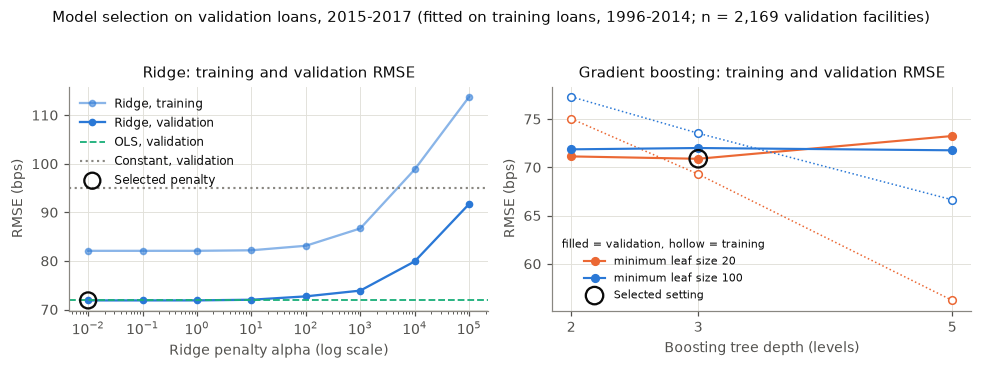

In [29]:
# Validation selection figure: Ridge penalty path and boosting settings.
cand_idx = CANDIDATES.set_index("key")
ridge_rows = CANDIDATES[CANDIDATES["family"] == "ridge"].sort_values("alpha")
gbm_rows = CANDIDATES[CANDIDATES["family"] == "gbm"]
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(9.0, 3.2))

ax_a.plot(ridge_rows["alpha"], ridge_rows["train_rmse"], marker="o", ms=4, color=FAMILY_COLORS["ridge"], alpha=0.55, label="Ridge, training")
ax_a.plot(ridge_rows["alpha"], ridge_rows["val_rmse"], marker="o", ms=4, color=FAMILY_COLORS["ridge"], label="Ridge, validation")
ax_a.axhline(cand_idx.loc["ols", "val_rmse"], color=FAMILY_COLORS["ols"], ls="--", lw=1.2, label="OLS, validation")
ax_a.axhline(cand_idx.loc["constant", "val_rmse"], color=FAMILY_COLORS["constant"], ls=":", lw=1.4, label="Constant, validation")
ax_a.scatter([sel_alpha], [cand_idx.loc[SELECTED["ridge"], "val_rmse"]], s=110, facecolors="none", edgecolors=INK, linewidths=1.5,
             zorder=5, label="Selected penalty")
ax_a.set_xscale("log")
ax_a.set_xlabel("Ridge penalty alpha (log scale)")
ax_a.set_ylabel("RMSE (bps)")
ax_a.set_title("Ridge: training and validation RMSE")
ax_a.legend(frameon=False, loc="best")

leaf_colors = {_l: _c for _l, _c in zip(sorted(gbm_rows["min_samples_leaf"].unique()), [FAMILY_COLORS["gbm"], "#2a78d6"])}
for _leaf, _grp in gbm_rows.groupby("min_samples_leaf"):
    _grp = _grp.sort_values("max_depth")
    ax_b.plot(_grp["max_depth"], _grp["train_rmse"], marker="o", ms=5, mfc="white", color=leaf_colors[_leaf], ls=":", lw=1.0)
    ax_b.plot(_grp["max_depth"], _grp["val_rmse"], marker="o", ms=5, color=leaf_colors[_leaf], lw=1.4,
              label=f"minimum leaf size {int(_leaf)}")
_sel_g = cand_idx.loc[SELECTED["gbm"]]
ax_b.scatter([_sel_g["max_depth"]], [_sel_g["val_rmse"]], s=130, facecolors="none", edgecolors=INK, linewidths=1.5, zorder=5,
             label="Selected setting")
ax_b.set_xticks(sorted(gbm_rows["max_depth"].unique()))
ax_b.set_xlabel("Boosting tree depth (levels)")
ax_b.set_ylabel("RMSE (bps)")
ax_b.set_title("Gradient boosting: training and validation RMSE")
ax_b.legend(frameon=False, loc="best", fontsize=7, title="filled = validation, hollow = training", title_fontsize=7)
fig.suptitle(f"Model selection on validation loans, 2015-2017 (fitted on training loans, 1996-2014; n = {len(valid):,} validation facilities)", y=1.03, fontsize=10)
fig.tight_layout()
save_fig(fig, "validation_selection")


### Pairwise comparisons with a borrower-clustered bootstrap

Rows are not independent evidence: facilities within a package, and packages within a borrower (every package belongs to one borrower, as checked in Section 2), share information. Each comparison therefore resamples borrowers (`gvkey`) with all of their facilities, 2,000 times with seed 42, and recomputes the RMSE difference A minus B, where A is the first-named (more complex) model. The table reports the 95% percentile interval of that difference. A pair is classed as about equal when the relative RMSE difference is below 2%; otherwise the class says whether A is lower or higher, and "clearly" only if the interval excludes zero.

This interval is a descriptive robustness check, not a significance test, and it does not remove dependence through common time effects.

In [30]:
# Validation comparisons: training fits of the selected specifications, borrowers resampled.
val_preds = {_fam: VAL_PRED[SELECTED[_fam]] for _fam in FAMILIES + ["ridge_log"]}
_ = run_pairs("validation", y_valid.to_numpy(), val_preds, valid["gvkey"].to_numpy(), MAIN_PAIRS)
_first = R["boot"]["validation"][MAIN_PAIRS[0]]
show(pair_view("validation", MAIN_PAIRS), digits=1, index=False,
     caption=f"Validation comparisons ({_first['n_obs']:,} facilities, {_first['n_clusters']:,} borrowers resampled {_first['n_boot']:,} times); "
             f"A is the first-named model")


Validation comparisons (2,169 facilities, 1,357 borrowers resampled 2,000 times); A is the first-named model


A vs B,RMSE of A (bps),RMSE of B (bps),A minus B (bps),Relative to B (%),"95% interval, low (bps)","95% interval, high (bps)",Classification
OLS vs Constant (fitting-sample mean),71.9,95.1,-23.2,-24.4,-26.7,-19.8,A clearly lower RMSE
Ridge vs Constant (fitting-sample mean),71.9,95.1,-23.2,-24.4,-26.7,-19.8,A clearly lower RMSE
Gradient boosting vs Constant (fitting-sample mean),70.9,95.1,-24.2,-25.5,-27.2,-21.3,A clearly lower RMSE
Ridge vs OLS,71.9,71.9,0.0,0.0,0.0,0.0,about equal (within 2%)
Gradient boosting vs OLS,70.9,71.9,-1.0,-1.4,-2.6,0.6,about equal (within 2%)
Gradient boosting vs Ridge,70.9,71.9,-1.0,-1.4,-2.6,0.6,about equal (within 2%)


**Validation results.** Selected specification of each family, fitted on training loans and scored on the 2,169 validation facilities (bps):

- Constant benchmark (training mean): RMSE 95.1, MAE 71.1
- OLS: RMSE 71.9, MAE 47.5
- Ridge (alpha = 0.01): RMSE 71.9, MAE 47.5
- Gradient boosting (depth 3, min leaf 20): RMSE 70.9, MAE 43.8

**Preferred specification** (chosen on the lowest validation RMSE before any test target is read): Gradient boosting (depth 3, min leaf 20), validation RMSE 70.9 bps and MAE 43.8 bps. Gradient boosting (depth 3, min leaf 20) is substantially more accurate than the constant benchmark on the validation sample (RMSE 70.9 vs 95.1 bps, 25.5% lower; the borrower-clustered bootstrap 95% interval for the difference, [-27.2, -21.3] bps, excludes zero).

Gradient boosting (depth 3, min leaf 20) and OLS are about equally accurate on the validation sample (RMSE 70.9 vs 71.9 bps, a difference of 1.4%). The lead over the runner-up is small and not robust. The choice follows the pre-set rule of the lowest validation RMSE; it does not establish a clear ranking among the three, and a different one could have been chosen with a slightly different validation sample. Across the 6 boosting settings the validation RMSE lies between 70.9 and 73.3 bps; the selected setting is the one with the lowest value, as the rule requires. By validation year, the preferred specification has an RMSE more than 2.0% below the lowest of the other two in 2017 and within 2.0% of the lowest of the other two in 2015 and 2016 (its RMSE is 65.8 bps in 2015, 78.3 bps in 2016 and 69.3 bps in 2017; constant benchmark: 90.8, 103.9 and 91.1 bps, respectively).

**Limits of the selection.** All choices rest on one chronological split with only 3 validation years (878, 671, 620 facilities), so the selection is noisy and the ranking of models could differ in other periods. Facilities within a package and loans to the same borrower are dependent, so the bootstrap intervals above resample borrowers; they are descriptive, not a formal test, and they ignore shocks common to all loans in a period. The constant is the benchmark and is never a candidate for the preferred specification.

**Role of regularization.** Ridge minimizes squared error plus a penalty (alpha) times the sum of the squared coefficients of all design columns except the intercept (numeric columns are standardized; indicator and category columns are 0/1). A larger penalty shrinks coefficients toward zero, which can reduce overfitting when predictors are many, correlated or noisy, at the price of some bias; a penalty near zero reproduces OLS.

Here the validation RMSE is lowest at the smallest penalty on the grid (alpha = 0.01, 71.9 bps) and rises as the penalty grows: 72.7 at alpha = 100, 73.9 at 1000 and 91.7 at 100000. The least-shrunk Ridge was therefore chosen, and it is almost unshrunk: the L2 norm of its coefficients is 227.0 against 227.2 for OLS. Ridge (alpha = 0.01) and OLS are about equally accurate on the validation sample (RMSE 71.9 vs 71.9 bps, a difference of 0.0%). Ridge and OLS are not distinguishable on validation data. Regularization did not reduce validation RMSE, the selection criterion, in this sample, and Ridge here is close to OLS. For context, the training design has 4,157 rows, 51 design columns and a condition number of 179.0; the data here cannot show why shrinkage does not help. Because the minimum sits at the edge of the grid, a still smaller penalty cannot be ruled out, but it would converge to OLS. On validation MAE, moderate shrinkage does lower it, from 47.5 bps for OLS to 45.0 bps at alpha = 1000, while raising RMSE (73.9 bps against 71.9 for OLS), i.e. it trades a few larger errors for many smaller ones.

The validation RMSE of the constant benchmark (95.1 bps) is below its training RMSE (117.7 bps), so even the benchmark makes smaller errors on the validation loans than on the training loans. A validation RMSE below the training RMSE can therefore reflect the period and must not be read as a gain for the models or as proof that they do not overfit.

**Why a nonlinear model might help or fail.** Boosting can capture thresholds, non-monotone patterns and interactions (for example between size and secured status) that linear terms miss, which could help. With a limited training sample and noisy, partly missing predictors, flexible trees can also fit idiosyncratic patterns that do not carry over to later loans. Gradient boosting (depth 3, min leaf 20) and Ridge (alpha = 0.01) are about equally accurate on the validation sample (RMSE 70.9 vs 71.9 bps, a difference of 1.4%). The data therefore show no robust gain from allowing nonlinearity and interactions. Across the boosting settings the training RMSE ranges from 56.2 to 77.3 bps, while the validation RMSE stays between 70.9 and 73.3 bps. The validation-minus-training gap is +1.6 bps for the selected setting and +17.0 bps (computed before rounding) for the setting with the widest gap (depth 5, min leaf 20). Consistent with overfitting: the deepest configuration (depth 5, minimum leaf 20) has a lower training RMSE (56.2 against 69.3 bps) but a higher validation RMSE (73.3 against 70.9 bps); this validation difference has no bootstrap classification.

### Supplementary: Log-Target Ridge on Validation Data

This supplement fits Ridge to the natural log of the spread with the same preprocessing and the same penalty grid. Predictions are converted back to bps by exponentiating and multiplying by a smearing factor, the average of exp(training log residual), which corrects for the fact that the exponential of a predicted log estimates a conditional median (exactly so only when the log errors are symmetric), not a conditional mean. The penalty is chosen by validation RMSE in bps. The version without the smearing factor is shown as a diagnostic only. This model is evaluated once more in Section 4 and is never eligible to be the preferred specification.

In [31]:
# Log-target Ridge on the validation rows: all penalties.
_sel_log = R["s3"]["log_ridge"]["selected"]
log_view = LOG_CANDIDATES.assign(selected=["yes" if k == SELECTED["ridge_log"] else "" for k in LOG_CANDIDATES["key"]]
                                 ).drop(columns="key")
log_view["alpha"] = log_view["alpha"].map(lambda v: f"{v:g}")
log_view.columns = ["Penalty alpha", "Validation RMSE (bps)", "Validation MAE (bps)",
                    "Validation RMSE without smearing (bps)", "Smearing factor", "Selected"]
show(log_view, digits=3, index=False,
     caption="Log-target Ridge (training fits, validation rows); RMSE and MAE are in bps after converting back")
_ = run_pairs("validation", y_valid.to_numpy(), val_preds, valid["gvkey"].to_numpy(), ["ridgelog_vs_ridge"])
show(pair_view("validation", ["ridgelog_vs_ridge"]), digits=1, index=False,
     caption="Validation comparison of the log-target Ridge (A) with the bps Ridge (B), borrower-clustered bootstrap")


Log-target Ridge (training fits, validation rows); RMSE and MAE are in bps after converting back


Penalty alpha,Validation RMSE (bps),Validation MAE (bps),Validation RMSE without smearing (bps),Smearing factor,Selected
0.01,70.347,45.022,71.091,1.102,
0.1,70.343,45.020,71.091,1.102,
1,70.310,45.008,71.093,1.102,
10,70.201,44.881,71.250,1.102,yes
100,71.172,44.365,73.277,1.104,
1000,74.135,44.221,78.425,1.114,
10000,79.636,50.862,83.692,1.150,
100000,91.210,66.441,90.044,1.201,


Validation comparison of the log-target Ridge (A) with the bps Ridge (B), borrower-clustered bootstrap


A vs B,RMSE of A (bps),RMSE of B (bps),A minus B (bps),Relative to B (%),"95% interval, low (bps)","95% interval, high (bps)",Classification
"Ridge, log target (supplementary) vs Ridge",70.2,71.9,-1.7,-2.3,-5.2,2.6,"A lower, not robust"


**Log-target Ridge (supplementary).** The selected penalty is alpha = 10, an interior penalty; the smearing factor is 1.10. Its validation RMSE after converting back to bps is 70.2 bps (MAE 44.9 bps). Without the smearing factor the validation RMSE is 71.3 bps, so the correction reduces it to 70.2 bps; the factor corrects for the exponential of a predicted log estimating a conditional median (exactly so only when the log errors are symmetric), not a conditional mean.

The log-target Ridge has a lower validation RMSE than the Ridge fitted to the spread in bps (70.2 vs 71.9 bps, 2.3% lower), but the borrower-clustered bootstrap 95% interval [-5.2, 2.6] bps includes zero, so the ranking is not robust to resampling borrowers. The validation data therefore give no robust indication that the log target helps. For reference, the preferred specification's validation RMSE is 70.9 bps.

This model is a separate supplement. It was not a candidate for the preferred specification, and the comparison in Section 3 uses the spread in bps; the log target never replaces it.

## 4. Evaluate Later Loans

The specifications chosen in Section 3 are frozen first: the frozen choices are displayed and fingerprinted before any test-period target is read. Each frozen specification is then refitted on the development rows (training plus validation, 1996-2017), with the preprocessing refitted on the same rows and the hyperparameters unchanged. The refits are scored once on the test rows (2018-2019). Nothing is tuned, selected or re-chosen with test data, and the preferred specification stays the one chosen on validation.

Accuracy is measured by RMSE and MAE in basis points (bps) and by the out-of-sample R<sup>2</sup> against the refitted constant benchmark:

R<sup>2</sup><sub>OOS</sub> = 1 − Σ<sub>i∈test</sub>(y<sub>i</sub> − ŷ<sub>i</sub>)<sup>2</sup> / Σ<sub>i∈test</sub>(y<sub>i</sub> − ȳ<sub>train+validation</sub>)<sup>2</sup>

Here ȳ<sub>train+validation</sub> is the mean spread of the development rows, the prediction of the refitted constant. A negative value means worse than the benchmark. This is not the usual R<sup>2</sup> against the test mean: the benchmark is a mean known before the test period, so a model can score below zero.

In [32]:
# Freeze every choice, show it, and only then open the test-period targets.
pref = R["s3"]["selected"][PREFERRED]
FROZEN = {
    "preferred_family": PREFERRED,
    "preferred_key": pref["key"],
    "selected_keys": {fam: SELECTED[fam] for fam in FAMILIES + ["ridge_log"]},
    "ridge_alpha": float(R["s3"]["selected"]["ridge"]["alpha"]),
    "gbm_max_depth": int(R["s3"]["selected"]["gbm"]["max_depth"]),
    "gbm_min_samples_leaf": int(R["s3"]["selected"]["gbm"]["min_samples_leaf"]),
    "ridgelog_alpha": float(R["s3"]["log_ridge"]["selected"]["alpha"]),
    "large_error_threshold_bps": float(THRESH["large_error_mult"] * pref["val_rmse"]),
}
FROZEN_DIGEST = hashlib.sha256(json.dumps(FROZEN, sort_keys=True).encode()).hexdigest()[:16]

frozen_table = pd.DataFrame([
    ("Preferred specification", spec_label(PREFERRED, pref)),
    ("Constant benchmark", DISPLAY["constant"]),
    ("OLS", spec_label("ols")),
    ("Ridge", spec_label("ridge", {"alpha": FROZEN["ridge_alpha"]})),
    ("Gradient boosting", spec_label("gbm", {"max_depth": FROZEN["gbm_max_depth"], "min_samples_leaf": FROZEN["gbm_min_samples_leaf"]})),
    ("Log-target Ridge (supplementary)", spec_label("ridge_log", {"alpha": FROZEN["ridgelog_alpha"]})),
    ("Large-error threshold (bps)", f"{FROZEN['large_error_threshold_bps']:.2f} ({plain_number(THRESH['large_error_mult'])} x preferred validation RMSE)"),
    ("Fingerprint of frozen choices", FROZEN_DIGEST),
], columns=["Frozen choice", "Value"])
print("Frozen choices (recorded before any test target is read)")
show(frozen_table, index=False)

R["checks"]["test_locked_until_freeze"] = bool(_LOCK["test_reads"] == 0)
assert R["checks"]["test_locked_until_freeze"]
unlock_test(FROZEN_DIGEST)
R["freeze"].update({**FROZEN, "digest": FROZEN_DIGEST})
print(f"Test-period targets are now readable, under fingerprint {FROZEN_DIGEST}. Nothing is tuned or selected from them.")


Frozen choices (recorded before any test target is read)


Frozen choice,Value
Preferred specification,"Gradient boosting (depth 3, min leaf 20)"
Constant benchmark,Constant (fitting-sample mean)
OLS,OLS
Ridge,Ridge (alpha = 0.01)
Gradient boosting,"Gradient boosting (depth 3, min leaf 20)"
Log-target Ridge (supplementary),"Ridge, log target (alpha = 10)"
Large-error threshold (bps),141.78 (2 x preferred validation RMSE)
Fingerprint of frozen choices,487e12fda272a59b


Test-period targets are now readable, under fingerprint 487e12fda272a59b. Nothing is tuned or selected from them.


In [33]:
# Refit each frozen specification on the development rows (training + validation).
Xdev = dev[FEATURES]
frozen_params = {"constant": {}, "ols": {}, "ridge": {"alpha": FROZEN["ridge_alpha"]},
                 "gbm": {"max_depth": FROZEN["gbm_max_depth"], "min_samples_leaf": FROZEN["gbm_min_samples_leaf"]},
                 "ridge_log": {"alpha": FROZEN["ridgelog_alpha"]}}
FITTED_DEV = {fam: fit_spec(fam, frozen_params[fam], Xdev, y_dev) for fam in FAMILIES + ["ridge_log"]}

prep_dev_linear = FITTED_DEV["ols"].named_steps["prep"]
desc_dev = describe_preprocessor(prep_dev_linear)
desc_dev["n_cols_tree"] = int(FITTED_DEV["gbm"].named_steps["prep"].transform(Xdev).shape[1])
R["s4"]["prep_dev"] = desc_dev
design_dev = np.column_stack([np.ones(len(dev)), prep_dev_linear.transform(Xdev)])
rank_dev = int(np.linalg.matrix_rank(design_dev))
R["s4"]["ols_rank_dev"] = rank_dev
R["checks"]["ols_full_rank_dev"] = bool(rank_dev == design_dev.shape[1])
assert R["checks"]["ols_full_rank_dev"]
assert np.allclose(FITTED_DEV["constant"].predict(Xdev), y_dev.mean(), rtol=0, atol=1e-9)
R["s4"]["ridge_log_smearing_dev"] = float(FITTED_DEV["ridge_log"].smearing_)

print(f"Refitted five frozen specifications on {len(dev):,} development rows with preprocessing refitted on the same rows; "
      f"hyperparameters unchanged.")
print(f"Development design matrix: {desc_dev['n_cols']} columns, rank with intercept {rank_dev} of {design_dev.shape[1]}; "
      f"constant benchmark equals the development mean of {y_dev.mean():.2f} bps; "
      f"log-target smearing factor {R['s4']['ridge_log_smearing_dev']:.3f}.")


Refitted five frozen specifications on 6,326 development rows with preprocessing refitted on the same rows; hyperparameters unchanged.
Development design matrix: 51 columns, rank with intercept 52 of 52; constant benchmark equals the development mean of 187.49 bps; log-target smearing factor 1.085.


In [34]:
# Score the frozen refits on the test rows, exactly once.
digest_now = hashlib.sha256(json.dumps(FROZEN, sort_keys=True).encode()).hexdigest()[:16]
R["checks"]["freeze_digest_unchanged"] = bool(digest_now == FROZEN_DIGEST == _LOCK["digest"])
assert R["checks"]["freeze_digest_unchanged"]

y_test = get_target("test")
test = test_X.assign(spread_bps=y_test)
YBAR_DEV = float(y_dev.mean())
MODELS = FAMILIES + ["ridge_log"]
TEST_PRED = {fam: np.asarray(FITTED_DEV[fam].predict(test[FEATURES]), dtype=float) for fam in MODELS}

TEST_METRICS = {}
for fam in MODELS:
    p = TEST_PRED[fam]
    TEST_METRICS[fam] = {"rmse": rmse(y_test, p), "mae": mae(y_test, p), "r2_oos": r2_oos(y_test, p, YBAR_DEV),
                         "mean_error": float(np.mean(y_test.to_numpy() - p)), "n": int(len(p))}

n_test = SOURCE_FACTS["n_test"]
finite_ok = all(np.isfinite(TEST_PRED[fam]).all() and len(TEST_PRED[fam]) == n_test for fam in MODELS)
index_ok = bool(test.index.equals(df.index[IS_TEST]) and test.index.equals(y_test.index) and test["facility_id"].is_unique)
R["checks"]["same_test_facilities"] = bool(index_ok and all(TEST_PRED[fam].shape == (n_test,) for fam in MODELS))
R["checks"]["test_rows_complete"] = bool(len(test) == n_test and finite_ok and np.isfinite(y_test.to_numpy()).all()
                                         and all(TEST_METRICS[fam]["n"] == n_test for fam in MODELS))
R["checks"]["r2_oos_constant_zero"] = bool(abs(TEST_METRICS["constant"]["r2_oos"]) < 1e-12)
assert R["checks"]["same_test_facilities"] and R["checks"]["test_rows_complete"] and R["checks"]["r2_oos_constant_zero"]

R["s4"].update({"n_test": int(len(test)), "n_dev": int(len(dev)), "ybar_dev": YBAR_DEV, "metrics": TEST_METRICS})

print("All values in basis points (100 bps = 1 percentage point); the target is the all-in drawn spread, "
      "which includes annual fees and is not the total interest rate.")
test_table = pd.DataFrame([{"model": spec_label(fam, frozen_params[fam]), "test RMSE (bps)": TEST_METRICS[fam]["rmse"],
                            "test MAE (bps)": TEST_METRICS[fam]["mae"], "R\u00b2 OOS": TEST_METRICS[fam]["r2_oos"],
                            "mean error (bps)": TEST_METRICS[fam]["mean_error"], "n": TEST_METRICS[fam]["n"]}
                           for fam in FAMILIES])
show(test_table, digits=3, index=False,
     caption=f"Test results for the four families (refit on {len(dev):,} development rows, scored on {len(test):,} test rows; "
             f"R\u00b2 OOS is measured against the development mean of {YBAR_DEV:.2f} bps; mean error is actual minus predicted)")


All values in basis points (100 bps = 1 percentage point); the target is the all-in drawn spread, which includes annual fees and is not the total interest rate.


Test results for the four families (refit on 6,326 development rows, scored on 1,279 test rows; R² OOS is measured against the development mean of 187.49 bps; mean error is actual minus predicted)


model,test RMSE (bps),test MAE (bps),R² OOS,mean error (bps),n
Constant (fitting-sample mean),74.748,62.194,0.000,-38.361,1279
OLS,54.378,40.556,0.471,19.505,1279
Ridge (alpha = 0.01),54.378,40.556,0.471,19.505,1279
"Gradient boosting (depth 3, min leaf 20)",60.402,46.546,0.347,34.216,1279


### Error by test year and ranking of the models

The test sample covers two loan years. The table reports each family's RMSE by year and the ranking of the families on the full test sample. Models whose test RMSEs differ by less than 2% share a rank and are marked as tied. The ranking is descriptive: the preferred specification is not changed after the test evaluation.

In [35]:
# Test RMSE by loan year for the four refitted families.
test_years = sorted(int(_y) for _y in test["year"].unique())
yr_masks = {_y: (test["year"] == _y).to_numpy() for _y in test_years}
R["s4"]["n_by_year"] = {str(_y): int(yr_masks[_y].sum()) for _y in test_years}
R["s4"]["rmse_by_year"] = {_fam: {str(_y): rmse(y_test.to_numpy()[yr_masks[_y]], TEST_PRED[_fam][yr_masks[_y]])
                                  for _y in test_years} for _fam in FAMILIES}
_first_year, _last_year = str(test_years[0]), str(test_years[-1])
_pref_year = R["s4"]["rmse_by_year"][PREFERRED]
R["s4"]["rmse_2019_vs_2018_rel"] = float((_pref_year[_last_year] - _pref_year[_first_year]) / _pref_year[_first_year])
_rel = R["s4"]["rmse_2019_vs_2018_rel"]

# Benchmark-relative statistics by year: R-squared against the development mean and RMSE ratio to the constant.
_y_np = y_test.to_numpy()
R["s4"]["r2_oos_by_year"] = {_fam: {str(_y): float(1 - np.sum((_y_np[yr_masks[_y]] - TEST_PRED[_fam][yr_masks[_y]]) ** 2)
                                    / np.sum((_y_np[yr_masks[_y]] - YBAR_DEV) ** 2)) for _y in test_years} for _fam in FAMILIES}
R["s4"]["rmse_ratio_by_year"] = {_fam: {str(_y): float(R["s4"]["rmse_by_year"][_fam][str(_y)] / R["s4"]["rmse_by_year"]["constant"][str(_y)])
                                        for _y in test_years} for _fam in FAMILIES}
R["s4"]["test_sd_by_year"] = {str(_y): float(np.std(_y_np[yr_masks[_y]], ddof=1)) for _y in test_years}
_ratio_pref = R["s4"]["rmse_ratio_by_year"][PREFERRED]
R["s4"]["ratio_2019_vs_2018_rel"] = float(_ratio_pref[_last_year] / _ratio_pref[_first_year] - 1)
R["s4"]["r2_oos_2019_minus_2018"] = float(R["s4"]["r2_oos_by_year"][PREFERRED][_last_year] - R["s4"]["r2_oos_by_year"][PREFERRED][_first_year])
_ratio_rel = R["s4"]["ratio_2019_vs_2018_rel"]
R["verdicts"]["by_year_test"] = ("later_weaker" if _ratio_rel > THRESH["subgroup_rel"]
                                 else "later_stronger" if _ratio_rel < -THRESH["subgroup_rel"] else "similar")

by_year_test_view = pd.DataFrame({DISPLAY[_fam]: [R["s4"]["rmse_by_year"][_fam][str(_y)] for _y in test_years] for _fam in FAMILIES},
                                 index=pd.Index(test_years, name="Loan year"))
by_year_test_view.insert(0, "Facilities", [R["s4"]["n_by_year"][str(_y)] for _y in test_years])
by_year_test_view.insert(1, "SD of test spreads (bps)", [R["s4"]["test_sd_by_year"][str(_y)] for _y in test_years])
for _fam in ("ols", "ridge", "gbm"):
    by_year_test_view[f"R² OOS, {DISPLAY[_fam]}"] = [R["s4"]["r2_oos_by_year"][_fam][str(_y)] for _y in test_years]
by_year_test_view[f"RMSE ratio to the constant, {DISPLAY[PREFERRED]}"] = [R["s4"]["rmse_ratio_by_year"][PREFERRED][str(_y)] for _y in test_years]
show(by_year_test_view, digits=3, caption="Test RMSE (bps), spread dispersion, R² OOS and RMSE ratio by loan year, refitted frozen specifications "
                                         "(R² OOS in each year is against the development-sample mean)")
print(f"Preferred specification, RMSE in {_last_year} relative to {_first_year}: {100 * _rel:+.1f}%; "
      f"RMSE ratio to the constant, {_last_year} relative to {_first_year}: {100 * _ratio_rel:+.1f}%; "
      f"R² OOS {_last_year} minus {_first_year}: {R['s4']['r2_oos_2019_minus_2018']:+.3f}.")


Test RMSE (bps), spread dispersion, R² OOS and RMSE ratio by loan year, refitted frozen specifications (R² OOS in each year is against the development-sample mean)


,Facilities,SD of test spreads (bps),Constant (fitting-sample mean),OLS,Ridge,Gradient boosting,"R² OOS, OLS","R² OOS, Ridge","R² OOS, Gradient boosting","RMSE ratio to the constant, Gradient boosting"
Loan year,,,,,,,,,,
2018,653,58.869,69.610,50.431,50.430,57.394,0.475,0.475,0.320,0.824
2019,626,69.314,79.755,58.211,58.211,63.389,0.467,0.467,0.368,0.795


Preferred specification, RMSE in 2019 relative to 2018: +10.4%; RMSE ratio to the constant, 2019 relative to 2018: -3.6%; R² OOS 2019 minus 2018: +0.048.


In [36]:
# Ranking of OLS, Ridge and boosting on the test rows, and the sign of the out-of-sample R-squared.
test_rank = sorted(["ols", "ridge", "gbm"], key=lambda f: (TEST_METRICS[f]["rmse"], ["ols", "ridge", "gbm"].index(f)))
R["s4"]["test_rank"] = list(test_rank)
R["verdicts"]["test_rank_matches_validation"] = bool(test_rank[0] == PREFERRED)
R["verdicts"]["r2_sign"] = {_fam: ("zero" if abs(TEST_METRICS[_fam]["r2_oos"]) < 1e-12
                                   else "positive" if TEST_METRICS[_fam]["r2_oos"] > 0 else "negative") for _fam in FAMILIES}

# Adjacent models whose RMSEs differ by less than the similarity threshold (same rule as the pair classification, the
# simpler model as the reference) share a rank.
_simple_order = ["ols", "ridge", "gbm"]
_rank_pos, _tied = {}, set()
for _i, _fam in enumerate(test_rank):
    if _i > 0:
        _prev = test_rank[_i - 1]
        _ref, _oth = sorted([_prev, _fam], key=_simple_order.index)
        if abs(TEST_METRICS[_oth]["rmse"] - TEST_METRICS[_ref]["rmse"]) / TEST_METRICS[_ref]["rmse"] < THRESH["similar_rel"]:
            _rank_pos[_fam] = _rank_pos[_prev]
            _tied.update([_prev, _fam])
            continue
    _rank_pos[_fam] = _i + 1
_rank_label = {_fam: f"{_rank_pos[_fam]} (tied)" if _fam in _tied else str(_rank_pos[_fam]) for _fam in test_rank}

rank_view = pd.DataFrame([{"Rank among OLS, Ridge, boosting": _rank_label.get(_fam, ""),
                           "Model": spec_label(_fam, frozen_params[_fam]),
                           "Test RMSE (bps)": TEST_METRICS[_fam]["rmse"], "Test MAE (bps)": TEST_METRICS[_fam]["mae"],
                           "R² OOS": TEST_METRICS[_fam]["r2_oos"]} for _fam in FAMILIES]
                         ).sort_values("Test RMSE (bps)")
show(rank_view, digits=3, index=False, caption="Test accuracy, sorted by RMSE (the constant is the benchmark and is not ranked)")
_pref_rank = _rank_label[PREFERRED]
print(f"The validation-selected preferred specification, {spec_label(PREFERRED, frozen_params[PREFERRED])}, ranks {_pref_rank} of 3 "
      f"among OLS, Ridge and boosting on test RMSE; it remains the preferred specification.")


Test accuracy, sorted by RMSE (the constant is the benchmark and is not ranked)


"Rank among OLS, Ridge, boosting",Model,Test RMSE (bps),Test MAE (bps),R² OOS
1 (tied),Ridge (alpha = 0.01),54.378,40.556,0.471
1 (tied),OLS,54.378,40.556,0.471
3,"Gradient boosting (depth 3, min leaf 20)",60.402,46.546,0.347
,Constant (fitting-sample mean),74.748,62.194,0.000


The validation-selected preferred specification, Gradient boosting (depth 3, min leaf 20), ranks 3 of 3 among OLS, Ridge and boosting on test RMSE; it remains the preferred specification.


### Level and dispersion of the test errors

The test mean squared error of each model splits exactly into the squared mean error (the level part: how far the predictions sit from the actual spreads on average) and the variance of the errors (the dispersion part). The table also shows R² against the test-period mean spread. That figure is a diagnostic only: the test-period mean was not known when the models were fitted, so it is not a performance measure, and it is not an alternative way of splitting R<sup>2</sup><sub>OOS</sub>. R<sup>2</sup><sub>OOS</sub> itself splits exactly into two parts, each relative to the benchmark's test mean squared error: the level part (the benchmark's squared mean error minus the model's) and the within part (the benchmark's error variance minus the model's). The two parts add up to R<sup>2</sup><sub>OOS</sub>.

In [37]:
# Split of the test mean squared error into squared mean error (level) and error variance (dispersion).
_models = ["constant", "ols", "ridge", "gbm", "ridge_log"]
_ybar_test = float(np.mean(y_test.to_numpy()))
_sst_test = float(np.mean((y_test.to_numpy() - _ybar_test) ** 2))
R["s4"]["mse_decomposition"] = {}
R["s4"]["r2_vs_test_mean"] = {}
_consistent = True
for _m in _models:
    _mse = float(TEST_METRICS[_m]["rmse"] ** 2)
    _bias_sq = float(TEST_METRICS[_m]["mean_error"] ** 2)
    _evar = _mse - _bias_sq
    _consistent = _consistent and abs(_evar - float(np.var(y_test.to_numpy() - TEST_PRED[_m]))) < 1e-6
    R["s4"]["mse_decomposition"][_m] = {"mse": _mse, "bias_sq": _bias_sq, "error_var": _evar, "bias_share": float(_bias_sq / _mse)}
    R["s4"]["r2_vs_test_mean"][_m] = float(1 - _mse / _sst_test)
R["checks"]["mse_decomposition_consistent"] = bool(_consistent)

# Share of test facilities whose actual spread is above the prediction, and the preferred model's level error.
R["s4"]["share_under"] = {_m: float(np.mean(y_test.to_numpy() > TEST_PRED[_m])) for _m in _models}
_pref_me, _pref_su = float(TEST_METRICS[PREFERRED]["mean_error"]), R["s4"]["share_under"][PREFERRED]
R["verdicts"]["pref_level_bias"] = ("systematic_under" if _pref_me > 0 and _pref_su >= THRESH["under_share_hi"]
                                    else "systematic_over" if _pref_me < 0 and _pref_su <= THRESH["under_share_lo"] else "none")

# Exact split of each R2_OOS into a level part (smaller squared mean error than the benchmark) and a within part
# (smaller error variance around the mean), both relative to the benchmark's test MSE.
_dc = R["s4"]["mse_decomposition"]["constant"]
R["s4"]["r2_oos_parts"] = {}
_parts_ok = True
for _m in _models:
    _d = R["s4"]["mse_decomposition"][_m]
    _lv = float((_dc["bias_sq"] - _d["bias_sq"]) / _dc["mse"])
    _wi = float((_dc["error_var"] - _d["error_var"]) / _dc["mse"])
    R["s4"]["r2_oos_parts"][_m] = {"level": _lv, "within": _wi}
    _parts_ok = _parts_ok and abs(_lv + _wi - float(TEST_METRICS[_m]["r2_oos"])) < 1e-9
R["checks"]["r2_oos_parts_sum"] = bool(_parts_ok)

_other = next(_f for _f in test_rank if _f != PREFERRED)
_dp, _do = R["s4"]["mse_decomposition"][PREFERRED], R["s4"]["mse_decomposition"][_other]
_mse_diff = _dp["mse"] - _do["mse"]
_bias_diff = _dp["bias_sq"] - _do["bias_sq"]
_var_diff = _dp["error_var"] - _do["error_var"]
_share_gap = float(_bias_diff / _mse_diff) if _mse_diff != 0 else 0.0
R["s4"]["test_gap"] = {"pref": PREFERRED, "other": _other, "mse_diff": float(_mse_diff), "bias_sq_diff": float(_bias_diff),
                       "error_var_diff": float(_var_diff), "bias_share_of_gap": _share_gap,
                       "error_var_rel": float(_var_diff / _do["error_var"])}
R["verdicts"]["test_gap_source"] = ("pref_best" if _mse_diff <= 0 else "mostly_level" if _share_gap >= 0.75
                                    else "mostly_dispersion" if _share_gap <= 0.25 else "mixed")

decomp_view = pd.DataFrame([{"Model": DISPLAY[_m], "Test MSE (bps squared)": R["s4"]["mse_decomposition"][_m]["mse"],
                             "Squared mean error (bps squared)": R["s4"]["mse_decomposition"][_m]["bias_sq"],
                             "Error variance (bps squared)": R["s4"]["mse_decomposition"][_m]["error_var"],
                             "Level share of MSE (%)": 100 * R["s4"]["mse_decomposition"][_m]["bias_share"],
                             "Test facilities under-predicted (%)": 100 * R["s4"]["share_under"][_m],
                             "R² OOS": TEST_METRICS[_m]["r2_oos"],
                             "of which from smaller level error": R["s4"]["r2_oos_parts"][_m]["level"],
                             "of which from smaller error variance": R["s4"]["r2_oos_parts"][_m]["within"],
                             "R² against the test-period mean (diagnostic)": R["s4"]["r2_vs_test_mean"][_m]} for _m in _models])
show(decomp_view, digits=3, index=False,
     caption="Test MSE split into squared mean error and error variance; the last column uses the test-period mean, which was not known in advance, "
             "and is a diagnostic rather than a performance measure; the two 'of which' columns add up to R² OOS (before rounding)")
print(f"Gap between {spec_label(PREFERRED, frozen_params[PREFERRED])} and {spec_label(_other, frozen_params[_other])} "
      f"(preferred minus other): MSE {_mse_diff:+,.1f}, of which squared mean error {_bias_diff:+,.1f} and error variance {_var_diff:+,.1f} "
      f"(bps squared).")


Test MSE split into squared mean error and error variance; the last column uses the test-period mean, which was not known in advance, and is a diagnostic rather than a performance measure; the two 'of which' columns add up to R² OOS (before rounding)


Model,Test MSE (bps squared),Squared mean error (bps squared),Error variance (bps squared),Level share of MSE (%),Test facilities under-predicted (%),R² OOS,of which from smaller level error,of which from smaller error variance,R² against the test-period mean (diagnostic)
Constant (fitting-sample mean),"5,587.252","1,471.552","4,115.700",26.338,17.514,0.000,0.000,0.000,-0.358
OLS,"2,956.978",380.453,"2,576.524",12.866,66.458,0.471,0.195,0.275,0.282
Ridge,"2,956.943",380.430,"2,576.513",12.866,66.458,0.471,0.195,0.275,0.282
Gradient boosting,"3,648.440","1,170.736","2,477.704",32.089,79.906,0.347,0.054,0.293,0.114
"Ridge, log target (supplementary)","2,605.203",212.853,"2,392.350",8.170,64.660,0.534,0.225,0.308,0.367


Gap between Gradient boosting (depth 3, min leaf 20) and Ridge (alpha = 0.01) (preferred minus other): MSE +691.5, of which squared mean error +790.3 and error variance -98.8 (bps squared).


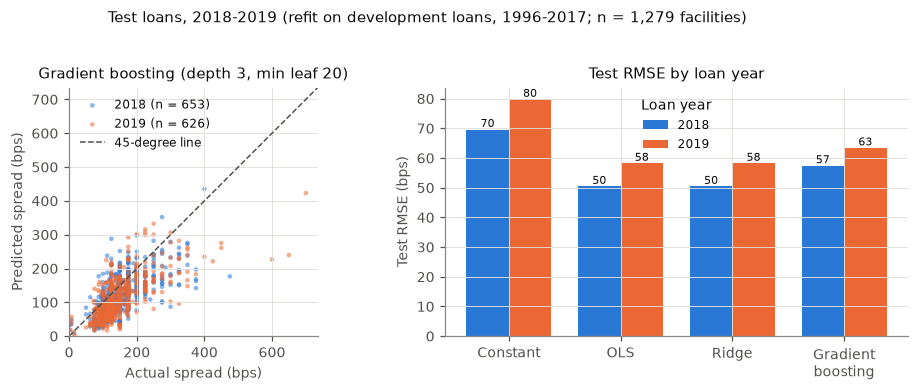

In [38]:
# Actual versus predicted spreads for the preferred refit, and test RMSE by year.
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(9.0, 3.4), gridspec_kw={"width_ratios": [1.0, 1.1]})
_pred = TEST_PRED[PREFERRED]
for _y in test_years:
    ax_a.scatter(y_test.to_numpy()[yr_masks[_y]], _pred[yr_masks[_y]], s=9, alpha=0.55, color=YEAR_COLORS[_y],
                 edgecolors="none", label=f"{_y} (n = {int(yr_masks[_y].sum()):,})")
_lim = (0.0, float(max(y_test.max(), _pred.max())) * 1.05)
ax_a.plot(_lim, _lim, color=INK2, lw=1.0, ls="--", label="45-degree line")
ax_a.set_xlim(_lim)
ax_a.set_ylim(_lim)
ax_a.set_aspect("equal", adjustable="box")
ax_a.set_xlabel("Actual spread (bps)")
ax_a.set_ylabel("Predicted spread (bps)")
ax_a.set_title(spec_label(PREFERRED, frozen_params[PREFERRED]))
ax_a.legend(frameon=False, loc="upper left")

_xpos = np.arange(len(FAMILIES))
_w = 0.38
for _i, _y in enumerate(test_years):
    _vals = [R["s4"]["rmse_by_year"][_fam][str(_y)] for _fam in FAMILIES]
    _bars = ax_b.bar(_xpos + (_i - (len(test_years) - 1) / 2) * _w, _vals, _w, color=YEAR_COLORS[_y], label=f"{_y}")
    for _b, _v in zip(_bars, _vals):
        ax_b.text(_b.get_x() + _b.get_width() / 2, _v, f"{_v:.0f}", ha="center", va="bottom", fontsize=7)
ax_b.set_xticks(_xpos)
ax_b.set_xticklabels(["Constant", "OLS", "Ridge", "Gradient\nboosting"])
ax_b.set_ylabel("Test RMSE (bps)")
ax_b.set_title("Test RMSE by loan year")
ax_b.legend(frameon=False, title="Loan year")
fig.suptitle(f"Test loans, 2018-2019 (refit on development loans, 1996-2017; n = {len(test):,} facilities)", y=1.03, fontsize=10)
fig.tight_layout()
save_fig(fig, "test_actual_vs_predicted")


### Borrowers seen before and new borrowers

A test facility counts as a seen-borrower facility if its borrower (`gvkey`) appears in the development rows (training or validation), and as a new-borrower facility otherwise.

In [39]:
# Test RMSE for facilities of borrowers seen in the development rows versus new borrowers.
seen_mask = test["gvkey"].isin(set(dev["gvkey"])).to_numpy()
R["s4"]["seen_new"] = {}
for _fam in FAMILIES:
    _r_seen = rmse(y_test.to_numpy()[seen_mask], TEST_PRED[_fam][seen_mask])
    _r_new = rmse(y_test.to_numpy()[~seen_mask], TEST_PRED[_fam][~seen_mask])
    R["s4"]["seen_new"][_fam] = {"rmse_seen": _r_seen, "rmse_new": _r_new, "n_seen": int(seen_mask.sum()),
                                 "n_new": int((~seen_mask).sum()), "rel": float((_r_new - _r_seen) / _r_seen)}
_rel = R["s4"]["seen_new"][PREFERRED]["rel"]
R["verdicts"]["seen_vs_new"] = ("new_higher" if _rel > THRESH["subgroup_rel"]
                                else "new_lower" if _rel < -THRESH["subgroup_rel"] else "similar")
seen_view = pd.DataFrame([{"Model": DISPLAY[_fam], "RMSE, seen borrowers (bps)": R["s4"]["seen_new"][_fam]["rmse_seen"],
                           "RMSE, new borrowers (bps)": R["s4"]["seen_new"][_fam]["rmse_new"],
                           "New relative to seen (%)": 100 * R["s4"]["seen_new"][_fam]["rel"]} for _fam in FAMILIES])
show(seen_view, digits=1, index=False,
     caption=f"Test RMSE by borrower status ({int(seen_mask.sum()):,} seen-borrower facilities, {int((~seen_mask).sum()):,} new-borrower facilities)")

# Borrower-clustered bootstrap of the preferred model's RMSE difference (new minus seen); the two groups are resampled separately.
_sq_err = (y_test.to_numpy() - TEST_PRED[PREFERRED]) ** 2
_gv = test["gvkey"].to_numpy()


def _borrower_sums(m):
    codes, _ = pd.factorize(pd.Series(_gv[m]), sort=True)
    return (np.bincount(codes, weights=_sq_err[m]), np.bincount(codes).astype(float))


_sse_new, _cnt_new = _borrower_sums(~seen_mask)
_sse_seen, _cnt_seen = _borrower_sums(seen_mask)
_B = int(THRESH["boot_n"])
_rng = np.random.default_rng(SEED)
_idx_new = _rng.integers(0, len(_sse_new), size=(_B, len(_sse_new)))
_idx_seen = _rng.integers(0, len(_sse_seen), size=(_B, len(_sse_seen)))
_w_new = np.stack([np.bincount(_row, minlength=len(_sse_new)) for _row in _idx_new])
_w_seen = np.stack([np.bincount(_row, minlength=len(_sse_seen)) for _row in _idx_seen])
_diffs = (np.sqrt((_w_new @ _sse_new) / (_w_new @ _cnt_new)) - np.sqrt((_w_seen @ _sse_seen) / (_w_seen @ _cnt_seen)))
_d_obs = R["s4"]["seen_new"][PREFERRED]["rmse_new"] - R["s4"]["seen_new"][PREFERRED]["rmse_seen"]
_lo_b, _hi_b = (float(_q) for _q in np.quantile(_diffs, [(1 - THRESH["boot_level"]) / 2, 1 - (1 - THRESH["boot_level"]) / 2]))
R["s4"]["seen_new_boot"] = {"d": float(_d_obs), "lo": _lo_b, "hi": _hi_b, "n_clusters_new": int(len(_sse_new)),
                            "n_clusters_seen": int(len(_sse_seen)), "n_boot": _B}
_sv = R["verdicts"]["seen_vs_new"]
R["verdicts"]["seen_vs_new_robust"] = ("not_applicable" if _sv == "similar"
                                       else "clear" if (_sv == "new_higher" and _lo_b > 0) or (_sv == "new_lower" and _hi_b < 0)
                                       else "not_robust")
_robust_words = {"clear": "the difference is robust to resampling borrowers",
                 "not_robust": "the difference is not robust to resampling borrowers (the interval includes zero)",
                 "not_applicable": "the difference is small, so no robustness classification applies"}
print(f"New minus seen RMSE of {spec_label(PREFERRED, frozen_params[PREFERRED])}: {_d_obs:+.1f} bps; "
      f"95% interval from resampling borrowers [{_lo_b:+.1f}, {_hi_b:+.1f}] bps "
      f"({len(_sse_new):,} new and {len(_sse_seen):,} seen borrowers, {_B:,} resamples); {_robust_words[R['verdicts']['seen_vs_new_robust']]}.")


Test RMSE by borrower status (1,163 seen-borrower facilities, 116 new-borrower facilities)


Model,"RMSE, seen borrowers (bps)","RMSE, new borrowers (bps)",New relative to seen (%)
Constant (fitting-sample mean),74.5,77.3,3.8
OLS,53.7,60.6,12.9
Ridge,53.7,60.6,12.9
Gradient boosting,59.6,67.7,13.6


New minus seen RMSE of Gradient boosting (depth 3, min leaf 20): +8.1 bps; 95% interval from resampling borrowers [-4.8, +21.7] bps (93 new and 792 seen borrowers, 2,000 resamples); the difference is not robust to resampling borrowers (the interval includes zero).


### Large errors

A large error is an absolute test error of the preferred specification above 2 times its validation RMSE. The threshold was frozen before any test target was read. Errors are actual minus predicted, so a positive error is an underprediction.

In [40]:
# Large errors of the preferred specification on the test rows.
_thr = float(FROZEN["large_error_threshold_bps"])
_err = y_test.to_numpy() - TEST_PRED[PREFERRED]
_large = np.abs(_err) > _thr
_p90_dev = float(np.quantile(y_dev.to_numpy(), 0.90))
_mask_new = ~seen_mask


def _mean(v):
    v = np.asarray(v, dtype=float)
    return float(v.mean()) if len(v) else 0.0


def _median(v):
    v = np.asarray(v, dtype=float)
    return float(np.median(v)) if len(v) else 0.0


def _profile(m):
    t = test.loc[m]
    return {"n": int(m.sum()), "mean_actual": _mean(y_test.to_numpy()[m]), "mean_pred": _mean(TEST_PRED[PREFERRED][m]),
            "mean_error": _mean(_err[m]), "share_under": _mean(_err[m] > 0),
            "share_market_missing": _mean(t["return_12m"].isna()),
            "share_accounting_missing": _mean(t["log_assets"].isna()),
            "share_secured_unknown": _mean(t["secured"].eq("Unknown")),
            "share_not_main_revolver": _mean(t["loan_type"].ne("Revolver/Line >= 1 Yr.")),
            "share_not_corp_purposes": _mean(t["loan_purpose"].ne("Corp. purposes")),
            "share_new_borrower": _mean(_mask_new[m]),
            "share_actual_above_dev_p90": _mean(y_test.to_numpy()[m] > _p90_dev),
            "median_log_assets": _median(t["log_assets"].dropna())}


_top = (test.assign(actual=y_test.to_numpy(), predicted=TEST_PRED[PREFERRED], error=_err, abs_error=np.abs(_err),
                    market_missing=test["return_12m"].isna().to_numpy(), accounting_missing=test["log_assets"].isna().to_numpy())
        .sort_values(["abs_error", "facility_id"], ascending=[False, True]).head(10))
_top_records = [{"facility_id": int(r_["facility_id"]), "loan_date": r_["loan_date"].strftime("%Y-%m-%d"), "year": int(r_["year"]),
                 "actual": float(r_["actual"]), "predicted": float(r_["predicted"]), "error": float(r_["error"]),
                 "secured": str(r_["secured"]), "loan_type": str(r_["loan_type"]), "loan_purpose": str(r_["loan_purpose"]),
                 "industry": str(r_["industry"]), "market_missing": bool(r_["market_missing"]),
                 "accounting_missing": bool(r_["accounting_missing"])} for _, r_ in _top.iterrows()]
_share_under = _mean(_err[_large] > 0)
R["s4"]["large_errors"] = {"threshold_bps": _thr, "n": int(_large.sum()), "share": _mean(_large),
                           "n_under": int((_err[_large] > 0).sum()), "n_over": int((_err[_large] <= 0).sum()), "share_under": _share_under,
                           "profile": {"large": _profile(_large), "rest": _profile(~_large)}, "top10": _top_records}
R["verdicts"]["large_errors_sign"] = ("mostly_under" if _share_under >= THRESH["under_share_hi"]
                                      else "mostly_over" if _share_under <= THRESH["under_share_lo"] else "mixed")
_share_under_rest = R["s4"]["large_errors"]["profile"]["rest"]["share_under"]
R["verdicts"]["under_base"] = ("mostly_under" if _share_under_rest >= THRESH["under_share_hi"]
                               else "mostly_over" if _share_under_rest <= THRESH["under_share_lo"] else "mixed")
_le = R["s4"]["large_errors"]
print(f"Large errors of {spec_label(PREFERRED, frozen_params[PREFERRED])}: threshold {_thr:.1f} bps; "
      f"{_le['n']:,} of {len(test):,} test facilities ({100 * _le['share']:.1f}%); "
      f"{_le['n_under']:,} of them are underpredictions ({100 * _le['share_under']:.1f}%).")

_labels = {"mean_actual": "Mean actual spread (bps)", "mean_pred": "Mean predicted spread (bps)", "mean_error": "Mean error, actual minus predicted (bps)",
           "share_under": "Underpredicted (%)", "share_market_missing": "Market history missing (%)",
           "share_accounting_missing": "Total assets missing (%)", "share_secured_unknown": "Secured status unknown (%)",
           "share_not_main_revolver": "Not a revolver of one year or longer (%)", "share_not_corp_purposes": "Purpose not general corporate (%)",
           "share_new_borrower": "New borrower (%)", "share_actual_above_dev_p90": "Actual spread above development 90th percentile (%)",
           "median_log_assets": "Median " + feature_label("log_assets")[0].lower() + feature_label("log_assets")[1:]}
profile_view = pd.DataFrame({"Large errors": {v: (100 * _le["profile"]["large"][k] if k.startswith("share") else _le["profile"]["large"][k]) for k, v in _labels.items()},
                             "All other test facilities": {v: (100 * _le["profile"]["rest"][k] if k.startswith("share") else _le["profile"]["rest"][k]) for k, v in _labels.items()}})
print(f"Facilities: {_le['profile']['large']['n']:,} with large errors, {_le['profile']['rest']['n']:,} others.")
show(profile_view, digits=1, caption="Profile of large-error facilities versus all other test facilities")
top_view = pd.DataFrame(_top_records).rename(columns={
    "facility_id": "Facility", "loan_date": "Loan date", "year": "Year", "actual": "Actual (bps)", "predicted": "Predicted (bps)",
    "error": "Error (bps)", "secured": "Secured", "loan_type": "Loan type", "loan_purpose": "Loan purpose", "industry": "Industry",
    "market_missing": "Market history missing", "accounting_missing": "Total assets missing (log_assets)"})
for _c in ("Market history missing", "Total assets missing (log_assets)"):
    top_view[_c] = top_view[_c].map({True: "yes", False: "no"})
# Materiality: observed count among the large errors against the count expected at the rate among all other facilities.
_flags = {"secured_unknown": test["secured"].eq("Unknown").to_numpy(), "market_missing": test["return_12m"].isna().to_numpy(),
          "accounting_missing": test["log_assets"].isna().to_numpy(),
          "not_main_revolver": test["loan_type"].ne("Revolver/Line >= 1 Yr.").to_numpy(),
          "not_corp_purposes": test["loan_purpose"].ne("Corp. purposes").to_numpy(), "new_borrower": _mask_new,
          "actual_above_dev_p90": y_test.to_numpy() > _p90_dev}
_flag_names = {"secured_unknown": "Secured status unknown", "market_missing": "Market history missing",
               "accounting_missing": "Total assets missing (log_assets)", "not_main_revolver": "Not a revolver of one year or longer",
               "not_corp_purposes": "Purpose not general corporate", "new_borrower": "New borrower",
               "actual_above_dev_p90": "Actual spread above development 90th percentile"}
_class_labels = {"more_often": "more often", "less_often": "less often", "similar_given_n": "similar given n"}
_n_large = int(_large.sum())
R["s4"]["large_errors"]["materiality"] = {}
R["verdicts"]["large_error_profile"] = {}
for _k, _f in _flags.items():
    _obs = int(_f[_large].sum())
    _exp = float(_n_large * _f[~_large].mean())
    _exc = float(_obs - _exp)
    R["s4"]["large_errors"]["materiality"][_k] = {"observed": _obs, "expected": _exp, "excess": _exc}
    R["verdicts"]["large_error_profile"][_k] = (
        "more_often" if _exc >= THRESH["material_count"] and _obs >= (1 + THRESH["material_rel"]) * _exp
        else "less_often" if _exc <= -THRESH["material_count"] and _obs <= (1 - THRESH["material_rel"]) * _exp else "similar_given_n")
material_view = pd.DataFrame([{"Characteristic": _flag_names[_k],
                               f"Observed among {_n_large} large errors": R["s4"]["large_errors"]["materiality"][_k]["observed"],
                               "Expected at the rate among other facilities": R["s4"]["large_errors"]["materiality"][_k]["expected"],
                               "Excess": R["s4"]["large_errors"]["materiality"][_k]["excess"],
                               "Classification": _class_labels[R["verdicts"]["large_error_profile"][_k]]} for _k in _flags])
show(material_view, digits=1, index=False,
     caption="Large errors compared with the rest, in facility counts (a difference counts only if the excess is at least "
             f"{THRESH['material_count']} facilities and at least {int(100 * THRESH['material_rel'])}% above or below the expected count)")
show(top_view, digits=1, index=False, caption="The 10 largest absolute test errors of the preferred specification")


Large errors of Gradient boosting (depth 3, min leaf 20): threshold 141.8 bps; 28 of 1,279 test facilities (2.2%); 27 of them are underpredictions (96.4%).
Facilities: 28 with large errors, 1,251 others.


Profile of large-error facilities versus all other test facilities


,Large errors,All other test facilities
Mean actual spread (bps),373.2,144.1
Mean predicted spread (bps),179.1,113.5
"Mean error, actual minus predicted (bps)",194.1,30.6
Underpredicted (%),96.4,79.5
Market history missing (%),28.6,26.4
Total assets missing (%),0.0,1.6
Secured status unknown (%),50.0,43.2
Not a revolver of one year or longer (%),14.3,11.2
Purpose not general corporate (%),28.6,15.8
New borrower (%),17.9,8.9


Large errors compared with the rest, in facility counts (a difference counts only if the excess is at least 3 facilities and at least 50% above or below the expected count)


Characteristic,Observed among 28 large errors,Expected at the rate among other facilities,Excess,Classification
Secured status unknown,14,12.1,1.9,similar given n
Market history missing,8,7.4,0.6,similar given n
Total assets missing (log_assets),0,0.4,-0.4,similar given n
Not a revolver of one year or longer,4,3.1,0.9,similar given n
Purpose not general corporate,8,4.4,3.6,more often
New borrower,5,2.5,2.5,similar given n
Actual spread above development 90th percentile,16,0.2,15.8,more often


The 10 largest absolute test errors of the preferred specification


Facility,Loan date,Year,Actual (bps),Predicted (bps),Error (bps),Secured,Loan type,Loan purpose,Industry,Market history missing,Total assets missing (log_assets)
428765,2019-08-30,2019,650.0,239.9,410.1,Yes,Revolver/Line >= 1 Yr.,Corp. purposes,Retail,yes,no
425080,2019-06-26,2019,600.0,227.0,373.0,Yes,Revolver/Line >= 1 Yr.,Corp. purposes,Finance and real estate,yes,no
407516,2018-08-03,2018,475.0,176.8,298.2,Yes,Revolver/Line >= 1 Yr.,LBO,Manufacturing,no,no
432598,2019-11-14,2019,700.0,423.0,277.0,Yes,Revolver/Line < 1 Yr.,Debtor-in-poss.,Manufacturing,no,no
413900,2018-12-06,2018,375.0,142.1,232.9,Yes,Revolver/Line >= 1 Yr.,Dividend Recap,Transport and utilities,no,no
430215,2019-09-17,2019,325.0,95.9,229.1,Unknown,Revolver/Line >= 1 Yr.,Corp. purposes,Mining,yes,no
443273,2018-06-07,2018,300.0,87.0,213.0,No,Revolver/Line >= 1 Yr.,Corp. purposes,Transport and utilities,no,no
412629,2018-11-08,2018,375.0,162.7,212.3,Unknown,Revolver/Line >= 1 Yr.,Corp. purposes,Manufacturing,no,no
416668,2018-12-28,2018,375.0,168.2,206.8,Yes,Revolver/Line >= 1 Yr.,Corp. purposes,Finance and real estate,yes,no
417597,2019-03-08,2019,425.0,221.4,203.6,Yes,Revolver/Line >= 1 Yr.,Takeover,Services,no,no


### How the sample changes over time

This part uses the spread of every loan year, which is possible only because the test evaluation is complete. It describes how the composition of the sample differs across the three splits and across years; it is not used to change any model.

In [41]:
# Composition by split and annual summaries, using the all-year targets (read after the test evaluation).
y_all = get_target("all")
full = df.assign(spread_bps=y_all)
split_names = ["train", "validation", "test"]


def _split_summary(g):
    return {"n": int(len(g)), "mean_spread": float(g["spread_bps"].mean()), "median_spread": float(g["spread_bps"].median()),
            "sd_spread": float(g["spread_bps"].std()),
            "share_secured_yes": float(g["secured"].eq("Yes").mean()), "share_secured_no": float(g["secured"].eq("No").mean()),
            "share_secured_unknown": float(g["secured"].eq("Unknown").mean()),
            "share_main_revolver": float(g["loan_type"].eq("Revolver/Line >= 1 Yr.").mean()),
            "share_corp_purposes": float(g["loan_purpose"].eq("Corp. purposes").mean()),
            "share_market_missing": float(g["return_12m"].isna().mean()),
            "share_current_ratio_missing": float(g["current_ratio"].isna().mean()),
            "share_accounting_missing": float(g["log_assets"].isna().mean()),
            "median_log_assets": float(g["log_assets"].median()), "median_log_loan_amount": float(g["log_loan_amount"].median()),
            "median_maturity": float(g["maturity_months"].median()),
            "mean_fedfunds": float(g["fedfunds_pct"].mean()), "mean_unemployment": float(g["unemployment_pct"].mean())}


R["s4"]["composition"] = {_s: _split_summary(full[full["split"] == _s]) for _s in split_names}
all_years = sorted(int(_y) for _y in full["year"].unique())
_by_year = full.groupby("year")
R["s4"]["median_by_year_all"] = {str(int(_y)): float(_v) for _y, _v in _by_year["spread_bps"].median().items()}
R["s4"]["shares_by_year"] = {str(int(_y)): {"secured_unknown": float(_g["secured"].eq("Unknown").mean()),
                                             "market_available": float(_g["return_12m"].notna().mean()),
                                             "main_revolver": float(_g["loan_type"].eq("Revolver/Line >= 1 Yr.").mean())}
                             for _y, _g in _by_year}
_comp_labels = {"mean_spread": "Mean spread (bps)", "median_spread": "Median spread (bps)", "sd_spread": "SD of spread (bps)",
                "share_secured_yes": "Secured: yes (share)", "share_secured_no": "Secured: no (share)",
                "share_secured_unknown": "Secured: unknown (share)", "share_main_revolver": "Revolver of one year or longer (share)",
                "share_corp_purposes": "General corporate purposes (share)", "share_market_missing": "Market history missing (share)",
                "share_current_ratio_missing": feature_label("current_ratio", unit=False) + " missing (share)", "share_accounting_missing": "Total assets missing (share)",
                "median_log_assets": "Median " + feature_label("log_assets")[0].lower() + feature_label("log_assets")[1:],
                "median_log_loan_amount": "Median " + feature_label("log_loan_amount")[0].lower() + feature_label("log_loan_amount")[1:],
                "median_maturity": "Median " + feature_label("maturity_months")[0].lower() + feature_label("maturity_months")[1:],
                "mean_fedfunds": "Mean " + feature_label("fedfunds_pct")[0].lower() + feature_label("fedfunds_pct")[1:],
                "mean_unemployment": "Mean " + feature_label("unemployment_pct")[0].lower() + feature_label("unemployment_pct")[1:]}
comp_view = pd.DataFrame({_s.capitalize(): {_comp_labels[k]: R["s4"]["composition"][_s][k] for k in _comp_labels} for _s in split_names})
print("Facilities: " + ", ".join(f"{_s} {R['s4']['composition'][_s]['n']:,}" for _s in split_names) + ".")
print("Share of facilities with market history by loan year: " + ", ".join(
    f"{_y} {100 * R['s4']['shares_by_year'][_y]['market_available']:.1f}%" for _y in ("1996", "1997")) + ".")
show(pd.DataFrame({"year": all_years, "median spread (bps)": [R["s4"]["median_by_year_all"][str(_y)] for _y in all_years]}),
     digits=1, index=False, caption="Annual median spread, all loan years (computed after the test evaluation)")
show(comp_view, digits=3, caption="Composition of the three splits (all loan years, computed after the test evaluation)")


Facilities: train 4,157, validation 2,169, test 1,279.
Share of facilities with market history by loan year: 1996 0.0%, 1997 73.8%.


Annual median spread, all loan years (computed after the test evaluation)


year,median spread (bps)
1996,175.0
1997,150.0
1998,200.0
1999,250.0
2000,175.0
2001,225.0
2002,225.0
2003,272.5
2004,225.0
2005,125.0


Composition of the three splits (all loan years, computed after the test evaluation)


,Train,Validation,Test
Mean spread (bps),196.510,170.216,149.134
Median spread (bps),175.000,150.000,135.000
SD of spread (bps),117.740,91.432,64.179
Secured: yes (share),0.529,0.366,0.288
Secured: no (share),0.226,0.320,0.279
Secured: unknown (share),0.245,0.315,0.433
Revolver of one year or longer (share),0.849,0.890,0.887
General corporate purposes (share),0.510,0.781,0.839
Market history missing (share),0.337,0.292,0.264
Current ratio missing (share),0.197,0.195,0.183


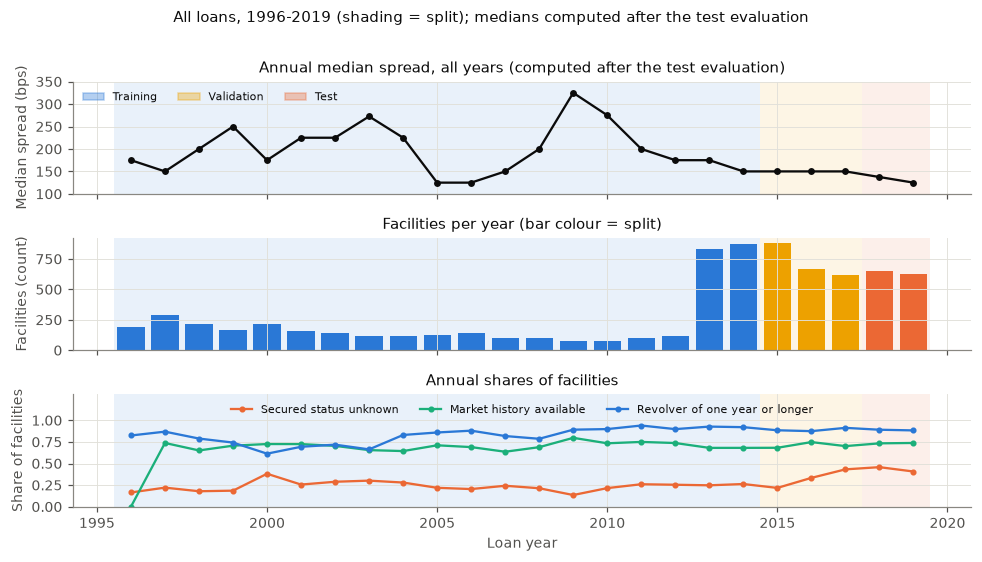

In [42]:
# Sample over time, all years (computed after the test evaluation).
_yrs = np.array(all_years)
_med = np.array([R["s4"]["median_by_year_all"][str(_y)] for _y in all_years])
_cnt = np.array([int((full["year"] == _y).sum()) for _y in all_years])
_split_of_year = full.groupby("year")["split"].agg(lambda s: s.mode().iloc[0])
fig, axes = plt.subplots(3, 1, figsize=(9.0, 5.0), sharex=True)
for _ax in axes:
    for _s in split_names:
        _ys = [int(_y) for _y in full.loc[full["split"] == _s, "year"].unique()]
        _ax.axvspan(min(_ys) - 0.5, max(_ys) + 0.5, color=SPLIT_COLORS[_s], alpha=0.10, lw=0)
axes[0].plot(_yrs, _med, marker="o", ms=3.5, color=INK)
axes[0].set_ylabel("Median spread (bps)")
_lo50, _hi50 = 50 * np.floor(_med.min() / 50), 50 * np.ceil(_med.max() / 50)
axes[0].set_yticks(np.arange(_lo50, _hi50 + 1, 50))
axes[0].set_title("Annual median spread, all years (computed after the test evaluation)")
axes[1].bar(_yrs, _cnt, color=[SPLIT_COLORS[_split_of_year.loc[_y]] for _y in all_years], width=0.8)
axes[1].set_ylabel("Facilities (count)")
axes[1].set_title("Facilities per year (bar colour = split)")
for _key, _lab, _col in (("secured_unknown", "Secured status unknown", CATEGORICAL[1]),
                         ("market_available", "Market history available", CATEGORICAL[2]),
                         ("main_revolver", "Revolver of one year or longer", CATEGORICAL[0])):
    axes[2].plot(_yrs, [R["s4"]["shares_by_year"][str(_y)][_key] for _y in all_years], marker="o", ms=3, color=_col, label=_lab)
axes[2].set_ylabel("Share of facilities")
axes[2].set_xlabel("Loan year")
axes[2].set_ylim(0, 1.3)
axes[2].set_yticks([0, 0.25, 0.5, 0.75, 1.0])
axes[2].set_title("Annual shares of facilities")
axes[2].legend(frameon=False, ncol=3, loc="upper center", fontsize=7)
_handles = [plt.Rectangle((0, 0), 1, 1, color=SPLIT_COLORS[_s], alpha=0.35) for _s in split_names]
axes[0].legend(_handles, ["Training", "Validation", "Test"], frameon=False, ncol=3, loc="upper left", fontsize=7)
fig.suptitle("All loans, 1996-2019 (shading = split); medians computed after the test evaluation", y=1.01, fontsize=10)
fig.tight_layout()
save_fig(fig, "sample_over_time")


### Pairwise comparisons on the test sample

The same borrower-clustered bootstrap as in Section 3 is applied to the refitted specifications on the test facilities: borrowers are resampled with all of their facilities, 2,000 times with seed 42, and A is the first-named (more complex) model. The interval is descriptive, not a significance test, and it does not remove dependence through common time effects. It does not change the preferred specification.

In [43]:
# Test comparisons: development refits, borrowers of the test facilities resampled.
_ = run_pairs("test", y_test.to_numpy(), TEST_PRED, test["gvkey"].to_numpy(), MAIN_PAIRS)
_first = R["boot"]["test"][MAIN_PAIRS[0]]
show(pair_view("test", MAIN_PAIRS), digits=1, index=False,
     caption=f"Test comparisons ({_first['n_obs']:,} facilities, {_first['n_clusters']:,} borrowers resampled {_first['n_boot']:,} times); "
             f"A is the first-named model")


Test comparisons (1,279 facilities, 885 borrowers resampled 2,000 times); A is the first-named model


A vs B,RMSE of A (bps),RMSE of B (bps),A minus B (bps),Relative to B (%),"95% interval, low (bps)","95% interval, high (bps)",Classification
OLS vs Constant (fitting-sample mean),54.4,74.7,-20.4,-27.3,-24.3,-16.4,A clearly lower RMSE
Ridge vs Constant (fitting-sample mean),54.4,74.7,-20.4,-27.3,-24.3,-16.4,A clearly lower RMSE
Gradient boosting vs Constant (fitting-sample mean),60.4,74.7,-14.3,-19.2,-19.1,-9.6,A clearly lower RMSE
Ridge vs OLS,54.4,54.4,0.0,0.0,0.0,0.0,about equal (within 2%)
Gradient boosting vs OLS,60.4,54.4,6.0,11.1,4.0,7.9,A clearly higher RMSE
Gradient boosting vs Ridge,60.4,54.4,6.0,11.1,4.0,7.9,A clearly higher RMSE


**Frozen choice and benchmark.** The preferred specification, Gradient boosting (depth 3, min leaf 20), was chosen on validation data and refitted on 6,326 development rows. R<sup>2</sup><sub>OOS</sub> compares squared error with the train+validation mean spread (187.5 bps), which is known before the test period. All values are in basis points (100 bps = 1 percentage point); the spread is the all-in drawn spread, which includes annual fees, not the total interest rate.

- Constant benchmark: RMSE 74.7 bps, MAE 62.2 bps. The constant benchmark is the train+validation mean benchmark itself (R<sup>2</sup><sub>OOS</sub> = 0 by construction).
- OLS: RMSE 54.4 bps, MAE 40.6 bps. OLS has R<sup>2</sup><sub>OOS</sub> = 0.471, i.e. 47.1% lower test squared error than the train+validation mean benchmark.
- Ridge (alpha = 0.01): RMSE 54.4 bps, MAE 40.6 bps. Ridge (alpha = 0.01) has R<sup>2</sup><sub>OOS</sub> = 0.471, i.e. 47.1% lower test squared error than the train+validation mean benchmark.
- Gradient boosting (depth 3, min leaf 20): RMSE 60.4 bps, MAE 46.5 bps. Gradient boosting (depth 3, min leaf 20) has R<sup>2</sup><sub>OOS</sub> = 0.347, i.e. 34.7% lower test squared error than the train+validation mean benchmark.

Gradient boosting (depth 3, min leaf 20) is substantially more accurate than the constant benchmark on the test sample (RMSE 60.4 vs 74.7 bps, 19.2% lower; the borrower-clustered bootstrap 95% interval for the difference, [-19.1, -9.6] bps, excludes zero).

**Ranking.** The order by test RMSE is Ridge and OLS (54.4 bps each, about equally accurate), then Gradient boosting (60.4 bps), so the preferred specification ranks 3 of 3 among OLS, Ridge and boosting on test RMSE. This is reported neutrally. Gradient boosting (depth 3, min leaf 20) is substantially less accurate than Ridge (alpha = 0.01) on the test sample (RMSE 60.4 vs 54.4 bps, 11.1% higher; the borrower-clustered bootstrap 95% interval for the difference, [4.0, 7.9] bps, excludes zero). Ridge (alpha = 0.01) and OLS are about equally accurate on the test sample (RMSE 54.4 vs 54.4 bps, a difference of 0.0%), so the order of those two carries no information. On validation data the preferred specification and the top test model were about equally accurate, so the validation ranking was not a clear one. The validation-selected specification stays the preferred model, as required: choosing again after seeing test results would use the test sample for selection.

**Nature of the gap.** The test mean squared error of the preferred specification exceeds that of Ridge (alpha = 0.01) by 691.5 bps². The gap is mostly a difference in level. For the preferred specification and Ridge (alpha = 0.01), respectively, mean errors (actual minus predicted) are +34.2 and +19.5 bps and squared bias is 1,170.7 and 380.4 bps², while the variance of the errors around their mean is 2,477.7 and 2,576.5 bps², 3.8% lower for the preferred specification. Of the 691.5 bps² difference, squared bias contributes +790.3 and error variance -98.8 bps². The squared bias difference is larger than the whole gap because the error variance of the preferred specification is lower. The data here do not identify why the mean errors differ, so no reason is offered.

**Levels versus validation.** The preferred specification's test RMSE (60.4 bps) is lower than its validation RMSE (70.9 bps). This goes with a change in the sample, not a gain in model quality: the benchmark falls too. The constant benchmark's RMSE falls from 95.1 to 74.7 bps, and the standard deviation of spreads is 64.2 bps in the test sample against 91.4 in validation and 117.7 in training: the spreads being predicted are less dispersed, so smaller absolute errors are expected.

**Benchmark level.** R<sup>2</sup><sub>OOS</sub> is measured against the train+validation mean of 187.5 bps, while the mean test spread is 149.1 bps; the constant's mean error is -38.4 bps (actual minus predicted), so the benchmark overpredicts on average. The squared mean error (this level shift) accounts for 26.3% of the constant's test mean squared error (squared bias 1,471.6 of 5,587.3 bps²). For the preferred specification, R<sup>2</sup><sub>OOS</sub> of 0.347 splits into 0.054 from a smaller level error than the benchmark and 0.293 from smaller errors around the mean, so most of it comes from smaller errors around the mean. The level part is the benchmark's squared mean error minus the model's, and the within part is the benchmark's error variance minus the model's, both as a share of the benchmark's test mean squared error. For OLS and Ridge (alpha = 0.01), which have the same split to three decimals, R<sup>2</sup><sub>OOS</sub> of 0.471 splits into 0.195 from a smaller level error than the benchmark and 0.275 from smaller errors around the mean, so most of it comes from smaller errors around the mean (the two parts add up to the total before rounding). As a diagnostic only, replacing the benchmark mean by the test-period mean, which was not known in advance, gives 0.114 for the preferred specification. This is not a performance measure, and it is not a split of R<sup>2</sup><sub>OOS</sub>; the split is the one above.

**By year.** The preferred specification's RMSE is 57.4 bps in 2018 (653 facilities) and 63.4 bps in 2019 (626 facilities), against 69.6 and 79.8 bps for the constant benchmark in the same years. Its RMSE as a share of the benchmark's moves from 0.824 to 0.795, a relative change of -3.6% (computed before rounding), and its R<sup>2</sup><sub>OOS</sub> is 0.320 in 2018 and 0.368 in 2019. This change is within the 5.0% threshold used to call a difference between years: relative to the benchmark the two years are similar. The higher absolute error in 2019 goes with more dispersed 2019 spreads (standard deviation 58.9 bps in 2018 and 69.3 bps in 2019).

**Dependence and limits.** The test pairs above resample 885 borrowers with all of their facilities. Facilities within a package and loans to a borrower are dependent, so row-level RMSE differences are not independent evidence; the intervals are descriptive and do not remove dependence through shocks common to all loans in a year. The test covers two loan years and one chronological split, so rankings could differ in other periods.

**Large errors.** An error counts as large when its absolute value exceeds twice the preferred specification's validation RMSE, a threshold of 141.8 bps fixed before the test targets were read. 28 test facilities (2.2% of 1,279) exceed it. 27 of 28 (96.4%) are underpredictions (actual spread above the prediction). The model also underpredicts 79.5% of the other 1,251 test facilities, so underprediction is not specific to the large errors.

Their average actual spread is 373.2 bps against an average prediction of 179.1 bps (other facilities: 144.1 and 113.5), and 57.1% of them have a spread above the 90th percentile of the development rows (other facilities: 0.6%). This group is defined by the realized spread, so it cannot be identified when a loan is priced; on the 24 test facilities above that percentile (325.0 bps) the constant benchmark's RMSE is 246.1 bps against 203.3 bps for the preferred specification. The profile table above compares each characteristic's observed count among the 28 large-error facilities with the count expected at the rate among the other facilities; a characteristic is called more (or less) frequent only when the gap is at least 3 facilities and the observed count is at least 50.0% above (or below) the expected count. Large-error facilities more often have a purpose other than corporate purposes (8 observed against 4.4 expected at the rate of the other facilities) and a realized spread above the 90th percentile of the development rows (16 observed against 0.2 expected at the rate of the other facilities; a group defined by the outcome). The other characteristics, secured status unknown (14 observed against 12.1 expected), missing market history (8 observed against 7.4 expected), missing total assets (`log_assets`; 0 observed against 0.4 expected), a loan type other than the main revolver (4 observed against 3.1 expected) and a new borrower (5 observed against 2.5 expected), occur about as often as expected given 28 facilities. With so few large-error facilities these counts are imprecise and describe association, not cause.

The largest single error is a 2019 facility (`Revolver/Line >= 1 Yr.`, secured: Yes) with an actual spread of 650.0 bps against a prediction of 239.9 bps. All ten of the largest errors are underpredictions. Credit quality beyond the 20 predictors (ratings, covenants, collateral details, market-implied spreads) is a plausible source of such misses, but the data here cannot test that.

**How the sample changes over time.** The facility count jumps from 118 in 2012 to 828 in 2013 (ratio 7.02). The reason is not documented, so this is a change in sample coverage, not a change in lending volume, and the sample is a selected linked sample, not the universe of corporate loans. The composition across splits (computed after the test evaluation, and not used to change any model) also differs:

- Spread level: the mean spread is lower in each later split, 196.5 bps in training, 170.2 bps in validation and 149.1 bps in test; annual medians range from 125.0 to 325.0 bps (highest in 2009); the 2019 median is 125.0 bps.
- Spread dispersion: the standard deviation is lower in each later split, 117.7 bps in training, 91.4 bps in validation and 64.2 bps in test. This matters for reading error levels across periods.
- Borrower size: the median `log_assets` is higher in each later split, 6.782 in training, 8.255 in validation and 8.694 in test (ln USD millions); the median `log_loan_amount` is 18.721 in training, 20.030 in validation and 20.212 in test (ln USD).
- Secured status: the share of secured loans is lower in each later split (52.9% in training, 36.6% in validation and 28.8% in test) and the share with unknown status is higher in each later split (24.5% in training, 31.5% in validation and 43.3% in test).
- Loan purpose: the share of corporate-purpose loans is higher in each later split (51.0% in training, 78.1% in validation and 83.9% in test).
- Macro conditions: mean unemployment is lower in each later split (6.062 percent in training, 4.969 percent in validation and 3.825 percent in test); mean federal funds rate 2.228 percent in training, 0.415 percent in validation and 1.990 percent in test.

These shifts mean that the later loans are not drawn from the same mix as the training loans. Whether these shifts change the model's accuracy relative to the benchmark cannot be tested with these data; facilities with unknown secured status occur among the large errors about as often as expected given 28 facilities (14 observed against 12.1 expected).

**Seen versus new borrowers.** For the preferred specification the RMSE is higher for new borrowers (67.7 bps for 116 new-borrower facilities against 59.6 bps for 1,163 seen-borrower facilities; imprecise; a relative difference of +13.6%), but the difference is not robust to resampling borrowers (95% interval [-4.8, +21.7] bps for the RMSE difference, new minus seen, 93 new and 792 seen borrowers resampled separately). Because the difference is not robust, it is not treated as evidence of weaker accuracy for new borrowers.

### Supplementary: Log-Target Ridge on the Test Sample

The log-target Ridge frozen in Section 3 is refitted on the development rows (its smearing factor is re-estimated from the development residuals) and scored once on the test rows. It is shown next to the Ridge fitted to the spread in bps. It is outside the family ranking and cannot change the preferred specification.

In [44]:
# Log-target Ridge on the test rows, next to the bps Ridge, plus the bootstrap comparison and the pair check.
supp_view = pd.DataFrame([
    {"Model": spec_label(_fam, frozen_params[_fam]), "Test RMSE (bps)": TEST_METRICS[_fam]["rmse"],
     "Test MAE (bps)": TEST_METRICS[_fam]["mae"], "R² OOS": TEST_METRICS[_fam]["r2_oos"],
     "Mean error (bps)": TEST_METRICS[_fam]["mean_error"],
     "Smearing factor": R["s4"]["ridge_log_smearing_dev"] if _fam == "ridge_log" else np.nan} for _fam in ("ridge", "ridge_log")])
show(supp_view, digits=3, index=False, caption="Test results: Ridge for the spread in bps and the supplementary log-target Ridge (mean error is actual minus predicted)")
_ = run_pairs("test", y_test.to_numpy(), TEST_PRED, test["gvkey"].to_numpy(), ["ridgelog_vs_ridge"])

# RMSE by spread level: facilities whose actual spread is above the 90th percentile of the development spreads versus the others.
R["s4"]["dev_p90"] = float(np.quantile(y_dev.to_numpy(), 0.90))
_hi = y_test.to_numpy() > R["s4"]["dev_p90"]
R["s4"]["high_spread_rmse"] = {_m: {"rmse_high": rmse(y_test.to_numpy()[_hi], TEST_PRED[_m][_hi]),
                                    "rmse_other": rmse(y_test.to_numpy()[~_hi], TEST_PRED[_m][~_hi]),
                                    "n_high": int(_hi.sum()), "n_other": int((~_hi).sum())}
                               for _m in ("constant", "ols", "ridge", "gbm", "ridge_log")}
_hs = R["s4"]["high_spread_rmse"]
R["s4"]["high_spread_rel"] = {"ridgelog_vs_ridge": {
    "rel_high": float((_hs["ridge_log"]["rmse_high"] - _hs["ridge"]["rmse_high"]) / _hs["ridge"]["rmse_high"]),
    "rel_other": float((_hs["ridge_log"]["rmse_other"] - _hs["ridge"]["rmse_other"]) / _hs["ridge"]["rmse_other"])}}
level_view = pd.DataFrame([{"Model": DISPLAY[_m], f"RMSE, actual above {R['s4']['dev_p90']:.1f} bps": _hs[_m]["rmse_high"],
                            "RMSE, other facilities": _hs[_m]["rmse_other"]} for _m in _hs])
show(level_view, digits=1, index=False,
     caption=f"Test RMSE (bps) by spread level: {_hs['ridge']['n_high']:,} facilities with an actual spread above the development 90th "
             f"percentile ({R['s4']['dev_p90']:.1f} bps) and {_hs['ridge']['n_other']:,} others")
_rel_hs = R["s4"]["high_spread_rel"]["ridgelog_vs_ridge"]
print(f"Log-target Ridge relative to the bps Ridge: {100 * _rel_hs['rel_high']:+.1f}% on the high-spread facilities, "
      f"{100 * _rel_hs['rel_other']:+.1f}% on the others.")
show(pair_view("test", ["ridgelog_vs_ridge"]), digits=1, index=False,
     caption="Test comparison of the log-target Ridge (A) with the bps Ridge (B), borrower-clustered bootstrap")
R["checks"]["bootstrap_pairs_complete"] = bool(all(
    name in R["boot"].get(sample, {}) and R["boot"][sample][name]["n_boot"] == THRESH["boot_n"]
    for sample in ("validation", "test") for name in PAIR_SPECS))
assert R["checks"]["bootstrap_pairs_complete"]
print(f"All {len(PAIR_SPECS)} comparisons are stored for the validation and test samples, each with {THRESH['boot_n']:,} bootstrap resamples.")


Test results: Ridge for the spread in bps and the supplementary log-target Ridge (mean error is actual minus predicted)


Model,Test RMSE (bps),Test MAE (bps),R² OOS,Mean error (bps),Smearing factor
Ridge (alpha = 0.01),54.378,40.556,0.471,19.505,
"Ridge, log target (alpha = 10)",51.041,34.920,0.534,14.589,1.085


Test RMSE (bps) by spread level: 24 facilities with an actual spread above the development 90th percentile (325.0 bps) and 1,255 others


Model,"RMSE, actual above 325.0 bps","RMSE, other facilities"
Constant (fitting-sample mean),246.1,67.3
OLS,199.8,47.4
Ridge,199.8,47.4
Gradient boosting,203.3,54.1
"Ridge, log target (supplementary)",208.4,42.7


Log-target Ridge relative to the bps Ridge: +4.3% on the high-spread facilities, -9.9% on the others.


Test comparison of the log-target Ridge (A) with the bps Ridge (B), borrower-clustered bootstrap


A vs B,RMSE of A (bps),RMSE of B (bps),A minus B (bps),Relative to B (%),"95% interval, low (bps)","95% interval, high (bps)",Classification
"Ridge, log target (supplementary) vs Ridge",51.0,54.4,-3.3,-6.1,-4.6,-2.1,A clearly lower RMSE


All 7 comparisons are stored for the validation and test samples, each with 2,000 bootstrap resamples.


**Log-target Ridge on the test sample (supplementary).** After the frozen refit its test RMSE is 51.0 bps and MAE 34.9 bps (the bps Ridge: 54.4 and 40.6); it has R<sup>2</sup><sub>OOS</sub> = 0.534, i.e. 53.4% lower test squared error than the train+validation mean benchmark. Its mean error is +14.6 bps (actual minus predicted), so it underpredicts on average. The refit smearing factor is 1.085. For the log-target Ridge, R<sup>2</sup><sub>OOS</sub> of 0.534 splits into 0.225 from a smaller level error than the benchmark and 0.308 from smaller errors around the mean, so most of it comes from smaller errors around the mean (the two parts add up to the total before rounding).

The log-target Ridge is more accurate than the Ridge fitted to the spread in bps on the test sample (RMSE 51.0 vs 54.4 bps, 6.1% lower; the borrower-clustered bootstrap 95% interval for the difference, [-4.6, -2.1] bps, excludes zero). On validation data its lead was not robust, so the test result is an after-the-fact observation. For reference, the preferred specification has a test RMSE of 60.4 bps.

The log-target model was frozen on validation data and scored once on the test sample; it is a supplement. It is not a candidate for the preferred specification and it does not replace it, and re-selecting on these test results would use the test sample for selection. By spread level, among the 24 test facilities with spreads above 325.0 bps (the 90th percentile of the development rows) the log-target Ridge has an RMSE of 208.4 bps against 199.8 for the bps Ridge, and among the other 1,255 facilities 42.7 bps against 47.4. The high-spread group is defined by the realized spread, so it cannot be identified when a loan is priced; the constant benchmark's RMSE on the same 24 facilities is 246.1 bps. A log target gives less weight to very high spreads, which fits this pattern (a higher RMSE on the high-spread facilities, a lower RMSE on the others); with so few high-spread facilities this is a possibility, not a tested cause.

## 5. Interpret the Results

This section studies what the validation-selected model has learned. Every analysis here uses fits made on the training rows and scores them on the validation rows (training rows are used for correlations and quintile summaries). No test row is touched: the test evaluation in Section 4 is complete and is not revisited. All error measures are in basis points (bps).

- **Information blocks.** Ridge is refit on three nested sets of predictors (loan and industry; plus borrower financials; plus market history and macroeconomy), each with its own preprocessing fitted on the training rows and its own penalty chosen on validation RMSE from the same grid.
- **Permutation importance.** Each of the 20 original predictor columns is shuffled on the validation rows and the increase in validation RMSE is recorded, using the training-fitted preferred model. Shuffling a raw column moves its dummies and, unless its missing pattern is shared with an earlier column, its missing-value indicator together.
- **Direction.** Importance does not give a direction. For the most important numeric features, partial dependence of two models, the standardized Ridge coefficient and training quintile medians are compared.

Importance and direction describe how the fitted model predicts spreads. They are predictive associations, not causal effects.

### Information blocks

Ridge is refit on three nested predictor sets, with preprocessing (caps, imputation, missing-value indicators, dummies, scaling) fitted on the training rows for exactly the columns of that set. The same penalty grid and tie rule as in Section 3 are used: the penalty with the lowest validation RMSE is chosen, and exact ties go to the larger penalty. In the comparison table, A is the larger predictor set and B the smaller one (or the constant benchmark, the training-sample mean), and the difference is RMSE(A) minus RMSE(B). The gain of each step is the fall in validation RMSE (bps) from the previous step: from the constant to the loan block, from the loan block to loan plus borrower, and from there to all predictors. Borrowers are resampled with all of their facilities (every package belongs to one borrower, as checked in Section 2); the interval is descriptive, not a significance test, and does not remove dependence through common time effects.

In [45]:
# Nested Ridge specifications, each tuned on validation RMSE with its own training-fitted preprocessing.
BLOCK_SPECS = {"a": ("Loan and industry only", FEATURES[:6]),
               "b": ("Loan and industry + borrower financials", FEATURES[:15]),
               "c": ("All 20 predictors", list(FEATURES))}
assert BLOCK_SPECS["a"][1] == BLOCKS["loan"] and BLOCK_SPECS["b"][1] == BLOCKS["loan"] + BLOCKS["borrower"]
tol = THRESH["tie_tol"]
BLOCK_FIT, BLOCK_VAL_PRED, blocks_out, block_rows = {}, {}, {}, []
for tag, (label, cols) in BLOCK_SPECS.items():
    scored = []
    for a in RIDGE_ALPHAS:
        m = fit_spec("ridge", {"alpha": a}, train[cols], y_train)
        p = m.predict(valid[cols])
        scored.append((a, m, p, rmse(y_valid, p)))
    best = min(s[3] for s in scored)
    a_sel, m_sel, p_sel, r_sel = max((s for s in scored if s[3] <= best + tol), key=lambda s: s[0])
    position = "lowest" if a_sel == min(RIDGE_ALPHAS) else ("highest" if a_sel == max(RIDGE_ALPHAS) else "interior")
    n_cols = int(m_sel.named_steps["prep"].transform(train[cols]).shape[1])
    BLOCK_FIT[tag], BLOCK_VAL_PRED[tag] = m_sel, p_sel
    blocks_out[tag] = {"features": list(cols), "n_features": len(cols), "n_cols": n_cols, "alpha": float(a_sel),
                       "alpha_position": position, "val_rmse": float(r_sel), "val_mae": mae(y_valid, p_sel),
                       "by_alpha": {f"ridge_a{s[0]:g}": float(s[3]) for s in scored}}
    block_rows.append({"specification": f"({tag}) {label}", "raw features": len(cols), "design columns": n_cols,
                       "selected alpha": a_sel,
                       "alpha position": {"lowest": "smallest penalty in grid", "interior": "interior",
                                          "highest": "largest penalty in grid"}[position],
                       "validation RMSE (bps)": r_sel, "validation MAE (bps)": blocks_out[tag]["val_mae"]})
R["s5"]["blocks"] = blocks_out

main_ridge = R["s3"]["selected"]["ridge"]
R["checks"]["block_c_equals_main_ridge"] = bool(blocks_out["c"]["alpha"] == main_ridge["alpha"]
                                                and abs(blocks_out["c"]["val_rmse"] - main_ridge["val_rmse"]) < 1e-9)
assert R["checks"]["block_c_equals_main_ridge"]

groups_valid = valid["gvkey"].to_numpy()
BLOCK_VAL_PRED["constant"] = VAL_PRED["constant"]
BLOCK_PAIRS = {"a_vs_constant": ("a", "constant"), "b_vs_a": ("b", "a"), "c_vs_b": ("c", "b")}
pair_rows = []
for pair, (ta, tb) in BLOCK_PAIRS.items():
    res = cluster_bootstrap_rmse_diff(y_valid, BLOCK_VAL_PRED[ta], BLOCK_VAL_PRED[tb], groups_valid)
    R["boot"].setdefault("blocks", {})[pair] = res
    verdict = pair_verdict(res)
    R["verdicts"].setdefault("pairs", {}).setdefault("blocks", {})[pair] = verdict
    pair_rows.append({"comparison (A vs B)": " vs ".join(t if t == "constant" else f"({t})" for t in (ta, tb)), "RMSE A (bps)": res["rmse_a"], "RMSE B (bps)": res["rmse_b"],
                      "A minus B (bps)": res["d"], "relative to B (%)": 100 * res["rel_b"],
                      "95% interval low": res["lo"], "95% interval high": res["hi"],
                      "Classification": PAIR_LABELS[verdict]})

# Nested gains in validation RMSE (bps): constant -> (a) -> (b) -> (c)
rmse_const = R["s3"]["selected"]["constant"]["val_rmse"]
nested_gain = {"a": rmse_const - blocks_out["a"]["val_rmse"], "b": blocks_out["a"]["val_rmse"] - blocks_out["b"]["val_rmse"],
               "cd": blocks_out["b"]["val_rmse"] - blocks_out["c"]["val_rmse"]}
R["s5"]["nested_gain"] = {k: float(v) for k, v in nested_gain.items()}
R["s5"]["nested_gain_top"] = max(("a", "b", "cd"), key=lambda k: (nested_gain[k], -("a", "b", "cd").index(k)))

show(pd.DataFrame(block_rows), digits=2, index=False,
     caption=f"Ridge by predictor set, fitted on {len(train):,} training rows and scored on {len(valid):,} validation rows")
show(pd.DataFrame(pair_rows), digits=2, index=False,
     caption="Change in validation RMSE when predictors are added (borrower-clustered bootstrap, "
             f"{THRESH['boot_n']:,} resamples, {len(np.unique(groups_valid)):,} borrowers)")
print(f"Gain in validation RMSE at each step: constant to (a) {nested_gain['a']:.2f} bps, (a) to (b) {nested_gain['b']:.2f} bps, "
      f"(b) to (c) {nested_gain['cd']:.2f} bps.")
print(f"Specification (c) reproduces the main Ridge selection: alpha {blocks_out['c']['alpha']:g} and validation RMSE "
      f"{blocks_out['c']['val_rmse']:.2f} bps against {main_ridge['val_rmse']:.2f} bps.")


Ridge by predictor set, fitted on 4,157 training rows and scored on 2,169 validation rows


specification,raw features,design columns,selected alpha,alpha position,validation RMSE (bps),validation MAE (bps)
(a) Loan and industry only,6,28,100.00,interior,75.49,48.32
(b) Loan and industry + borrower financials,15,45,100.00,interior,72.28,45.23
(c) All 20 predictors,20,51,0.01,smallest penalty in grid,71.88,47.51


Change in validation RMSE when predictors are added (borrower-clustered bootstrap, 2,000 resamples, 1,357 borrowers)


comparison (A vs B),RMSE A (bps),RMSE B (bps),A minus B (bps),relative to B (%),95% interval low,95% interval high,Classification
(a) vs constant,75.49,95.12,-19.63,-20.64,-21.94,-17.29,A clearly lower RMSE
(b) vs (a),72.28,75.49,-3.21,-4.25,-4.49,-2.00,A clearly lower RMSE
(c) vs (b),71.88,72.28,-0.39,-0.55,-2.24,1.24,about equal (within 2%)


Gain in validation RMSE at each step: constant to (a) 19.63 bps, (a) to (b) 3.21 bps, (b) to (c) 0.39 bps.
Specification (c) reproduces the main Ridge selection: alpha 0.01 and validation RMSE 71.88 bps against 71.88 bps.


**What each block contributes (Ridge, validation data).**

- (a) loan and industry: 6 predictors, penalty alpha = 100 (interior), validation RMSE 75.5 bps, MAE 48.3 bps
- (b) plus borrower financials: 15 predictors, penalty alpha = 100 (interior), validation RMSE 72.3 bps, MAE 45.2 bps
- (c) all four blocks: 20 predictors, penalty alpha = 0.01 (smallest on the grid), validation RMSE 71.9 bps, MAE 47.5 bps

For comparison, the constant benchmark has a validation RMSE of 95.1 bps. Specification (b), which adds borrower financials, is more accurate than specification (a), the loan and industry block alone, on the validation sample (RMSE 72.3 vs 75.5 bps, 4.3% lower; the borrower-clustered bootstrap 95% interval for the difference, [-4.5, -2.0] bps, excludes zero). In the nested Ridge comparison, Ridge with borrower financials has a clearly lower validation RMSE than with the loan and industry block alone, and the gain is robust to resampling borrowers. Specification (c), which adds market history and the macroeconomy, and specification (b) are about equally accurate on the validation sample (RMSE 71.9 vs 72.3 bps, a difference of 0.5%). In the nested Ridge comparison, adding market history and the macroeconomy gives no robust reduction in validation RMSE once the first two blocks are included. In the preferred model, the joint permutation importance of the market history block (1.4 bps against a repeat SD of 0.27 bps) exceeds its repeat-to-repeat noise, so the block is not ignored there. The MAE of (c), 47.5 bps, is higher than that of (b), 45.2 bps, so the two error measures do not both favor the larger set.

The comparison is nested, so each block's contribution is conditional on the blocks before it, and the macro variables are common to all loans in a month. Borrowers are resampled with all their facilities; the intervals are descriptive. Specification (c) reproduces the main Ridge of Section 3, as it should. Shuffling a whole block of the preferred model's validation inputs raises its RMSE most for the loan and industry block (17.5 bps, against 9.9 for borrower financials, 1.4 for market history and 0.2 for the macroeconomy), so that block has the largest joint importance. The nested Ridge comparison is consistent with this ranking but order-dependent (the block that enters first is credited with information it shares with later blocks): its validation RMSE gains over the previous step (the constant benchmark for the first) are 19.6 bps for the loan and industry block alone, 3.2 bps for adding borrower financials and 0.4 bps for adding market history and the macroeconomy, so the largest comes from the loan and industry block alone. Ridge on the loan and industry block alone is substantially more accurate than the constant benchmark on the validation sample (RMSE 75.5 vs 95.1 bps, 20.6% lower; the borrower-clustered bootstrap 95% interval for the difference, [-21.9, -17.3] bps, excludes zero). The nested comparison cannot separate market history from the macroeconomy, which enter together in its last step, and the two views come from different models (permutation importance of the preferred Gradient boosting specification, the nested comparison of Ridge).

### Permutation importance

Each of the 20 original predictor columns is shuffled on the validation rows, one column at a time, and the preferred model fitted on the training rows predicts again. The importance of a column is the average increase in validation RMSE (bps) over repeated shuffles; a value near zero means the model's validation accuracy does not depend on that column. Shuffling a raw column passes through the whole fitted pipeline, so a categorical column is shuffled as one unit and its dummies move together.

A missing-value indicator shared by several columns (identical missing patterns) is derived from the first column of its group in the feature order, so permuting that first column also moves the indicator, and the first column's importance includes the indicator's contribution. The block permutation below complements the single-column view.

In [46]:
# Permutation importance: training-fitted preferred pipeline, validation rows, the 20 original columns.
from sklearn.inspection import permutation_importance

PREF_KEY = SELECTED[PREFERRED]
PREF_PIPE = FITTED_TRAIN[PREF_KEY]
X_perm = valid[FEATURES]
baseline = rmse(y_valid, PREF_PIPE.predict(X_perm))
perm = permutation_importance(PREF_PIPE, X_perm, y_valid, scoring="neg_root_mean_squared_error",
                              n_repeats=PERM_REPEATS, random_state=SEED, n_jobs=None)
feature_block = {f: b for b, cols in BLOCKS.items() for f in cols}
perm_df = pd.DataFrame({"feature": FEATURES, "block": [feature_block[f] for f in FEATURES],
                        "mean": perm.importances_mean, "std": perm.importances_std})
perm_df = perm_df.sort_values(["mean", "feature"], ascending=[False, True], kind="stable").reset_index(drop=True)
perm_df["rank"] = np.arange(1, len(perm_df) + 1)

R["checks"]["perm_on_validation_train_fit"] = bool(
    PREF_PIPE is FITTED_TRAIN[SELECTED[PREFERRED]] and X_perm.shape == (SOURCE_FACTS["n_validation"], 20)
    and list(X_perm.columns) == FEATURES and len(y_valid) == len(X_perm)
    and perm.importances.shape == (20, PERM_REPEATS)
    and abs(baseline - R["s3"]["preferred"]["val_rmse"]) < 1e-9)
assert R["checks"]["perm_on_validation_train_fit"]

R["s5"]["baseline_val_rmse"] = float(baseline)
R["s5"]["perm"] = {r.feature: {"block": r.block, "mean": float(r.mean), "std": float(r.std), "rank": int(r.rank)}
                   for r in perm_df.itertuples()}
R["s5"]["perm_order"] = perm_df["feature"].tolist()
R["s5"]["top_numeric"] = [f for f in R["s5"]["perm_order"] if f in NUM_FEATURES][:N_TOP_NUMERIC]

show(perm_df.assign(block=perm_df["block"].map(BLOCK_LABELS))[["rank", "feature", "block", "mean", "std"]]
     .rename(columns={"block": "block", "mean": "mean increase in RMSE (bps)", "std": "SD over repeats (bps)"}),
     digits=2, index=False,
     caption=f"Permutation importance of the {spec_label(PREFERRED, R['s3']['selected'][PREFERRED])} fitted on training rows, "
             f"{len(valid):,} validation rows, {PERM_REPEATS} repeats; baseline validation RMSE {baseline:.2f} bps")
groups_shared = {k: v for k, v in R["s2"]["prep_train"]["indicator_groups"].items() if len(v) > 1}
for kept, members in groups_shared.items():
    print(f"Shared missing-value indicator: {', '.join(f'`{m}`' for m in members)} have identical missing patterns in the "
          f"training rows; the indicator is derived from `{kept}`, so permuting `{kept}` also moves it.")
if not groups_shared:
    print("No missing-value indicator is shared by several columns in the training fit.")
print("Most important columns: " + ", ".join(f"{f} ({R['s5']['perm'][f]['mean']:.1f} bps)" for f in R["s5"]["perm_order"][:5])
      + ". Numeric features examined for direction: " + ", ".join(R["s5"]["top_numeric"]) + ".")


Permutation importance of the Gradient boosting (depth 3, min leaf 20) fitted on training rows, 2,169 validation rows, 20 repeats; baseline validation RMSE 70.89 bps


rank,feature,block,mean increase in RMSE (bps),SD over repeats (bps)
1,log_loan_amount,Loan and industry,7.70,0.41
2,secured,Loan and industry,4.99,0.33
3,loan_purpose,Loan and industry,1.95,0.08
4,interest_coverage,Borrower financials,1.77,0.27
5,log_assets,Borrower financials,1.67,0.17
6,volatility_12m,Market history,0.99,0.18
7,loan_type,Loan and industry,0.98,0.17
8,net_income_assets,Borrower financials,0.84,0.14
9,maturity_months,Loan and industry,0.48,0.08
10,debt_assets,Borrower financials,0.43,0.15


Shared missing-value indicator: `sales_assets`, `net_income_assets` have identical missing patterns in the training rows; the indicator is derived from `sales_assets`, so permuting `sales_assets` also moves it.
Shared missing-value indicator: `return_12m`, `volatility_12m` have identical missing patterns in the training rows; the indicator is derived from `return_12m`, so permuting `return_12m` also moves it.
Most important columns: log_loan_amount (7.7 bps), secured (5.0 bps), loan_purpose (1.9 bps), interest_coverage (1.8 bps), log_assets (1.7 bps). Numeric features examined for direction: log_loan_amount, interest_coverage, log_assets, volatility_12m.


### Block permutation and correlated features

Importance can be shared between correlated features: shuffling one of them leaves the other available to the model. To see this, each of the four predictor blocks is shuffled jointly (all columns of the block receive the same row permutation within a repeat) and compared with the sum of the single-column importances of the block. The joint importance is called larger or smaller than the sum only if the gap is more than 10% of the sum and also larger than its noise, the square root of the block's repeat variance plus the repeat variances of its single columns. The block with the largest joint importance is the most informative block, which is then compared with the nested Ridge gains. The correlation table lists pairs of numeric features with a training Spearman correlation of at least 0.50 in absolute value.

Joint block permutation on validation rows (20 repeats)


block,columns,joint importance (bps),SD over repeats (bps),sum of single-column importances (bps),joint minus sum (bps),noise SD of the difference (bps),joint relative to sum (%),comparison,reason
Loan and industry,6,17.48,0.60,16.36,1.12,0.83,6.82,about equal,gap above noise but under 10% of the sum
Borrower financials,9,9.93,0.50,5.46,4.46,0.65,81.71,joint larger than the sum,gap above noise and above 10% of the sum
Market history,2,1.37,0.27,1.19,0.19,0.35,15.83,about equal,within noise
Macroeconomy,3,0.21,0.23,-0.19,0.40,0.27,n/a (sum not positive),about equal,single-column sum not positive


Largest joint block importance: Loan and industry (17.5 bps). Largest step in the nested Ridge fits: the loan and industry block (19.6 bps). The two views are consistent.


Numeric feature pairs with absolute training Spearman correlation of at least 0.50


feature A,feature B,Spearman correlation
log_loan_amount,log_assets,0.77
unemployment_pct,fedfunds_pct,-0.76
operating_income_assets,net_income_assets,0.72
net_income_assets,interest_coverage,0.68
operating_income_assets,interest_coverage,0.66
log_assets,volatility_12m,-0.64
log_loan_amount,volatility_12m,-0.56
debt_assets,interest_coverage,-0.52
inflation_yoy_pct,fedfunds_pct,0.51


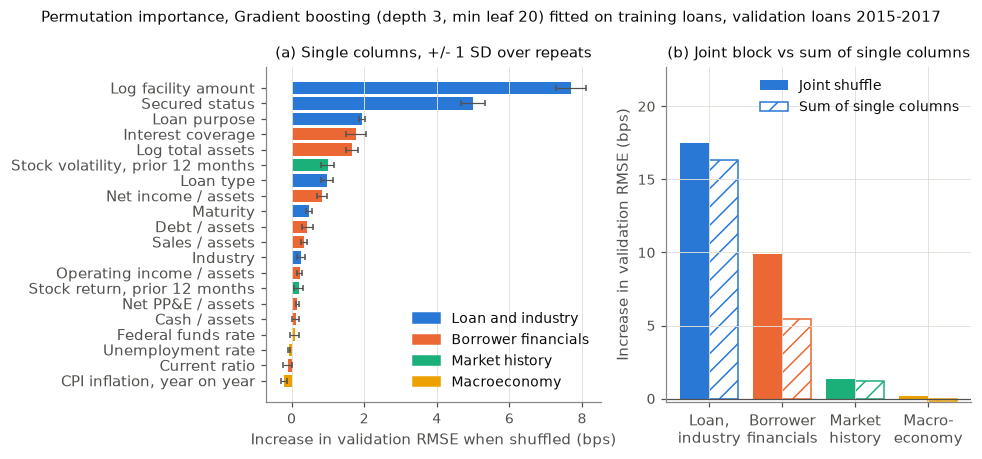

In [47]:
# Joint block permutation: same row permutation for all columns of a block within a repeat.
rng = np.random.default_rng(SEED)
block_perm = {}
for b, cols in BLOCKS.items():
    increases = []
    for _ in range(PERM_REPEATS):
        perm_idx = rng.permutation(len(valid))
        Xp = X_perm.copy()
        for c in cols:
            Xp[c] = X_perm[c].to_numpy()[perm_idx]
        increases.append(rmse(y_valid, PREF_PIPE.predict(Xp)) - baseline)
    mean_b = float(np.mean(increases))
    sum_ind = float(sum(R["s5"]["perm"][c]["mean"] for c in cols))
    rel = (mean_b - sum_ind) / sum_ind if sum_ind > 0 else 0.0
    std_b = float(np.std(increases, ddof=1))
    diff = mean_b - sum_ind
    noise_sd = float(np.sqrt(std_b ** 2 + sum(R["s5"]["perm"][c]["std"] ** 2 for c in cols)))
    block_perm[b] = {"mean": mean_b, "std": std_b, "sum_individual": sum_ind, "rel_joint_vs_sum": float(rel),
                     "joint_minus_sum": float(diff), "noise_sd": noise_sd}
    if sum_ind <= 0:
        verdict = "similar"
    elif rel > THRESH["joint_rel"] and diff > noise_sd:
        verdict = "joint_larger"
    elif rel < -THRESH["joint_rel"] and -diff > noise_sd:
        verdict = "joint_smaller"
    else:
        verdict = "similar"
    R["verdicts"].setdefault("block_sharing", {})[b] = verdict
    # Reason behind the verdict, checked in order (gap above noise but under 10% of the sum is its own case)
    if sum_ind <= 0:
        reason = "sum_not_positive"
    elif abs(diff) <= noise_sd:
        reason = "within_noise"
    elif abs(rel) <= THRESH["joint_rel"]:
        reason = "below_rel_threshold"
    else:
        reason = "both_met"
    R["verdicts"].setdefault("block_sharing_reason", {})[b] = reason
R["s5"]["block_perm"] = block_perm
top_block = max(BLOCKS, key=lambda b: (block_perm[b]["mean"], -list(BLOCKS).index(b)))
R["s5"]["most_informative_block"] = top_block
nested_expected = {"loan": "a", "borrower": "b", "market": "cd", "macro": "cd"}[top_block]
R["verdicts"]["most_informative_block"] = {
    "block": top_block, "nested_check": "consistent" if R["s5"]["nested_gain_top"] == nested_expected else "differs"}

sharing_label = {"joint_larger": "joint larger than the sum", "joint_smaller": "joint smaller than the sum", "similar": "about equal"}
reason_label = {"sum_not_positive": "single-column sum not positive", "within_noise": "within noise",
                "below_rel_threshold": "gap above noise but under 10% of the sum",
                "both_met": "gap above noise and above 10% of the sum"}
show(pd.DataFrame([{"block": BLOCK_LABELS[b], "columns": len(BLOCKS[b]), "joint importance (bps)": v["mean"],
                    "SD over repeats (bps)": v["std"], "sum of single-column importances (bps)": v["sum_individual"],
                    "joint minus sum (bps)": v["joint_minus_sum"], "noise SD of the difference (bps)": v["noise_sd"],
                    "joint relative to sum (%)": (f"{100 * v['rel_joint_vs_sum']:.2f}" if v["sum_individual"] > 0
                                                  else "n/a (sum not positive)"),
                    "comparison": sharing_label[R["verdicts"]["block_sharing"][b]],
                    "reason": reason_label[R["verdicts"]["block_sharing_reason"][b]]} for b, v in block_perm.items()]),
     digits=2, index=False, caption=f"Joint block permutation on validation rows ({PERM_REPEATS} repeats)")
nested_name = {"a": "the loan and industry block", "b": "the borrower financials", "cd": "market history and macroeconomy together"}
print(f"Largest joint block importance: {BLOCK_LABELS[top_block]} ({block_perm[top_block]['mean']:.1f} bps). "
      f"Largest step in the nested Ridge fits: {nested_name[R['s5']['nested_gain_top']]} "
      f"({R['s5']['nested_gain'][R['s5']['nested_gain_top']]:.1f} bps). The two views are "
      f"{'consistent' if R['verdicts']['most_informative_block']['nested_check'] == 'consistent' else 'not consistent'}.")

# Training Spearman correlations among the 16 numeric features (pairwise-complete)
corr = train[NUM_FEATURES].corr(method="spearman")
pairs = []
for i, fa in enumerate(NUM_FEATURES):
    for fb in NUM_FEATURES[i + 1:]:
        rho = float(corr.loc[fa, fb])
        if abs(rho) >= THRESH["corr_report"]:
            pairs.append({"a": fa, "b": fb, "rho": rho})
pairs.sort(key=lambda p: (-abs(p["rho"]), p["a"], p["b"]))
R["s5"]["corr_pairs"] = pairs
if pairs:
    show(pd.DataFrame(pairs).rename(columns={"a": "feature A", "b": "feature B", "rho": "Spearman correlation"}), digits=2,
         index=False, caption=f"Numeric feature pairs with absolute training Spearman correlation of at least {THRESH['corr_report']:.2f}")
else:
    print(f"No pair of numeric features has an absolute training Spearman correlation of at least {THRESH['corr_report']:.2f}.")

# Figure: single-column importance (a) and joint block importance versus the sum of single-column importances (b)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
ordered = perm_df.iloc[::-1]
ax1.barh([feature_label(f, unit=False) for f in ordered["feature"]], ordered["mean"], xerr=ordered["std"], color=[BLOCK_COLORS[b] for b in ordered["block"]],
         error_kw={"ecolor": INK2, "elinewidth": 0.8, "capsize": 2})
ax1.set_xlabel("Increase in validation RMSE when shuffled (bps)", fontsize=10)
ax1.set_title("(a) Single columns, +/- 1 SD over repeats", fontsize=10)
ax1.grid(axis="y", visible=False)
ax1.tick_params(axis="y", labelsize=9.5)
ax1.tick_params(axis="x", labelsize=9)
ax1.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLOCK_COLORS[b]) for b in BLOCKS], labels=[BLOCK_LABELS[b] for b in BLOCKS],
           loc="lower right", frameon=False, fontsize=9)
xpos = np.arange(len(BLOCKS))
ax2.bar(xpos - 0.2, [block_perm[b]["mean"] for b in BLOCKS], 0.4, color=[BLOCK_COLORS[b] for b in BLOCKS], label="Joint shuffle")
ax2.bar(xpos + 0.2, [block_perm[b]["sum_individual"] for b in BLOCKS], 0.4, color="white",
        edgecolor=[BLOCK_COLORS[b] for b in BLOCKS], hatch="//", label="Sum of single columns")
ax2.set_xticks(xpos)
ax2.set_xticklabels([{"loan": "Loan,\nindustry", "borrower": "Borrower\nfinancials", "market": "Market\nhistory",
                      "macro": "Macro-\neconomy"}[b] for b in BLOCKS], fontsize=9.5)
ax2.tick_params(axis="y", labelsize=9)
ax2.set_ylabel("Increase in validation RMSE (bps)", fontsize=10)
ax2.set_title("(b) Joint block vs sum of single columns", fontsize=10)
bar_vals = [v for b in BLOCKS for v in (block_perm[b]["mean"], block_perm[b]["sum_individual"])]
ax2.set_ylim(1.3 * min(0, min(bar_vals)), 1.3 * max(bar_vals))
ax2.axhline(0, color=INK2, linewidth=0.8)
ax2.legend(frameon=False, fontsize=9, loc="upper right")
fig.suptitle(f"Permutation importance, {spec_label(PREFERRED, R['s3']['selected'][PREFERRED])} fitted on training loans, validation loans 2015-2017",
             fontsize=10)
fig.tight_layout()
save_fig(fig, "permutation_importance")


**Most important variables.** Shuffling a single column of the validation rows raises the preferred model's RMSE (baseline 70.9 bps) most for `log_loan_amount` (loan and industry block, 7.7 bps), `secured` (loan and industry block, 5.0 bps), `loan_purpose` (loan and industry block, 1.9 bps), `interest_coverage` (borrower financials block, 1.8 bps) and `log_assets` (borrower financials block, 1.7 bps). At the other end are `current_ratio` (-0.1 bps, negative: shuffling it did not hurt the model) and `inflation_yoy_pct` (-0.2 bps, negative: shuffling it did not hurt the model): the model does not rely on these columns, and ranks among such small values should not be interpreted. Importance describes how much this fitted model relies on a column in the validation period.

**Correlated features share importance.** Shuffling one feature leaves its correlated partners available to the model, so a single-column importance can understate the information its group carries, and which of two correlated features receives the credit is partly arbitrary. Shuffling each block jointly shows how much is shared:

- loan and industry: joint 17.5 bps against a single-column sum of 16.4 bps; the joint importance exceeds the sum by 1.1 bps, more than the noise SD of 0.83 bps but less than 10% of the sum, so the two are close
- borrower financials: joint 9.9 bps against a single-column sum of 5.5 bps (difference computed before rounding); joint importance exceeds the sum of single-column importances by more than the repeat-to-repeat noise (+4.5 bps against a noise SD of 0.65 bps), so single-column importances understate what the block carries
- market history: joint 1.4 bps against a single-column sum of 1.2 bps; joint and summed importances are within noise of each other (+0.2 bps against a noise SD of 0.35 bps)
- macroeconomy: joint 0.2 bps against a single-column sum of -0.2 bps; the single-column sum is not positive (-0.2 bps), so the comparison with the joint importance (0.2 bps) is not informative

Among the most important variables, `log_loan_amount` (rank 1) and `log_assets` (rank 5) have a training Spearman correlation of 0.77, so part of what one carries may be credited to the other. The most strongly correlated numeric pairs in the training data are `log_loan_amount` and `log_assets` (0.77), `unemployment_pct` and `fedfunds_pct` (-0.76) and `operating_income_assets` and `net_income_assets` (0.72).

**Importance gives neither direction nor causality.** A large importance says that scrambling the column hurts the predictions; it does not say whether a higher value goes with a higher or a lower spread, and a relationship can be large but non-monotone. The next part examines direction. Importance is also a statement about this fitted model on validation data, not about how loan terms work: loan amount, maturity and secured status are negotiated jointly with the spread, so the results are predictive associations, not causal effects, and they say nothing about what would happen to a spread if a term were changed.

### Direction of the main relationships

Importance does not say whether a higher feature value goes with a higher or lower predicted spread. For the numeric features with the largest permutation importance, four views are compared: partial dependence of the preferred model, partial dependence of a comparison model (Ridge if the preferred model is boosting, boosting otherwise), the Ridge coefficient per training standard deviation of the capped, imputed feature, and training quintile medians of the observed spread. Partial dependence sets the feature to each value of a grid (training 5th to 95th percentiles) for all validation rows and averages the predictions. The change reported is the partial-dependence value at the 90th percentile of the grid minus the value at the 10th. The shape column labels a curve "monotone by rank correlation" when the absolute Spearman correlation between the grid and the curve is at least 0.90, which does not rule out a local reversal; the reversal column says "yes" when any step between adjacent grid points moves against the overall direction by more than 2 bps. For `secured`, all validation rows are set to each level in turn. A feature that moves with another feature (see the correlation table) can share or hand over its apparent effect, so these are descriptions of the fitted models, not causal effects.

Direction of the top numeric features: preferred model Gradient boosting (depth 3, min leaf 20), comparison model Ridge (alpha = 0.01); validation rows, training fits


feature,pref. model change 10th to 90th pct (bps),pref. model direction,pref. model shape,reversal over 2 bps,Ridge change (bps),Ridge coefficient per SD (bps),Ridge sign,"quintile medians, top minus bottom (bps)",quintile direction,model views
log_loan_amount,-84.86,decreasing,monotone by rank correlation,no,-96.12,-36.13,negative,-150.00,decreasing,agree
interest_coverage,-42.76,decreasing,monotone by rank correlation,yes,-2.41,-5.38,negative,-125.00,decreasing,agree
log_assets,-21.55,decreasing,monotone by rank correlation,no,-27.34,-10.35,negative,-130.00,decreasing,agree
volatility_12m,36.51,increasing,monotone by rank correlation,no,43.17,16.92,positive,150.00,increasing,agree


Training quintile medians of the observed spread (rank-based quintiles of non-missing values)


feature,quintile 1 median (bps),quintile 2 median (bps),quintile 3 median (bps),quintile 4 median (bps),quintile 5 median (bps),quintile 1 n,quintile 2 n,quintile 3 n,quintile 4 n,quintile 5 n
log_loan_amount,275.0,225.0,175.0,150.0,125.0,832,831,831,831,832
interest_coverage,275.0,200.0,150.0,150.0,150.0,697,696,697,696,697
log_assets,255.0,200.0,175.0,150.0,125.0,805,804,805,804,805
volatility_12m,125.0,150.0,175.0,200.0,275.0,552,551,552,551,552


Preferred model with every validation row set to each `secured` level


secured,average predicted spread (bps),difference from Yes (bps)
Yes,172.0,0.0
No,135.7,-36.2
Unknown,147.2,-24.8


Preferred model's average predicted spread on validation rows with the feature set to each training percentile


training percentile of the feature,log_loan_amount: preferred model's average predicted spread (bps),interest_coverage: preferred model's average predicted spread (bps),log_assets: preferred model's average predicted spread (bps),volatility_12m: preferred model's average predicted spread (bps)
5th,230.1,175.2,175.1,142.4
10th,228.2,184.1,164.7,142.4
15th,202.0,184.1,164.5,142.4
20th,202.1,184.3,164.9,142.4
25th,191.2,184.3,164.8,143.8
30th,186.6,168.1,164.8,147.1
35th,186.7,168.1,163.7,149.8
40th,181.6,155.4,163.0,153.8
45th,163.6,153.9,162.8,157.4
50th,163.4,152.2,162.2,159.5


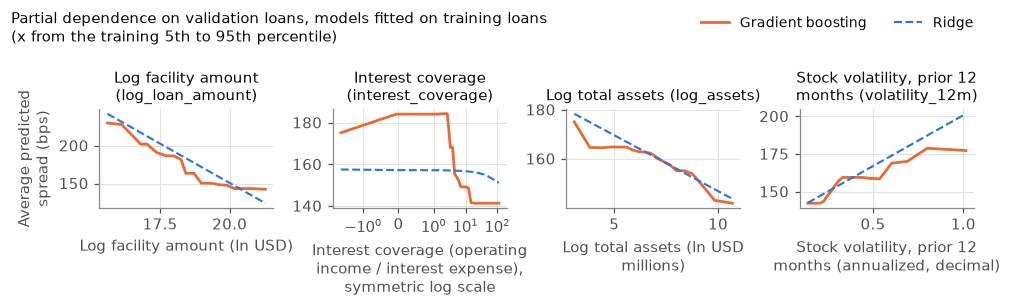

log_loan_amount: preferred model change -84.9 bps (decreasing), Ridge coefficient -36.1 bps per SD, quintile medians -150.0 bps.
interest_coverage: preferred model change -42.8 bps (decreasing), Ridge coefficient -5.4 bps per SD, quintile medians -125.0 bps.
log_assets: preferred model change -21.6 bps (decreasing), Ridge coefficient -10.3 bps per SD, quintile medians -130.0 bps.
volatility_12m: preferred model change +36.5 bps (increasing), Ridge coefficient +16.9 bps per SD, quintile medians +150.0 bps.
secured, preferred model, difference from Yes: No -36.2 bps, Unknown -24.8 bps.


In [48]:
# Direction evidence for the top numeric features.
import textwrap
from scipy.stats import spearmanr

OTHER_FAMILY = "ridge" if PREFERRED == "gbm" else "gbm"
OTHER_PIPE = FITTED_TRAIN[SELECTED[OTHER_FAMILY]]
RIDGE_PIPE = FITTED_TRAIN[SELECTED["ridge"]]
ridge_names = [str(n) for n in RIDGE_PIPE.named_steps["prep"].get_feature_names_out()]
ridge_coefs = dict(zip(ridge_names, [float(c) for c in RIDGE_PIPE.named_steps["model"].coef_]))
R["s5"]["ridge_coefs"] = ridge_coefs

lo_i, hi_i = PD_QUANTILES.index(0.1), PD_QUANTILES.index(0.9)
assert (lo_i, hi_i) == (1, 17)


def pd_curve(pipe, feature, grid):
    out = []
    for v in grid:
        Xg = valid[FEATURES].copy()
        Xg[feature] = v
        out.append(float(np.mean(pipe.predict(Xg))))
    return np.array(out)


def safe_rho(grid, curve):
    if np.ptp(curve) < 1e-9 or np.ptp(grid) < 1e-12:
        return 0.0
    return float(spearmanr(grid, curve).statistic)


direction, dir_verdicts = {}, {}
for f in R["s5"]["top_numeric"]:
    grid = np.nanquantile(train[f].to_numpy(dtype=float), PD_QUANTILES, method="linear")
    pd_pref, pd_other = pd_curve(PREF_PIPE, f, grid), pd_curve(OTHER_PIPE, f, grid)
    q = quintile_summary(train[f], y_train)
    pd_delta = float(pd_pref[hi_i] - pd_pref[lo_i])
    coef = ridge_coefs[f"num__{f}"]
    raw_delta = float(q.loc[4, "median"] - q.loc[0, "median"])
    direction[f] = {"grid": [float(v) for v in grid], "pd_pref": [float(v) for v in pd_pref],
                    "pd_other": [float(v) for v in pd_other], "other_family": OTHER_FAMILY, "pd_delta": pd_delta,
                    "pd_rho": safe_rho(grid, pd_pref), "other_pd_delta": float(pd_other[hi_i] - pd_other[lo_i]),
                    "ridge_coef_per_sd": float(coef), "raw_medians": [float(v) for v in q["median"]],
                    "raw_counts": [int(v) for v in q["n"]], "raw_delta": raw_delta}
    # Tie disclosure for the rank-based quintiles (same definitions as in Section 1).
    _xv = train[f].dropna()
    _mode = _xv.value_counts().index[0]
    direction[f]["top_value_share"] = float((_xv == _mode).mean())
    _qq = pd.qcut(_xv.rank(method="first"), 5, labels=False)
    direction[f]["straddle_share"] = float((_qq.groupby(_xv).transform("nunique") > 1).mean())
    direction[f]["ties_split"] = bool(direction[f]["straddle_share"] >= THRESH["tie_share"])
    pd_dir = "increasing" if pd_delta > THRESH["pd_flat_bps"] else ("decreasing" if pd_delta < -THRESH["pd_flat_bps"] else "flat")
    pd_shape = "flat" if pd_dir == "flat" else ("monotone" if abs(direction[f]["pd_rho"]) >= THRESH["monotone_rho"] else "non_monotone")
    ridge_sign = "positive" if coef > THRESH["ridge_flat_bps"] else ("negative" if coef < -THRESH["ridge_flat_bps"] else "near_zero")
    raw_dir = ("increasing" if raw_delta > THRESH["raw_flat_bps"] else
               ("decreasing" if raw_delta < -THRESH["raw_flat_bps"] else "flat"))
    if pd_dir == "flat" or ridge_sign == "near_zero":
        agree = "inconclusive"
    elif (pd_dir == "increasing") == (ridge_sign == "positive"):
        agree = "agree"
    else:
        agree = "disagree"
    if abs(pd_delta) > 2 * abs(direction[f]["other_pd_delta"]):
        size_vs_other = "pref_larger"
    elif abs(direction[f]["other_pd_delta"]) > 2 * abs(pd_delta):
        size_vs_other = "pref_smaller"
    else:
        size_vs_other = "similar_size"
    dir_verdicts[f] = {"pd_dir": pd_dir, "pd_shape": pd_shape, "ridge_sign": ridge_sign, "raw_dir": raw_dir, "agree": agree,
                       "size_vs_other": size_vs_other}
R["s5"]["direction"] = direction
R["verdicts"]["direction"] = dir_verdicts

# secured: all validation rows set to each level, preferred pipeline
secured_levels = ["Yes", "No", "Unknown"]
assert set(secured_levels) == set(train["secured"].unique())
secured_pd = {}
for lev in secured_levels:
    Xs = valid[FEATURES].copy()
    Xs["secured"] = lev
    secured_pd[lev] = float(np.mean(PREF_PIPE.predict(Xs)))
R["s5"]["secured_pd"] = secured_pd
R["s5"]["secured_pd_diff"] = {lev: secured_pd[lev] - secured_pd["Yes"] for lev in ("No", "Unknown")}
yes_minus_no = secured_pd["Yes"] - secured_pd["No"]
R["s5"]["secured_pd_yes_minus_no"] = float(yes_minus_no)
R["verdicts"]["secured_pd_dir"] = ("secured_higher" if yes_minus_no > THRESH["pd_flat_bps"] else
                                   ("secured_lower" if yes_minus_no < -THRESH["pd_flat_bps"] else "similar"))

shape_label = {"monotone": "monotone by rank correlation", "non_monotone": "not monotone by rank correlation", "flat": "flat"}


def has_reversal(f):
    """True if any adjacent step of the preferred model's curve moves against its direction by more than pd_flat_bps."""
    pd_dir = dir_verdicts[f]["pd_dir"]
    if pd_dir == "flat":
        return False
    sgn = 1.0 if pd_dir == "increasing" else -1.0
    c = direction[f]["pd_pref"]
    return any(sgn * (c[k + 1] - c[k]) < -THRESH["pd_flat_bps"] for k in range(len(c) - 1))


sign_label = {"positive": "positive", "negative": "negative", "near_zero": "near zero"}
other_name = DISPLAY[OTHER_FAMILY]
show(pd.DataFrame([{
    "feature": f, "pref. model change 10th to 90th pct (bps)": direction[f]["pd_delta"],
    "pref. model direction": dir_verdicts[f]["pd_dir"], "pref. model shape": shape_label[dir_verdicts[f]["pd_shape"]],
    "reversal over 2 bps": "yes" if has_reversal(f) else "no",
    f"{other_name} change (bps)": direction[f]["other_pd_delta"],
    "Ridge coefficient per SD (bps)": direction[f]["ridge_coef_per_sd"], "Ridge sign": sign_label[dir_verdicts[f]["ridge_sign"]],
    "quintile medians, top minus bottom (bps)": direction[f]["raw_delta"], "quintile direction": dir_verdicts[f]["raw_dir"],
    "model views": dir_verdicts[f]["agree"]} for f in R["s5"]["top_numeric"]]), digits=2, index=False,
    caption=f"Direction of the top numeric features: preferred model {spec_label(PREFERRED, R['s3']['selected'][PREFERRED])}, "
            f"comparison model {spec_label(OTHER_FAMILY, R['s3']['selected'][OTHER_FAMILY])}; validation rows, training fits")
show(pd.DataFrame({"feature": R["s5"]["top_numeric"] * 1,
                   **{f"quintile {k + 1} median (bps)": [direction[f]["raw_medians"][k] for f in R["s5"]["top_numeric"]] for k in range(5)},
                   **{f"quintile {k + 1} n": [direction[f]["raw_counts"][k] for f in R["s5"]["top_numeric"]] for k in range(5)}}),
     digits=1, index=False, caption="Training quintile medians of the observed spread (rank-based quintiles of non-missing values)")
show(pd.DataFrame({"secured": secured_levels, "average predicted spread (bps)": [secured_pd[l] for l in secured_levels],
                   "difference from Yes (bps)": [secured_pd[l] - secured_pd["Yes"] for l in secured_levels]}),
     digits=1, index=False, caption=f"Preferred model with every validation row set to each `secured` level")

show(pd.DataFrame({"training percentile of the feature": [f"{round(100 * q)}th" for q in PD_QUANTILES],
                   **{f"{f}: preferred model's average predicted spread (bps)": direction[f]["pd_pref"] for f in R["s5"]["top_numeric"]}}),
     digits=1, index=False, caption="Preferred model's average predicted spread on validation rows with the feature set to each training percentile")

# Figure: partial dependence of the preferred and comparison models
fig, axes = plt.subplots(1, len(R["s5"]["top_numeric"]), figsize=(9.0, 2.8))
for ax, f in zip(np.atleast_1d(axes), R["s5"]["top_numeric"]):
    d = direction[f]
    ax.plot(d["grid"], d["pd_pref"], color=FAMILY_COLORS[PREFERRED], lw=1.8, label=DISPLAY[PREFERRED])
    ax.plot(d["grid"], d["pd_other"], color=FAMILY_COLORS[OTHER_FAMILY], lw=1.4, ls="--", label=DISPLAY[OTHER_FAMILY])
    xl = feature_label(f)
    if f in SYMLOG_FEATURES:
        ax.set_xscale("symlog", linthresh=1.0)
        xl += ", symmetric log scale"
    ax.set_xlabel(textwrap.fill(xl, 30), fontsize=10)
    ax.tick_params(labelsize=9.5)
    ax.set_title(textwrap.fill(f"{FEATURE_LABELS[f][0]} ({f})", 30), fontsize=9.5)
np.atleast_1d(axes)[0].set_ylabel("Average predicted\nspread (bps)", fontsize=10)
_h, _l = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(_h, _l, loc="upper right", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Partial dependence on validation loans, models fitted on training loans\n(x from the training 5th to 95th percentile)", fontsize=10, x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "partial_dependence")
for f in R["s5"]["top_numeric"]:
    v = dir_verdicts[f]
    print(f"{f}: preferred model change {direction[f]['pd_delta']:+.1f} bps ({v['pd_dir']}), "
          f"Ridge coefficient {direction[f]['ridge_coef_per_sd']:+.1f} bps per SD, quintile medians {direction[f]['raw_delta']:+.1f} bps.")
print("secured, preferred model, difference from Yes: " + ", ".join(f"{l} {R['s5']['secured_pd_diff'][l]:+.1f} bps" for l in ("No", "Unknown")) + ".")


**Direction of the main relationships** (validation rows, training fits):

- **`log_loan_amount`.** *Expected channel:* larger facilities tend to go to larger, more established borrowers and benefit from scale, so a lower spread is plausible. *Computed:* in the preferred model, moving `log_loan_amount` from its training 10th to 90th percentile changes the average predicted spread by -84.9 bps (higher `log_loan_amount` goes with lower predicted spreads); the Ridge coefficient points the same way (-36.1 bps per SD); training quintile medians move by -150.0 bps from the lowest to the highest quintile (falling; 7.2% of training loans with a `log_loan_amount` value have a value shared with loans in another quintile and tied loans are assigned to quintiles in file order, which follows the origination date). The preferred model's partial dependence is decreasing, which agrees with the expected sign. For comparison, the same move changes the average prediction of Ridge by -96.1 bps.
- **`interest_coverage`.** *Expected channel:* a borrower that covers its interest payments more easily has lower credit risk. *Computed:* in the preferred model, moving `interest_coverage` from its training 10th to 90th percentile changes the average predicted spread by -42.8 bps (higher `interest_coverage` goes with lower predicted spreads); the Ridge coefficient points the same way (-5.4 bps per SD); training quintile medians move by -125.0 bps from the lowest to the highest quintile (falling). The preferred model's partial dependence is decreasing, which agrees with the expected sign. Over part of the grid the preferred model's curve also moves against this direction: it rises from 175.2 bps at the 5th percentile to 184.1 bps at the 10th before falling to 141.4 bps at the 95th. For comparison, the same move changes the average prediction of Ridge by -2.4 bps.
- **`log_assets`.** *Expected channel:* larger borrowers are usually more diversified and have wider access to capital markets, which points to lower credit risk and a lower spread. *Computed:* in the preferred model, moving `log_assets` from its training 10th to 90th percentile changes the average predicted spread by -21.6 bps (higher `log_assets` goes with lower predicted spreads); the Ridge coefficient points the same way (-10.3 bps per SD); training quintile medians move by -130.0 bps from the lowest to the highest quintile (falling). The preferred model's partial dependence is decreasing, which agrees with the expected sign. For comparison, the same move changes the average prediction of Ridge by -27.3 bps.
- **`volatility_12m`.** *Expected channel:* higher equity volatility signals higher risk. *Computed:* in the preferred model, moving `volatility_12m` from its training 10th to 90th percentile changes the average predicted spread by +36.5 bps (higher `volatility_12m` goes with higher predicted spreads); the Ridge coefficient points the same way (+16.9 bps per SD); training quintile medians move by +150.0 bps from the lowest to the highest quintile (rising). The preferred model's partial dependence is increasing, which agrees with the expected sign. For comparison, the same move changes the average prediction of Ridge by +43.2 bps.
- **`secured`.** *Computed:* with every validation facility set to unsecured the preferred model's average prediction is 135.7 bps, 36.2 bps below the 172.0 bps when every facility is set to secured (difference computed before rounding); for unknown status it is 147.2 bps (-24.8 bps from secured). For comparison, the training medians of Section 1 had secured loans higher. The preferred model has secured loans priced higher, which is consistent with the second channel (collateral requested from riskier borrowers) outweighing the first (lower loss given default); it does not measure the effect of collateral.

The comparison model moves the same way as the preferred model for every numeric feature above, but the sizes differ strongly: for `interest_coverage` the same move changes the average prediction by -42.8 bps in the preferred model and -2.4 bps in Ridge, so the preferred model's change is more than twice as large. For that feature, how strongly it matters depends on the model class, even where the sign is shared. In every case these are descriptions of fitted models and observational associations, not causal effects. Contract terms such as loan size and secured status are set jointly with the spread, while borrower and market characteristics are observed, not assigned, and may move with unobserved credit quality (the data cannot test this). Correlated features can hand over part of their apparent pattern to each other, for example `log_loan_amount` and `log_assets` (Spearman 0.77), and `net_income_assets` and `interest_coverage` (Spearman 0.68), so the direction of each is best read together with the others, and partial dependence averages over combinations of feature values that may be rare.

### Assessment

**Where the model adds value.** Gradient boosting (depth 3, min leaf 20) has R<sup>2</sup><sub>OOS</sub> = 0.347, i.e. 34.7% lower test squared error than the train+validation mean benchmark. Gradient boosting (depth 3, min leaf 20) is substantially more accurate than the constant benchmark on the test sample (RMSE 60.4 vs 74.7 bps, 19.2% lower; the borrower-clustered bootstrap 95% interval for the difference, [-19.1, -9.6] bps, excludes zero). On this evidence it adds predictive value over quoting the historical mean for later loans to the observed borrower population. For context, Ridge (alpha = 0.01) has R<sup>2</sup><sub>OOS</sub> = 0.471, i.e. 47.1% lower test squared error than the train+validation mean benchmark. Shuffling a whole block of the preferred model's validation inputs raises its RMSE most for the loan and industry block (17.5 bps, against 9.9 for borrower financials, 1.4 for market history and 0.2 for the macroeconomy), so that block has the largest joint importance. The nested Ridge comparison is consistent with this but order-dependent. The nested comparison cannot separate market history from the macroeconomy, which enter together in its last step, and the two views come from different models (permutation importance of the preferred Gradient boosting specification, the nested comparison of Ridge). In the nested Ridge comparison, Ridge with borrower financials has a clearly lower validation RMSE than with the loan block alone. The preferred model relies most on `log_loan_amount` (7.7 bps) and `secured` (5.0 bps), followed by `loan_purpose`, `interest_coverage` and `log_assets` (1.9, 1.8 and 1.7 bps), without a claim about their order. Relative to the benchmark the two test years are similar (RMSE 57.4 bps in 2018 and 63.4 bps in 2019, against 69.6 and 79.8 bps for the constant benchmark; R<sup>2</sup><sub>OOS</sub> 0.320 and 0.368). The higher absolute error in 2019 goes with more dispersed 2019 spreads (standard deviation 58.9 bps in 2018 and 69.3 bps in 2019).

**Where it is unreliable.**

- **Level of the errors.** The preferred specification underpredicts later loans in general: mean error +34.2 bps (actual minus predicted), 79.9% of test facilities underpredicted, and the squared mean error is 32.1% of its test mean squared error.
- **Large errors.** 28 of 1,279 test facilities (2.2%) have errors above 141.8 bps: 27 of 28 (96.4%) are underpredictions (actual spread above the prediction); the model also underpredicts 79.5% of the other 1,251 test facilities, so underprediction is not specific to the large errors; compared with the other facilities, large errors more often involve a purpose other than corporate purposes (8 observed against 4.4 expected at the rate of the other facilities) and a realized spread above the 90th percentile of the development rows (16 observed against 0.2 expected at the rate of the other facilities; a group defined by the outcome).
- **Highest-spread loans.** Absolute errors are largest on loans whose realized spread turned out highest: the preferred model's RMSE is 203.3 bps for the 24 test facilities above 325.0 bps (the development 90th percentile) against 54.1 bps for the other 1,255. This group is defined by the realized spread, so it cannot be identified when a loan is priced, and the constant benchmark's RMSE on the same 24 loans is 246.1 bps.
- **Model choice.** On the test sample the validation-selected specification has the highest RMSE of the three; Gradient boosting (depth 3, min leaf 20) is substantially less accurate than Ridge (alpha = 0.01) on the test sample (RMSE 60.4 vs 54.4 bps, 11.1% higher; the borrower-clustered bootstrap 95% interval for the difference, [4.0, 7.9] bps, excludes zero); it is kept as required. On validation data the margin was small and not robust. The ranking of the three models should not be treated as stable.

**What a real lending application would need.** Credit ratings and market-implied credit spreads (for example from bonds or credit default swaps), covenant and collateral details, fees reported separately from the spread, syndicate and relationship information, point-in-time filings with data vintages, coverage of private firms, and loan outcomes (defaults and losses), so that pricing can be judged against realized risk. The 20 predictors here cannot supply these.

**Limits of the exercise.**

- **Level of the benchmark.** The mean test spread (149.1 bps) is below the train+validation mean used as benchmark (187.5 bps); the constant's squared mean error (its level shift) accounts for 26.3% of its test mean squared error. For the preferred specification, R<sup>2</sup><sub>OOS</sub> of 0.347 splits into 0.054 from a smaller level error than the benchmark and 0.293 from smaller errors around the mean, so most of it comes from smaller errors around the mean. For Ridge (alpha = 0.01), R<sup>2</sup><sub>OOS</sub> of 0.471 splits into 0.195 from a smaller level error than the benchmark and 0.275 from smaller errors around the mean, so most of it comes from smaller errors around the mean (the two parts add up to the total before rounding). As a diagnostic only, measured against the test-period mean, which was not known in advance, the preferred specification's value is 0.114. The spread dispersion is lower in each later split (standard deviation 117.7, 91.4 and 64.2 bps in training, validation and test), so absolute errors are not comparable across periods.
- **Retrospective data.** This is a retrospective pricing exercise, not a verified live underwriting backtest and not an automated lending decision. The six-month accounting delay is an assumed availability rule, not an observed filing date; statements are 6 to 18 months old at origination; Compustat and FRED values may have been revised and the borrower links and industry codes are retrospective.
- **Representativeness.** The sample is a selected linked sample, not the loan universe, and its facility count jumps from 118 in 2012 to 828 in 2013, a change in coverage rather than lending volume.
- **Repeated borrowers.** 792 of 885 test borrowers (89.5%) and 1,163 test facilities (90.9%) belong to borrowers seen before, so the results describe later loans to the observed borrower population, not to new firms. For the preferred specification, the RMSE is higher for new borrowers (67.7 bps for 116 new-borrower facilities against 59.6 bps for 1,163 seen-borrower facilities; imprecise; a relative difference of +13.6%), but the difference is not robust to resampling borrowers (95% interval [-4.8, +21.7] bps for the RMSE difference, new minus seen, 93 new and 792 seen borrowers resampled separately).
- **Dependence.** Facilities within a package and repeated loans to a borrower are dependent. Row-level performance differences are therefore not independent evidence; the borrower-clustered bootstrap is a descriptive check and ignores shocks common to all loans in a period. There is one chronological split, with three validation and two test years.
- **Missing features.** Market history is missing for 31.16% of facilities and `current_ratio` for 19.45%, and secured status is unknown for 43.3% of test facilities. Imputation with indicators keeps the loans, but missingness is not random and the missing information cannot be recovered.

All results are predictive associations in bps of the all-in drawn spread (which includes annual fees and is not the total interest rate); they are not causal effects.

## Appendix: Reproducibility Checks and Results Export

The table lists the integrity checks run during the notebook (data counts, leakage-safe preprocessing, the test lock and the frozen choices, equal test facilities). The final cell writes every stored result to `results_summary.json`.

In [49]:
# Reproducibility checks: every registered check must hold.
CHECK_DESCRIPTIONS = {
    "facility_id_unique": "Facility identifiers are unique",
    "documented_counts_match": "Row count, split sizes and target completeness match the documentation",
    "no_rows_dropped": "No rows were dropped when building the training, validation and test frames",
    "medians_unaffected_by_caps": "Imputation medians equal the raw training medians",
    "ols_full_rank_train": "OLS design matrix has full column rank (training fit)",
    "ols_full_rank_dev": "OLS design matrix has full column rank (development refit)",
    "log_ridge_not_in_selection": "The log-target Ridge never entered model selection",
    "test_locked_until_freeze": "No test-period target was read before the freeze",
    "freeze_digest_unchanged": "Frozen choices were unchanged when the test rows were scored",
    "same_test_facilities": "All models were scored on the same test facilities",
    "test_rows_complete": "All test rows were scored with finite predictions",
    "r2_oos_constant_zero": "R\u00b2 OOS of the refit constant benchmark is zero",
    "documented_missing_match": "Missing-value counts match the documentation",
    "chronological_separation": "Training, validation and test periods are chronologically separated",
    "split_label_matches_year": "Split labels follow the year rule",
    "no_package_crosses_splits": "No loan package appears in more than one split",
    "packages_nest_in_borrowers": "Every loan package belongs to exactly one borrower",
    "timing_rules_hold": "Accounting, market and macro timing rules hold for every row",
    "unseen_mapped_to_pooled": "Unseen validation categories map to the pooled column",
    "bootstrap_pairs_complete": "All seven bootstrap comparisons exist on validation and test",
    "block_c_equals_main_ridge": "The all-predictor block Ridge reproduces the main Ridge selection",
    "perm_on_validation_train_fit": "Permutation importance uses the training-fitted preferred model on validation rows",
    "mse_decomposition_consistent": "Squared-bias plus error-variance split of the test MSE matches the direct computation",
    "r2_oos_parts_sum": "The level and within parts of each out-of-sample R-squared add up to the reported value",
}
R["s4"]["test_target_reads"] = int(_LOCK["test_reads"])
status = {}
for name in CHECK_DESCRIPTIONS:
    status[name] = R["checks"].get(name, None)
check_table = pd.DataFrame({"check": list(CHECK_DESCRIPTIONS), "description": list(CHECK_DESCRIPTIONS.values()),
                            "passed": ["not run" if v is None else ("yes" if v else "NO") for v in status.values()]})
failed = [k for k, v in status.items() if v is not True]
reads_ok = R["s4"]["test_target_reads"] == 2
R["checks"]["all_passed"] = bool(not failed and reads_ok)
print(f"Checks passed: {sum(v is True for v in status.values())} of {len(status)}; test-period targets were read "
      f"{R['s4']['test_target_reads']} times (expected 2: the test scoring and the post-test sample description).")
show(check_table, index=False)
assert not failed, f"failed or missing checks: {failed}"
assert reads_ok, f"unexpected number of test-target reads: {R['s4']['test_target_reads']}"
print("All reproducibility checks passed.")


Checks passed: 24 of 24; test-period targets were read 2 times (expected 2: the test scoring and the post-test sample description).


check,description,passed
facility_id_unique,Facility identifiers are unique,yes
documented_counts_match,"Row count, split sizes and target completeness match the documentation",yes
no_rows_dropped,"No rows were dropped when building the training, validation and test frames",yes
medians_unaffected_by_caps,Imputation medians equal the raw training medians,yes
ols_full_rank_train,OLS design matrix has full column rank (training fit),yes
ols_full_rank_dev,OLS design matrix has full column rank (development refit),yes
log_ridge_not_in_selection,The log-target Ridge never entered model selection,yes
test_locked_until_freeze,No test-period target was read before the freeze,yes
freeze_digest_unchanged,Frozen choices were unchanged when the test rows were scored,yes
same_test_facilities,All models were scored on the same test facilities,yes


All reproducibility checks passed.


In [50]:
# Export the results dictionary: sorted keys, no missing numbers.
def _find_bad(obj, path=""):
    if isinstance(obj, dict):
        return [p for k, v in obj.items() for p in _find_bad(v, f"{path}.{k}")]
    if isinstance(obj, (list, tuple)):
        return [p for i, v in enumerate(obj) for p in _find_bad(v, f"{path}[{i}]")]
    if isinstance(obj, (float, np.floating)) and not np.isfinite(obj):
        return [path]
    return []


payload = to_py(R)
bad = _find_bad(payload)
assert not bad, f"non-finite numbers in results: {bad[:5]}"
with open("results_summary.json", "w") as f:
    json.dump(payload, f, indent=2, sort_keys=True)
print(f"Wrote results_summary.json with {len(payload)} top-level groups ({', '.join(sorted(payload))}); all numbers are finite.")


Wrote results_summary.json with 10 top-level groups (boot, checks, freeze, meta, s1, s2, s3, s4, s5, verdicts); all numbers are finite.
